### Dataset source
https://research.unsw.edu.au/projects/unsw-nb15-dataset

### Import Libraries

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

### Load train and test datasets

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

train = pd.read_csv('/content/drive/MyDrive/UNSW_NB15_training-set.csv')
test = pd.read_csv('/content/drive/MyDrive/UNSW_NB15_testing-set.csv')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Combined Data

In [ ]:
combined_data = pd.concat([train, test], ignore_index=True)

### Basic inspection

In [ ]:
combined_data.shape

(257673, 45)

In [ ]:
combined_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 257673 entries, 0 to 257672
Data columns (total 45 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 257673 non-null  int64  
 1   dur                257673 non-null  float64
 2   proto              257673 non-null  object 
 3   service            257673 non-null  object 
 4   state              257673 non-null  object 
 5   spkts              257673 non-null  int64  
 6   dpkts              257673 non-null  int64  
 7   sbytes             257673 non-null  int64  
 8   dbytes             257673 non-null  int64  
 9   rate               257673 non-null  float64
 10  sttl               257673 non-null  int64  
 11  dttl               257673 non-null  int64  
 12  sload              257673 non-null  float64
 13  dload              257673 non-null  float64
 14  sloss              257673 non-null  int64  
 15  dloss              257673 non-null  int64  
 16  si

### Check missing values

In [ ]:
print("Missing values in Combined DataFrame:")
print(combined_data.isnull().sum())

Missing values in Combined DataFrame:
id                   0
dur                  0
proto                0
service              0
state                0
spkts                0
dpkts                0
sbytes               0
dbytes               0
rate                 0
sttl                 0
dttl                 0
sload                0
dload                0
sloss                0
dloss                0
sinpkt               0
dinpkt               0
sjit                 0
djit                 0
swin                 0
stcpb                0
dtcpb                0
dwin                 0
tcprtt               0
synack               0
ackdat               0
smean                0
dmean                0
trans_depth          0
response_body_len    0
ct_srv_src           0
ct_state_ttl         0
ct_dst_ltm           0
ct_src_dport_ltm     0
ct_dst_sport_ltm     0
ct_dst_src_ltm       0
is_ftp_login         0
ct_ftp_cmd           0
ct_flw_http_mthd     0
ct_src_ltm           0
ct_srv_dst         

### Remove duplicates

In [ ]:
print(f"Original shape of combined_data: {combined_data.shape}")
combined_data.drop_duplicates(inplace=True)
print(f"Shape of combined_data after removing duplicates: {combined_data.shape}")

Original shape of combined_data: (257673, 45)
Shape of combined_data after removing duplicates: (257673, 45)


### Class Distribution

In [ ]:
print("Class Distribution (Counts):")
print(combined_data['label'].value_counts())

print("\nClass Distribution (Percentages):")
print(combined_data['label'].value_counts(normalize=True) * 100)

Class Distribution (Counts):
label
1    164673
0     93000
Name: count, dtype: int64

Class Distribution (Percentages):
label
1    63.907744
0    36.092256
Name: proportion, dtype: float64


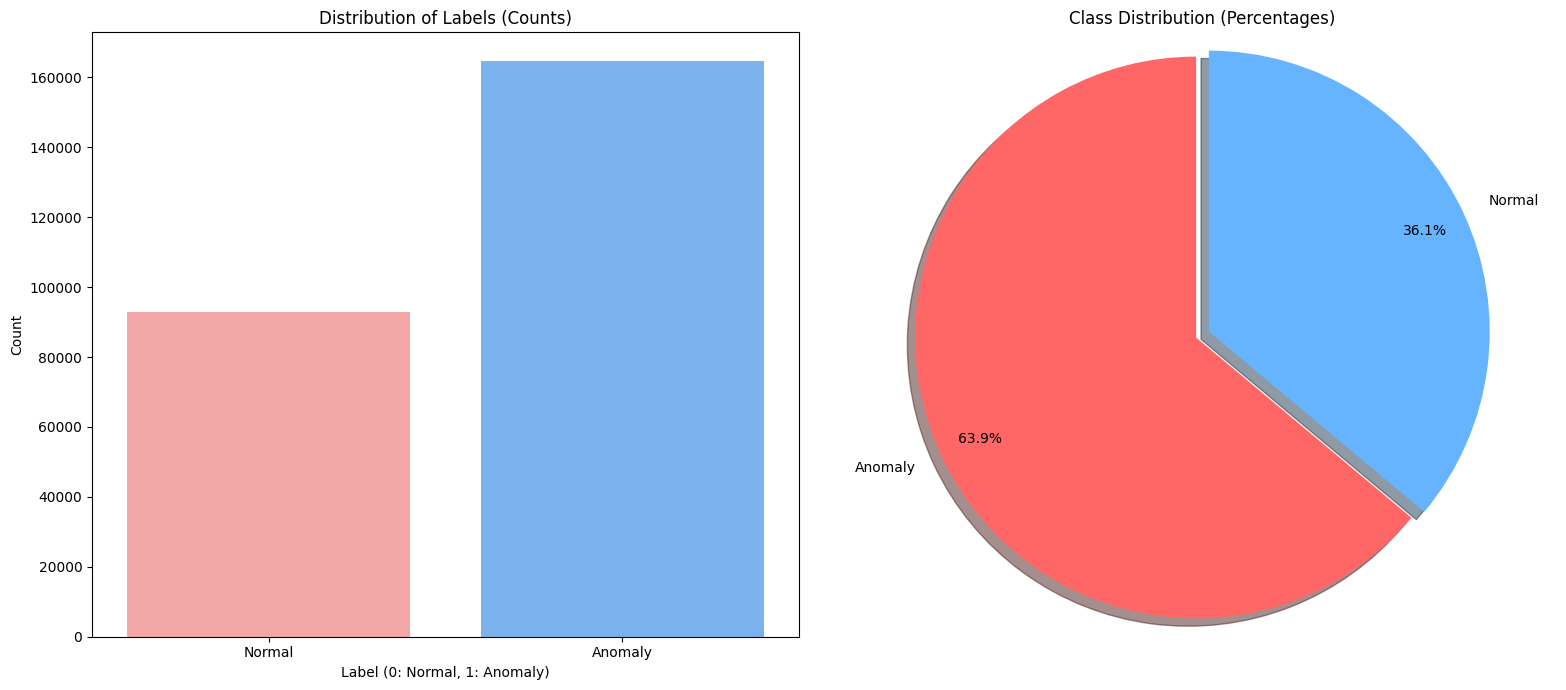

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Get class counts and percentages
class_counts = combined_data['label'].value_counts()
class_percentages = combined_data['label'].value_counts(normalize=True) * 100

# Define labels and colors
labels = ['Anomaly', 'Normal'] # Assuming 1 is Anomaly and 0 is Normal based on previous output
explode = (0.05, 0) # Explode the 'Anomaly' slice for emphasis
colors_pie = ['#ff6666','#66b3ff'] # Red for Anomaly, Blue for Normal for pie chart
colors_bar = ['#FF9999', '#66B2FF'] # Slightly different shades for bar chart

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Plot 1: Countplot
sns.countplot(x='label', data=combined_data, palette=colors_bar, ax=axes[0])
axes[0].set_title('Distribution of Labels (Counts)')
axes[0].set_xlabel('Label (0: Normal, 1: Anomaly)')
axes[0].set_ylabel('Count')
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['Normal', 'Anomaly'])

# Plot 2: Pie Chart for Percentages
axes[1].pie(class_percentages, explode=explode, labels=labels, colors=colors_pie, autopct='%1.1f%%',
            shadow=True, startangle=90, pctdistance=0.85)
axes[1].set_title('Class Distribution (Percentages)')
axes[1].axis('equal') # Equal aspect ratio ensures that pie is drawn as a circle.

plt.tight_layout()
plt.show()

### Attack Category Distribution

Attack Category Distribution (Counts):
attack_cat
Normal            93000
Generic           58871
Exploits          44525
Fuzzers           24246
DoS               16353
Reconnaissance    13987
Analysis           2677
Backdoor           2329
Shellcode          1511
Worms               174
Name: count, dtype: int64

Attack Category Distribution (Percentages):
attack_cat
Normal            36.092256
Generic           22.847175
Exploits          17.279653
Fuzzers            9.409601
DoS                6.346416
Reconnaissance     5.428198
Analysis           1.038914
Backdoor           0.903859
Shellcode          0.586402
Worms              0.067527
Name: proportion, dtype: float64


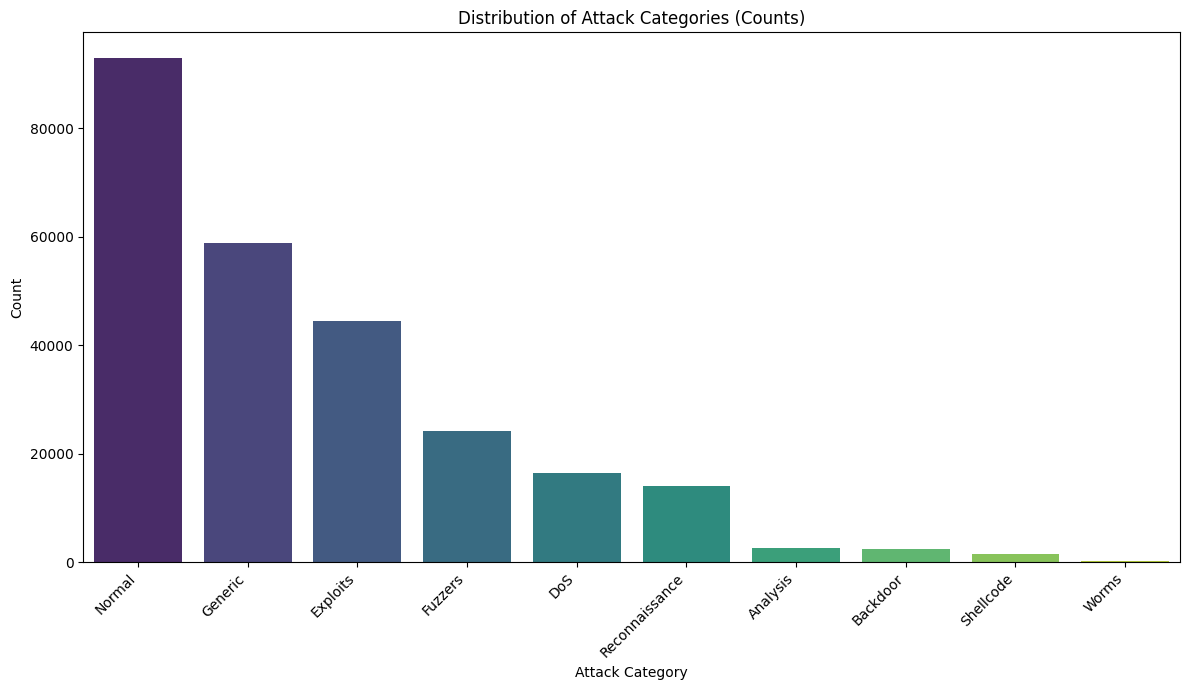

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Get attack category counts and percentages
attack_cat_counts = combined_data['attack_cat'].value_counts()
attack_cat_percentages = combined_data['attack_cat'].value_counts(normalize=True) * 100

print("Attack Category Distribution (Counts):")
print(attack_cat_counts)

print("\nAttack Category Distribution (Percentages):")
print(attack_cat_percentages)

# Plot the distribution of Attack Categories
plt.figure(figsize=(12, 7))
sns.countplot(x='attack_cat', data=combined_data, order=attack_cat_counts.index, palette='viridis')
plt.title('Distribution of Attack Categories (Counts)')
plt.xlabel('Attack Category')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right') # Rotate x-axis labels for better readability
plt.tight_layout()
plt.show()

### Drop unnecessary columns

In [ ]:
print(f"Shape of combined_data before dropping 'id' and 'attack_cat': {combined_data.shape}")
combined_data.drop(['id', 'attack_cat'], axis=1, inplace=True)
print(f"Shape of combined_data after dropping 'id' and 'attack_cat': {combined_data.shape}")

Shape of combined_data before dropping 'id' and 'attack_cat': (257673, 45)
Shape of combined_data after dropping 'id' and 'attack_cat': (257673, 43)


### Correlation Analysis

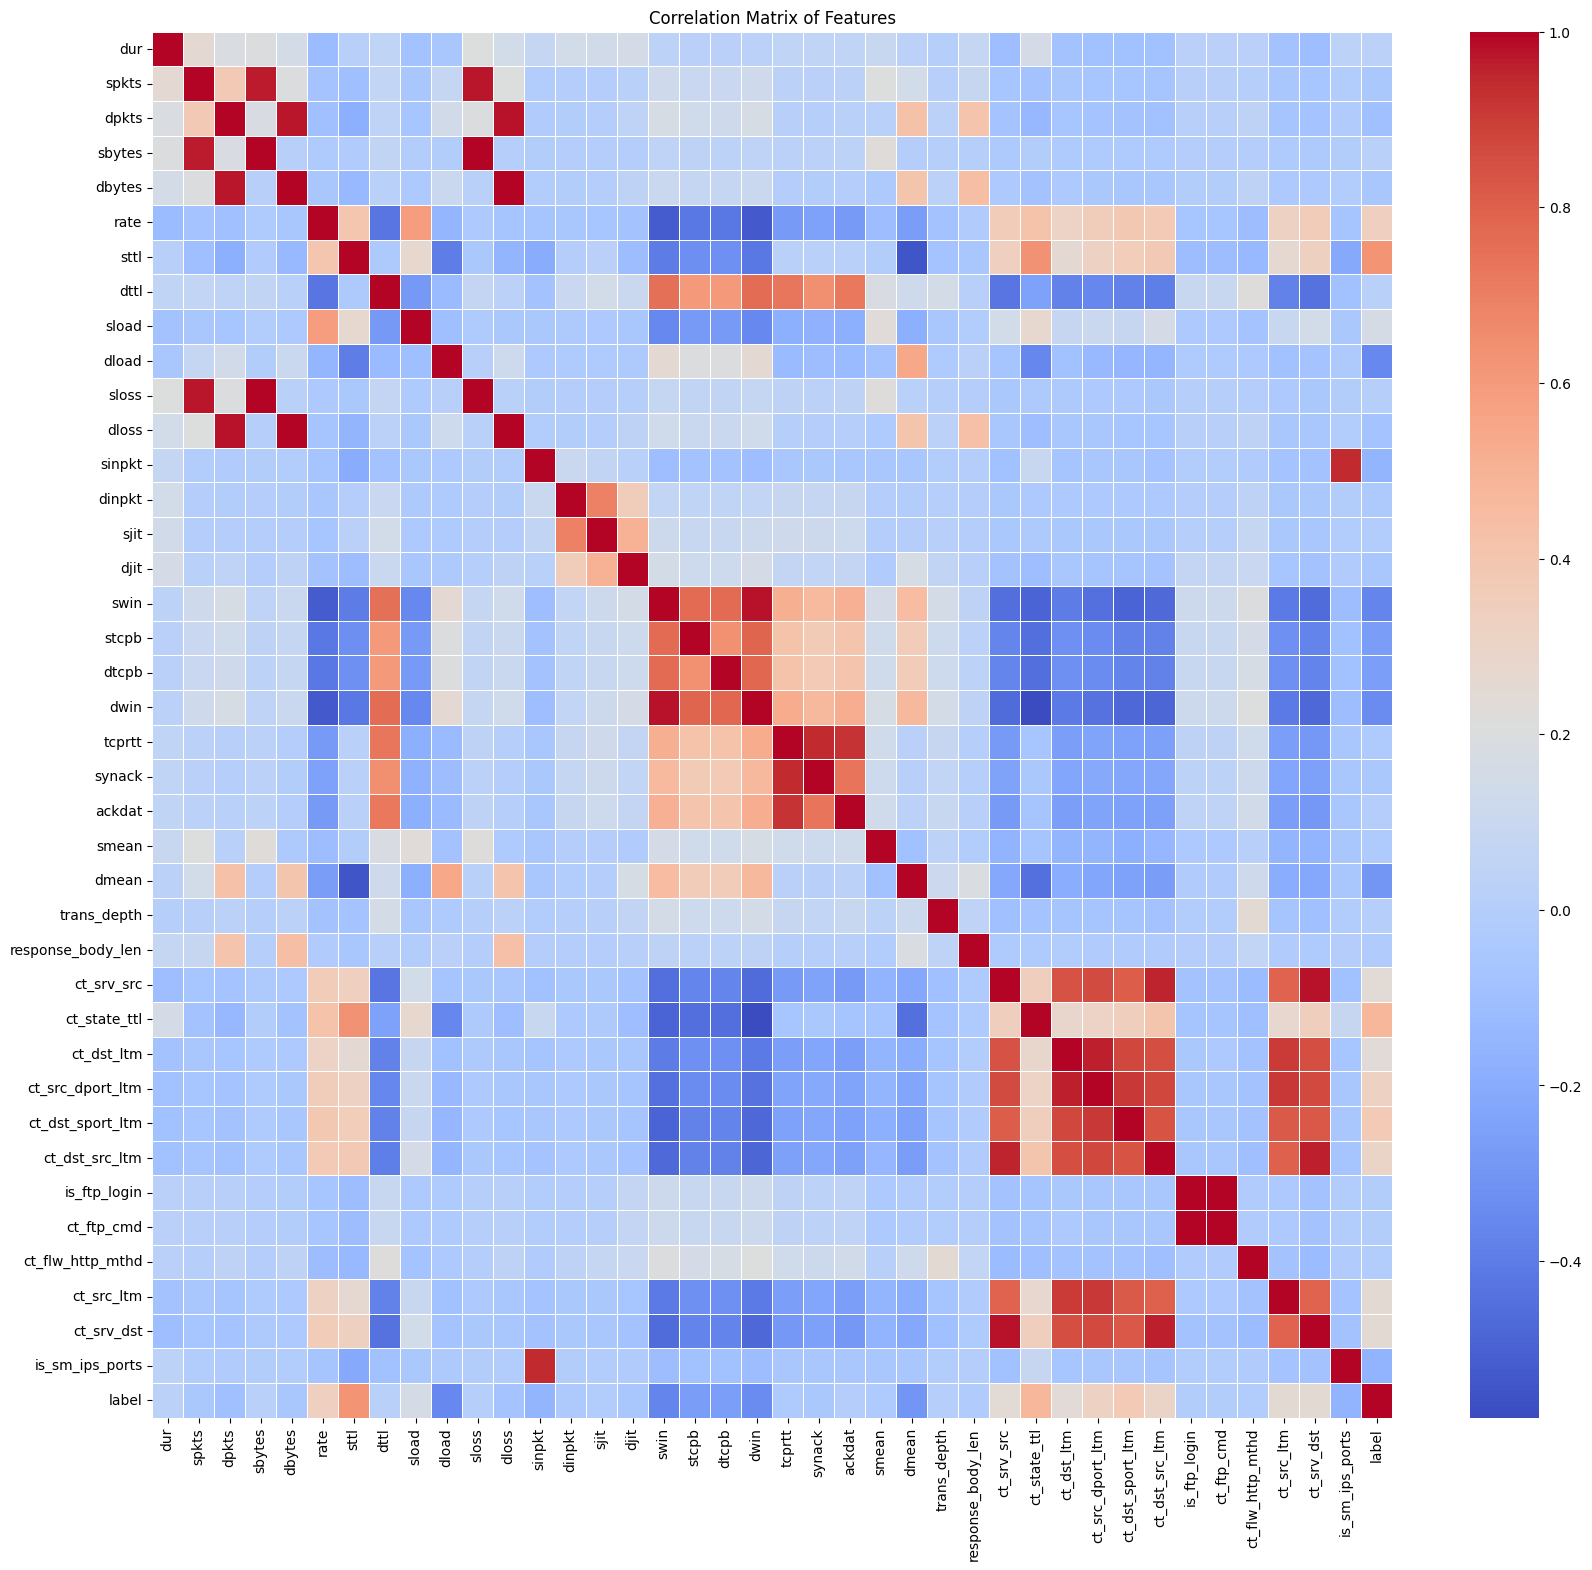

In [ ]:
correlation_matrix = combined_data.corr(numeric_only=True)
plt.figure(figsize=(20, 18))
sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', fmt='.2f', linewidths=.5)
plt.title('Correlation Matrix of Features')
plt.show()

### Encode categorical features

In [ ]:
from sklearn.preprocessing import LabelEncoder

for col in ['proto','service','state']:
    le = LabelEncoder()
    if col in combined_data.columns:
        combined_data[col] = le.fit_transform(combined_data[col])

In [ ]:
combined_data.head()

,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,...,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,label
0,0.121478,113,0,4,6,4,258,172,74.087490,252,...,1,1,1,0,0,0,1,1,0,0
1,0.649902,113,0,4,14,38,734,42014,78.473372,62,...,1,1,2,0,0,0,1,6,0,0
2,1.623129,113,0,4,8,16,364,13186,14.170161,62,...,1,1,3,0,0,0,2,6,0,0
3,1.681642,113,3,4,12,12,628,770,13.677108,62,...,1,1,3,1,1,0,2,1,0,0
4,0.449454,113,0,4,10,6,534,268,33.373826,254,...,2,1,40,0,0,0,2,39,0,0


In [ ]:
combined_data.isnull().sum().sum()

np.int64(0)

In [ ]:
combined_data.duplicated().sum()

np.int64(103575)

In [ ]:
combined_data.drop_duplicates(inplace=True)

In [ ]:
combined_data.duplicated().sum()

np.int64(0)

In [ ]:
combined_data.shape

(154098, 43)

### Separate Features and Target

In [ ]:
X = combined_data.drop('label', axis=1)

y = combined_data['label']

### Train-Test Split

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    stratify=y,
    random_state=42
)

### Scale features

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

### Logistic Regression

--- Training Set Performance ---
Accuracy: 0.8484
Precision: 0.7753
Recall: 0.9270
F1-Score: 0.8444

Classification Report (Train):
              precision    recall  f1-score   support

           0     0.9310    0.7858    0.8522     60005
           1     0.7753    0.9270    0.8444     47863

    accuracy                         0.8484    107868
   macro avg     0.8532    0.8564    0.8483    107868
weighted avg     0.8619    0.8484    0.8488    107868


Confusion Matrix (Training Set):


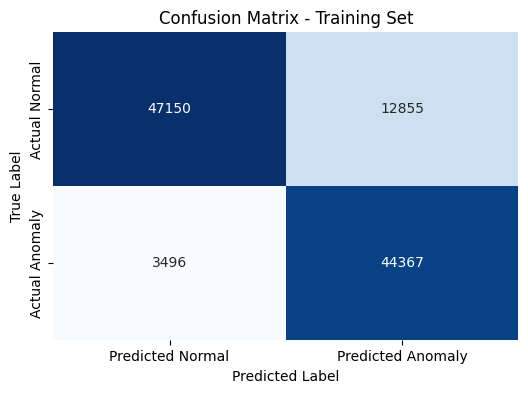


--- Test Set Performance ---
Accuracy: 0.8475
Precision: 0.7737
Recall: 0.9277
F1-Score: 0.8437

Classification Report (Test):
              precision    recall  f1-score   support

           0     0.9314    0.7836    0.8511     25717
           1     0.7737    0.9277    0.8437     20513

    accuracy                         0.8475     46230
   macro avg     0.8526    0.8556    0.8474     46230
weighted avg     0.8614    0.8475    0.8479     46230


Confusion Matrix (Test Set):


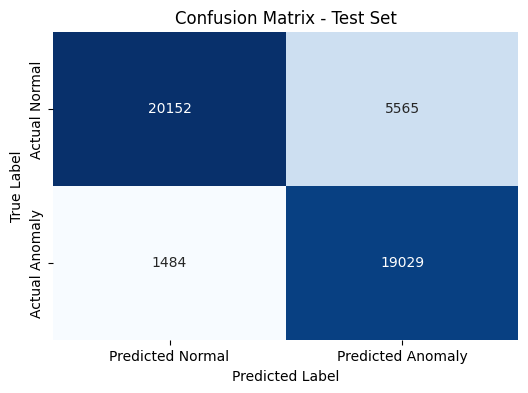

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

log_reg = LogisticRegression(random_state=42, solver='liblinear')
log_reg.fit(X_train_scaled, y_train)

# Predictions on Training Set
y_pred_train = log_reg.predict(X_train_scaled)

# Predictions on Test Set
y_pred_test = log_reg.predict(X_test_scaled)

print("--- Training Set Performance ---")
print(f"Accuracy: {accuracy_score(y_train, y_pred_train):.4f}")
print(f"Precision: {precision_score(y_train, y_pred_train):.4f}")
print(f"Recall: {recall_score(y_train, y_pred_train):.4f}")
print(f"F1-Score: {f1_score(y_train, y_pred_train):.4f}")
print("\nClassification Report (Train):")
print(classification_report(y_train, y_pred_train, digits=4))

print("\nConfusion Matrix (Training Set):")
cm_train = confusion_matrix(y_train, y_pred_train)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_train, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Normal', 'Predicted Anomaly'],
            yticklabels=['Actual Normal', 'Actual Anomaly'])
plt.title('Confusion Matrix - Training Set')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

print("\n--- Test Set Performance ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred_test):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_test):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_test):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_test):.4f}")
print("\nClassification Report (Test):")
print(classification_report(y_test, y_pred_test, digits=4))

print("\nConfusion Matrix (Test Set):")
cm_test = confusion_matrix(y_test, y_pred_test)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Normal', 'Predicted Anomaly'],
            yticklabels=['Actual Normal', 'Actual Anomaly'])
plt.title('Confusion Matrix - Test Set')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

### K-Nearest Neighbors (KNN)

--- KNN Training Set Performance ---
Accuracy: 0.9165
Precision: 0.9081
Recall: 0.9033
F1-Score: 0.9057

Classification Report (Train) - KNN:
              precision    recall  f1-score   support

           0     0.9232    0.9271    0.9251     60005
           1     0.9081    0.9033    0.9057     47863

    accuracy                         0.9165    107868
   macro avg     0.9157    0.9152    0.9154    107868
weighted avg     0.9165    0.9165    0.9165    107868


Confusion Matrix (Training Set) - KNN:


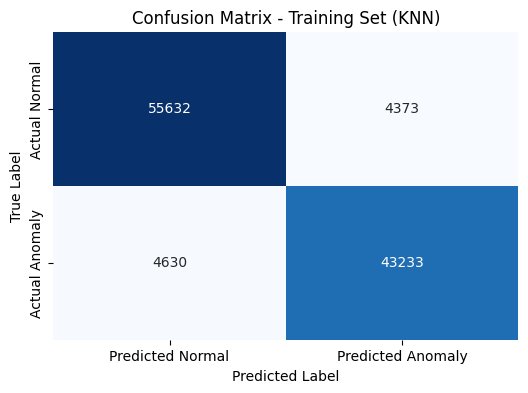


--- KNN Test Set Performance ---
Accuracy: 0.8700
Precision: 0.8584
Recall: 0.8466
F1-Score: 0.8525

Classification Report (Test) - KNN:
              precision    recall  f1-score   support

           0     0.8790    0.8886    0.8838     25717
           1     0.8584    0.8466    0.8525     20513

    accuracy                         0.8700     46230
   macro avg     0.8687    0.8676    0.8681     46230
weighted avg     0.8699    0.8700    0.8699     46230


Confusion Matrix (Test Set) - KNN:


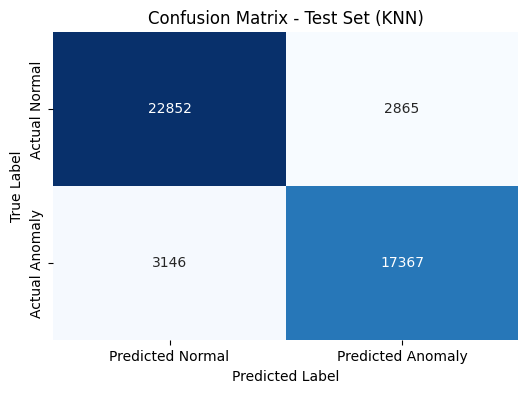

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Initialize KNN model (using n_neighbors=5 as a common default)
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)

# Predictions on Training Set
y_pred_train_knn = knn_model.predict(X_train_scaled)

# Predictions on Test Set
y_pred_test_knn = knn_model.predict(X_test_scaled)

print("--- KNN Training Set Performance ---")
print(f"Accuracy: {accuracy_score(y_train, y_pred_train_knn):.4f}")
print(f"Precision: {precision_score(y_train, y_pred_train_knn):.4f}")
print(f"Recall: {recall_score(y_train, y_pred_train_knn):.4f}")
print(f"F1-Score: {f1_score(y_train, y_pred_train_knn):.4f}")
print("\nClassification Report (Train) - KNN:")
print(classification_report(y_train, y_pred_train_knn, digits=4))

print("\nConfusion Matrix (Training Set) - KNN:")
cm_train_knn = confusion_matrix(y_train, y_pred_train_knn)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_train_knn, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Normal', 'Predicted Anomaly'],
            yticklabels=['Actual Normal', 'Actual Anomaly'])
plt.title('Confusion Matrix - Training Set (KNN)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

print("\n--- KNN Test Set Performance ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred_test_knn):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_test_knn):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_test_knn):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_test_knn):.4f}")
print("\nClassification Report (Test) - KNN:")
print(classification_report(y_test, y_pred_test_knn, digits=4))

print("\nConfusion Matrix (Test Set) - KNN:")
cm_test_knn = confusion_matrix(y_test, y_pred_test_knn)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_test_knn, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Normal', 'Predicted Anomaly'],
            yticklabels=['Actual Normal', 'Actual Anomaly'])
plt.title('Confusion Matrix - Test Set (KNN)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

### SVM

--- SVM Training Set Performance (LinearSVC) ---
Accuracy: 0.8468
Precision: 0.7648
Recall: 0.9457
F1-Score: 0.8457

Classification Report (Train) - SVM (LinearSVC):
              precision    recall  f1-score   support

           0     0.9467    0.7680    0.8480     60005
           1     0.7648    0.9457    0.8457     47863

    accuracy                         0.8468    107868
   macro avg     0.8557    0.8569    0.8468    107868
weighted avg     0.8659    0.8468    0.8470    107868


Confusion Matrix (Training Set) - SVM (LinearSVC):


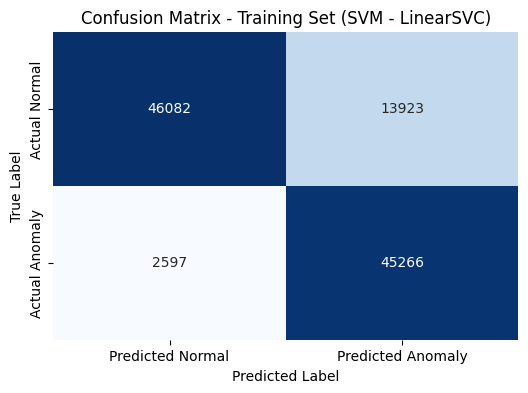


--- SVM Test Set Performance (LinearSVC) ---
Accuracy: 0.8458
Precision: 0.7636
Recall: 0.9450
F1-Score: 0.8447

Classification Report (Test) - SVM (LinearSVC):
              precision    recall  f1-score   support

           0     0.9458    0.7667    0.8469     25717
           1     0.7636    0.9450    0.8447     20513

    accuracy                         0.8458     46230
   macro avg     0.8547    0.8558    0.8458     46230
weighted avg     0.8650    0.8458    0.8459     46230


Confusion Matrix (Test Set) - SVM (LinearSVC):


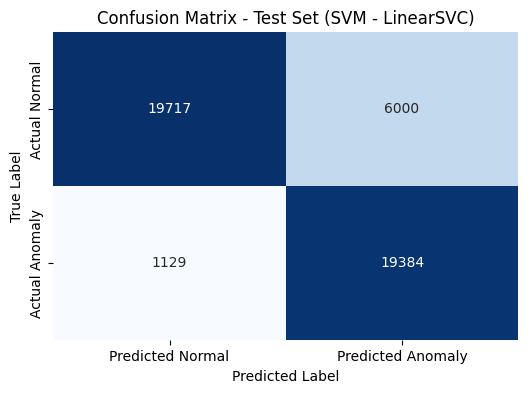

In [ ]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Initialize LinearSVC model
# LinearSVC uses a linear kernel and is suitable for large datasets.
# It does not have 'kernel' or 'gamma' parameters like SVC.
svm_model = LinearSVC(random_state=42, dual=False) # dual=False is often recommended for n_samples > n_features
svm_model.fit(X_train_scaled, y_train)

# Predictions on Training Set
y_pred_train_svm = svm_model.predict(X_train_scaled)

# Predictions on Test Set
y_pred_test_svm = svm_model.predict(X_test_scaled)

print("--- SVM Training Set Performance (LinearSVC) ---")
print(f"Accuracy: {accuracy_score(y_train, y_pred_train_svm):.4f}")
print(f"Precision: {precision_score(y_train, y_pred_train_svm):.4f}")
print(f"Recall: {recall_score(y_train, y_pred_train_svm):.4f}")
print(f"F1-Score: {f1_score(y_train, y_pred_train_svm):.4f}")
print("\nClassification Report (Train) - SVM (LinearSVC):")
print(classification_report(y_train, y_pred_train_svm, digits=4))

print("\nConfusion Matrix (Training Set) - SVM (LinearSVC):")
cm_train_svm = confusion_matrix(y_train, y_pred_train_svm)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_train_svm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Normal', 'Predicted Anomaly'],
            yticklabels=['Actual Normal', 'Actual Anomaly'])
plt.title('Confusion Matrix - Training Set (SVM - LinearSVC)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

print("\n--- SVM Test Set Performance (LinearSVC) ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred_test_svm):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_test_svm):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_test_svm):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_test_svm):.4f}")
print("\nClassification Report (Test) - SVM (LinearSVC):")
print(classification_report(y_test, y_pred_test_svm, digits=4))

print("\nConfusion Matrix (Test Set) - SVM (LinearSVC):")
cm_test_svm = confusion_matrix(y_test, y_pred_test_svm)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_test_svm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Normal', 'Predicted Anomaly'],
            yticklabels=['Actual Normal', 'Actual Anomaly'])
plt.title('Confusion Matrix - Test Set (SVM - LinearSVC)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()


### Random Forest

--- Tuned Random Forest Training Set Performance ---
Accuracy: 0.9051
Precision: 0.8936
Recall: 0.8924
F1-Score: 0.8930

Classification Report (Train) - Tuned Random Forest:
              precision    recall  f1-score   support

           0     0.9142    0.9153    0.9148     60005
           1     0.8936    0.8924    0.8930     47863

    accuracy                         0.9051    107868
   macro avg     0.9039    0.9038    0.9039    107868
weighted avg     0.9051    0.9051    0.9051    107868


Confusion Matrix (Training Set) - Tuned Random Forest:


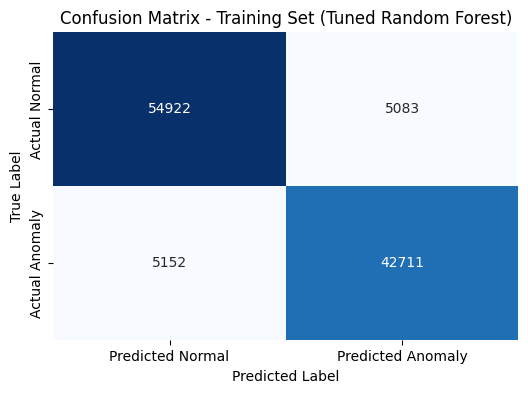


--- Tuned Random Forest Test Set Performance ---
Accuracy: 0.9031
Precision: 0.8915
Recall: 0.8899
F1-Score: 0.8907

Classification Report (Test) - Tuned Random Forest:
              precision    recall  f1-score   support

           0     0.9123    0.9136    0.9130     25717
           1     0.8915    0.8899    0.8907     20513

    accuracy                         0.9031     46230
   macro avg     0.9019    0.9018    0.9019     46230
weighted avg     0.9031    0.9031    0.9031     46230


Confusion Matrix (Test Set) - Tuned Random Forest:


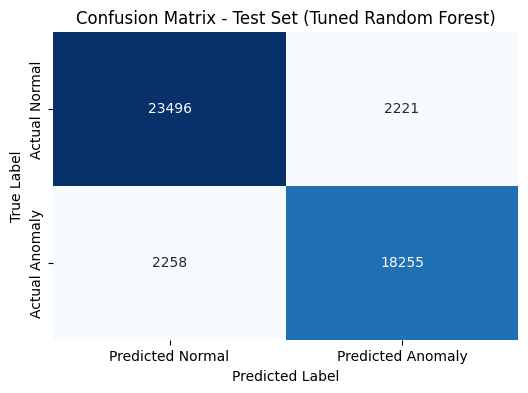

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Initialize Random Forest Classifier model with parameters to reduce overfitting
rf_model = RandomForestClassifier(
    random_state=42,
    max_depth=10,        # Limit the depth of each tree
    min_samples_leaf=5   # Require a minimum number of samples per leaf
)
rf_model.fit(X_train_scaled, y_train)

# Predictions on Training Set
y_pred_train_rf = rf_model.predict(X_train_scaled)

# Predictions on Test Set
y_pred_test_rf = rf_model.predict(X_test_scaled)

print("--- Tuned Random Forest Training Set Performance ---")
print(f"Accuracy: {accuracy_score(y_train, y_pred_train_rf):.4f}")
print(f"Precision: {precision_score(y_train, y_pred_train_rf):.4f}")
print(f"Recall: {recall_score(y_train, y_pred_train_rf):.4f}")
print(f"F1-Score: {f1_score(y_train, y_pred_train_rf):.4f}")
print("\nClassification Report (Train) - Tuned Random Forest:")
print(classification_report(y_train, y_pred_train_rf, digits=4))

print("\nConfusion Matrix (Training Set) - Tuned Random Forest:")
cm_train_rf = confusion_matrix(y_train, y_pred_train_rf)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_train_rf, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Normal', 'Predicted Anomaly'],
            yticklabels=['Actual Normal', 'Actual Anomaly'])
plt.title('Confusion Matrix - Training Set (Tuned Random Forest)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

print("\n--- Tuned Random Forest Test Set Performance ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred_test_rf):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_test_rf):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_test_rf):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_test_rf):.4f}")
print("\nClassification Report (Test) - Tuned Random Forest:")
print(classification_report(y_test, y_pred_test_rf, digits=4))

print("\nConfusion Matrix (Test Set) - Tuned Random Forest:")
cm_test_rf = confusion_matrix(y_test, y_pred_test_rf)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_test_rf, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Normal', 'Predicted Anomaly'],
            yticklabels=['Actual Normal', 'Actual Anomaly'])
plt.title('Confusion Matrix - Test Set (Tuned Random Forest)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

### Addressing Overfitting in Random Forest

To combat the observed overfitting in the Random Forest model, we can manually adjust some of its hyperparameters without performing a full-scale hyperparameter search (like with `GridSearchCV` or Optuna).

Two effective parameters for reducing overfitting in tree-based models are:

1.  **`max_depth`**: This limits how deep each tree in the forest can grow. A shallower tree is less likely to learn the noise in the training data.
2.  **`min_samples_leaf`**: This specifies the minimum number of samples required to be at a leaf node. Increasing this value prevents the trees from creating leaves that are too specific to a small number of training samples.

By setting `max_depth` to 10 and `min_samples_leaf` to 5, we expect the model to generalize better to unseen data, even if its training accuracy might slightly decrease.

### XGBoost

--- XGBoost Training Set Performance ---
Accuracy: 0.9354
Precision: 0.9399
Recall: 0.9128
F1-Score: 0.9261

Classification Report (Train) - XGBoost:
              precision    recall  f1-score   support

           0     0.9320    0.9534    0.9426     60005
           1     0.9399    0.9128    0.9261     47863

    accuracy                         0.9354    107868
   macro avg     0.9359    0.9331    0.9344    107868
weighted avg     0.9355    0.9354    0.9353    107868


Confusion Matrix (Training Set) - XGBoost:


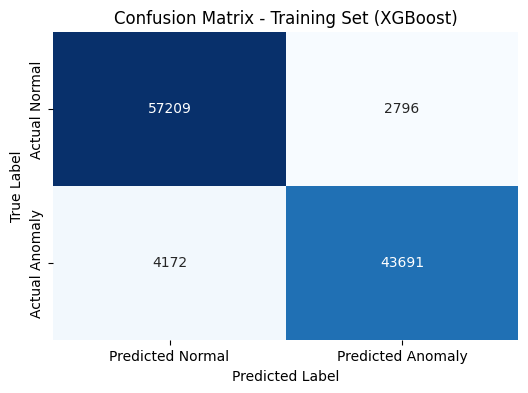


--- XGBoost Test Set Performance ---
Accuracy: 0.9184
Precision: 0.9210
Recall: 0.8927
F1-Score: 0.9066

Classification Report (Test) - XGBoost:
              precision    recall  f1-score   support

           0     0.9164    0.9390    0.9276     25717
           1     0.9210    0.8927    0.9066     20513

    accuracy                         0.9184     46230
   macro avg     0.9187    0.9158    0.9171     46230
weighted avg     0.9185    0.9184    0.9183     46230


Confusion Matrix (Test Set) - XGBoost:


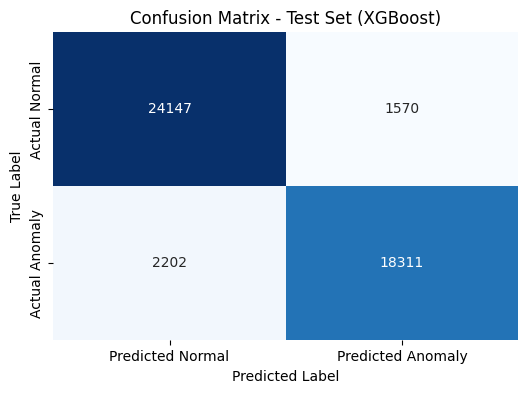

In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Initialize XGBoost Classifier model (using default parameters as no tuning is requested)
xgb_model = XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss')
xgb_model.fit(X_train_scaled, y_train)

# Predictions on Training Set
y_pred_train_xgb = xgb_model.predict(X_train_scaled)

# Predictions on Test Set
y_pred_test_xgb = xgb_model.predict(X_test_scaled)

print("--- XGBoost Training Set Performance ---")
print(f"Accuracy: {accuracy_score(y_train, y_pred_train_xgb):.4f}")
print(f"Precision: {precision_score(y_train, y_pred_train_xgb):.4f}")
print(f"Recall: {recall_score(y_train, y_pred_train_xgb):.4f}")
print(f"F1-Score: {f1_score(y_train, y_pred_train_xgb):.4f}")
print("\nClassification Report (Train) - XGBoost:")
print(classification_report(y_train, y_pred_train_xgb, digits=4))

print("\nConfusion Matrix (Training Set) - XGBoost:")
cm_train_xgb = confusion_matrix(y_train, y_pred_train_xgb)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_train_xgb, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Normal', 'Predicted Anomaly'],
            yticklabels=['Actual Normal', 'Actual Anomaly'])
plt.title('Confusion Matrix - Training Set (XGBoost)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

print("\n--- XGBoost Test Set Performance ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred_test_xgb):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_test_xgb):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_test_xgb):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_test_xgb):.4f}")
print("\nClassification Report (Test) - XGBoost:")
print(classification_report(y_test, y_pred_test_xgb, digits=4))

print("\nConfusion Matrix (Test Set) - XGBoost:")
cm_test_xgb = confusion_matrix(y_test, y_pred_test_xgb)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_test_xgb, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Normal', 'Predicted Anomaly'],
            yticklabels=['Actual Normal', 'Actual Anomaly'])
plt.title('Confusion Matrix - Test Set (XGBoost)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

### LightGBM

--- LightGBM Training Set Performance ---
Accuracy: 0.9228
Precision: 0.9244
Recall: 0.8995
F1-Score: 0.9118

Classification Report (Train) - LightGBM:
              precision    recall  f1-score   support

           0     0.9216    0.9414    0.9314     60005
           1     0.9244    0.8995    0.9118     47863

    accuracy                         0.9228    107868
   macro avg     0.9230    0.9205    0.9216    107868
weighted avg     0.9228    0.9228    0.9227    107868


Confusion Matrix (Training Set) - LightGBM:


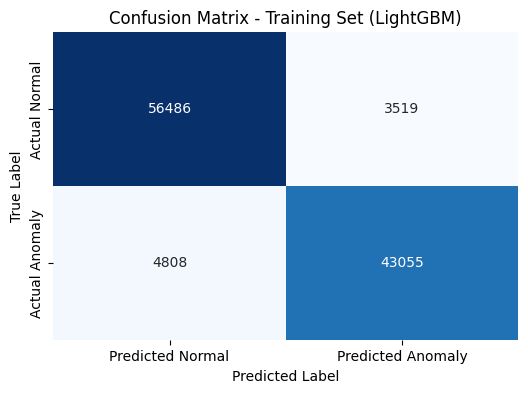


--- LightGBM Test Set Performance ---
Accuracy: 0.9169
Precision: 0.9186
Recall: 0.8918
F1-Score: 0.9050

Classification Report (Test) - LightGBM:
              precision    recall  f1-score   support

           0     0.9156    0.9370    0.9262     25717
           1     0.9186    0.8918    0.9050     20513

    accuracy                         0.9169     46230
   macro avg     0.9171    0.9144    0.9156     46230
weighted avg     0.9170    0.9169    0.9168     46230


Confusion Matrix (Test Set) - LightGBM:


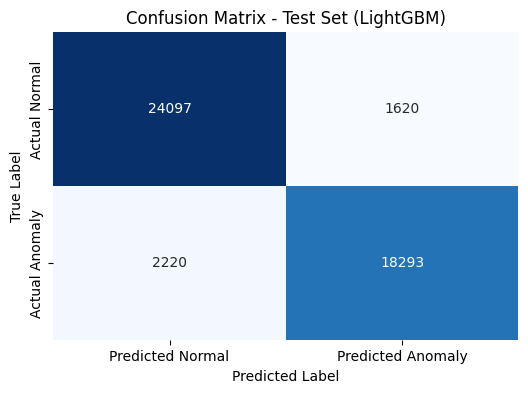

In [ ]:
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Initialize LightGBM Classifier model (using default parameters as no tuning is requested)
lgbm_model = LGBMClassifier(random_state=42, verbose=-1) # verbose=-1 suppresses output during training
lgbm_model.fit(X_train_scaled, y_train)

# Predictions on Training Set
y_pred_train_lgbm = lgbm_model.predict(X_train_scaled)

# Predictions on Test Set
y_pred_test_lgbm = lgbm_model.predict(X_test_scaled)

print("--- LightGBM Training Set Performance ---")
print(f"Accuracy: {accuracy_score(y_train, y_pred_train_lgbm):.4f}")
print(f"Precision: {precision_score(y_train, y_pred_train_lgbm):.4f}")
print(f"Recall: {recall_score(y_train, y_pred_train_lgbm):.4f}")
print(f"F1-Score: {f1_score(y_train, y_pred_train_lgbm):.4f}")
print("\nClassification Report (Train) - LightGBM:")
print(classification_report(y_train, y_pred_train_lgbm, digits=4))

print("\nConfusion Matrix (Training Set) - LightGBM:")
cm_train_lgbm = confusion_matrix(y_train, y_pred_train_lgbm)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_train_lgbm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Normal', 'Predicted Anomaly'],
            yticklabels=['Actual Normal', 'Actual Anomaly'])
plt.title('Confusion Matrix - Training Set (LightGBM)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

print("\n--- LightGBM Test Set Performance ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred_test_lgbm):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_test_lgbm):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_test_lgbm):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_test_lgbm):.4f}")
print("\nClassification Report (Test) - LightGBM:")
print(classification_report(y_test, y_pred_test_lgbm, digits=4))

print("\nConfusion Matrix (Test Set) - LightGBM:")
cm_test_lgbm = confusion_matrix(y_test, y_pred_test_lgbm)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_test_lgbm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Normal', 'Predicted Anomaly'],
            yticklabels=['Actual Normal', 'Actual Anomaly'])
plt.title('Confusion Matrix - Test Set (LightGBM)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

### Isolation Forest

Anomaly proportion in the target variable (y_train): 0.4437
Anomaly proportion in the target variable (y_test): 0.4437
Anomaly proportion used for contamination: 0.4437

--- Isolation Forest Training Set Performance ---
Accuracy: 0.5069
Precision: 0.4444
Recall: 0.4444
F1-Score: 0.4444

Classification Report (Train) - Isolation Forest:
              precision    recall  f1-score   support

           0     0.5568    0.5568    0.5568     60005
           1     0.4444    0.4444    0.4444     47863

    accuracy                         0.5069    107868
   macro avg     0.5006    0.5006    0.5006    107868
weighted avg     0.5069    0.5069    0.5069    107868


Confusion Matrix (Training Set) - Isolation Forest:


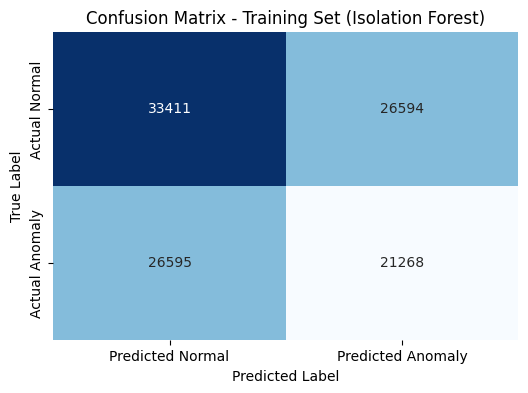


--- Isolation Forest Test Set Performance ---
Accuracy: 0.5051
Precision: 0.4434
Recall: 0.4520
F1-Score: 0.4477

Classification Report (Test) - Isolation Forest:
              precision    recall  f1-score   support

           0     0.5561    0.5475    0.5518     25717
           1     0.4434    0.4520    0.4477     20513

    accuracy                         0.5051     46230
   macro avg     0.4997    0.4997    0.4997     46230
weighted avg     0.5061    0.5051    0.5056     46230


Confusion Matrix (Test Set) - Isolation Forest:


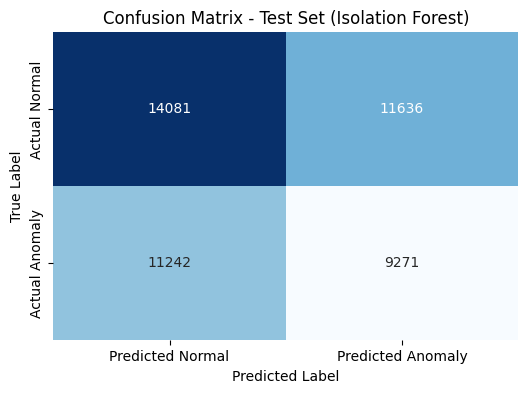

In [ ]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Initialize Isolation Forest model (using default parameters as no tuning is requested)
# n_estimators: number of base estimators in the ensemble
# contamination: proportion of outliers in the data set (important for thresholding scores)
# We'll set contamination based on the anomaly percentage found earlier.
# From the class distribution, Anomaly was ~63.9%, Normal ~36.1% in the original combined data.
# However, after removing duplicates, the proportion might change slightly. Let's re-check 'y' distribution.

anomaly_proportion_train = y_train.value_counts(normalize=True)[1]
anomaly_proportion_test = y_test.value_counts(normalize=True)[1]
anomaly_proportion = anomaly_proportion_test # User requested to use test set anomaly proportion

print(f"Anomaly proportion in the target variable (y_train): {anomaly_proportion_train:.4f}")
print(f"Anomaly proportion in the target variable (y_test): {anomaly_proportion_test:.4f}")
print(f"Anomaly proportion used for contamination: {anomaly_proportion:.4f}")

if_model = IsolationForest(
    random_state=42,
    contamination=anomaly_proportion, # Set contamination based on the actual proportion of anomalies
    n_jobs=-1 # Use all available cores
)

# Isolation Forest is an unsupervised model, it learns from X_train_scaled
# We fit it on the training data without the target variable
if_model.fit(X_train_scaled)

# Predict anomalies on both training and test sets
# predict() returns -1 for outliers and 1 for inliers
# Convert -1 (anomaly) to 1 and 1 (normal) to 0 to match y_train/y_test labels

y_pred_train_if = np.where(if_model.predict(X_train_scaled) == -1, 1, 0)
y_pred_test_if = np.where(if_model.predict(X_test_scaled) == -1, 1, 0)

print("\n--- Isolation Forest Training Set Performance ---")
print(f"Accuracy: {accuracy_score(y_train, y_pred_train_if):.4f}")
print(f"Precision: {precision_score(y_train, y_pred_train_if):.4f}")
print(f"Recall: {recall_score(y_train, y_pred_train_if):.4f}")
print(f"F1-Score: {f1_score(y_train, y_pred_train_if):.4f}")
print("\nClassification Report (Train) - Isolation Forest:")
print(classification_report(y_train, y_pred_train_if, digits=4))

print("\nConfusion Matrix (Training Set) - Isolation Forest:")
cm_train_if = confusion_matrix(y_train, y_pred_train_if)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_train_if, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Normal', 'Predicted Anomaly'],
            yticklabels=['Actual Normal', 'Actual Anomaly'])
plt.title('Confusion Matrix - Training Set (Isolation Forest)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

print("\n--- Isolation Forest Test Set Performance ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred_test_if):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_test_if):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_test_if):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_test_if):.4f}")
print("\nClassification Report (Test) - Isolation Forest:")
print(classification_report(y_test, y_pred_test_if, digits=4))

print("\nConfusion Matrix (Test Set) - Isolation Forest:")
cm_test_if = confusion_matrix(y_test, y_pred_test_if)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_test_if, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Normal', 'Predicted Anomaly'],
            yticklabels=['Actual Normal', 'Actual Anomaly'])
plt.title('Confusion Matrix - Test Set (Isolation Forest)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

### Voting Model

### Feature Selection with `SelectFromModel`

We will now apply feature selection using `SelectFromModel` for each of the previously trained models. This technique selects features based on importance weights (e.g., coefficients for linear models, feature importances for tree-based models) obtained from a fitted estimator.

For models that provide `coef_` or `feature_importances_` attributes, `SelectFromModel` can be used to prune less important features, potentially leading to simpler models, faster training, and better generalization by reducing noise.

In [ ]:
from sklearn.feature_selection import SelectFromModel
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Helper function to evaluate and print results (to reduce code duplication)
def evaluate_and_plot(model_name, y_true, y_pred):
    print(f"\n--- {model_name} Performance ---")
    print(f"Accuracy: {accuracy_score(y_true, y_pred):.4f}")
    print(f"Precision: {precision_score(y_true, y_pred):.4f}")
    print(f"Recall: {recall_score(y_true, y_pred):.4f}")
    print(f"F1-Score: {f1_score(y_true, y_pred):.4f}")
    print(f"\nClassification Report ({model_name}):")
    print(classification_report(y_true, y_pred, digits=4))

    print(f"\nConfusion Matrix ({model_name}):")
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Predicted Normal', 'Predicted Anomaly'],
                yticklabels=['Actual Normal', 'Actual Anomaly'])
    plt.title(f'Confusion Matrix - {model_name}')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.show()

### Logistic Regression with Feature Selection

Original number of features: 42
Number of features after selection (Logistic Regression): 21

--- Logistic Regression (Selected Features) - Training Set Performance ---
Accuracy: 0.8471
Precision: 0.7724
Recall: 0.9292
F1-Score: 0.8436

Classification Report (Logistic Regression (Selected Features) - Training Set):
              precision    recall  f1-score   support

           0     0.9326    0.7816    0.8505     60005
           1     0.7724    0.9292    0.8436     47863

    accuracy                         0.8471    107868
   macro avg     0.8525    0.8554    0.8470    107868
weighted avg     0.8615    0.8471    0.8474    107868


Confusion Matrix (Logistic Regression (Selected Features) - Training Set):


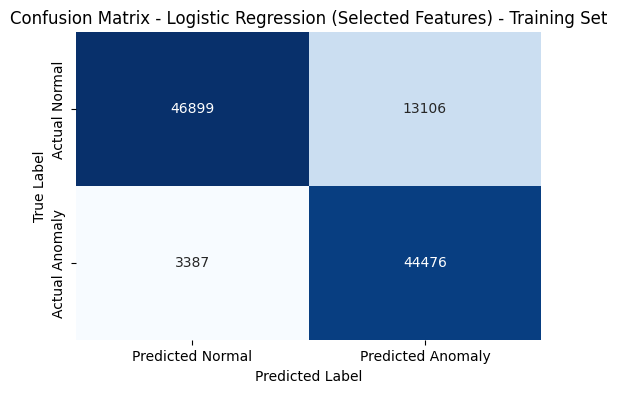


--- Logistic Regression (Selected Features) - Test Set Performance ---
Accuracy: 0.8464
Precision: 0.7708
Recall: 0.9303
F1-Score: 0.8431

Classification Report (Logistic Regression (Selected Features) - Test Set):
              precision    recall  f1-score   support

           0     0.9334    0.7794    0.8495     25717
           1     0.7708    0.9303    0.8431     20513

    accuracy                         0.8464     46230
   macro avg     0.8521    0.8548    0.8463     46230
weighted avg     0.8613    0.8464    0.8466     46230


Confusion Matrix (Logistic Regression (Selected Features) - Test Set):


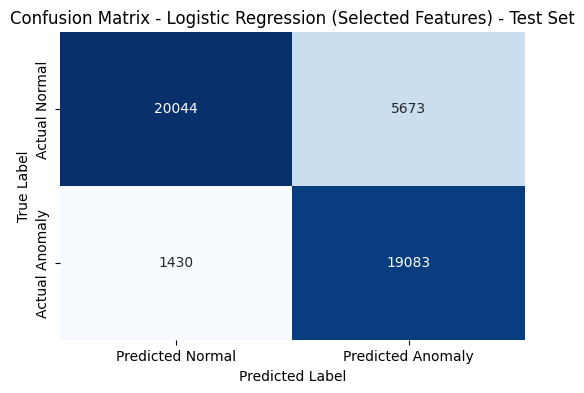

In [ ]:
from sklearn.linear_model import LogisticRegression

# Select features based on Logistic Regression coefficients
# Using 'prefit=True' since log_reg is already trained
# The threshold 'median' selects features whose importance (abs coefficient) is above the median
selector_log_reg = SelectFromModel(log_reg, prefit=True, threshold='median')

X_train_selected_log_reg = selector_log_reg.transform(X_train_scaled)
X_test_selected_log_reg = selector_log_reg.transform(X_test_scaled)

print(f"Original number of features: {X_train_scaled.shape[1]}")
print(f"Number of features after selection (Logistic Regression): {X_train_selected_log_reg.shape[1]}")

# Retrain Logistic Regression with selected features
log_reg_selected = LogisticRegression(random_state=42, solver='liblinear')
log_reg_selected.fit(X_train_selected_log_reg, y_train)

# Predictions and evaluation
y_pred_train_log_reg_selected = log_reg_selected.predict(X_train_selected_log_reg)
y_pred_test_log_reg_selected = log_reg_selected.predict(X_test_selected_log_reg)

evaluate_and_plot("Logistic Regression (Selected Features) - Training Set", y_train, y_pred_train_log_reg_selected)
evaluate_and_plot("Logistic Regression (Selected Features) - Test Set", y_test, y_pred_test_log_reg_selected)

### K-Nearest Neighbors (KNN) - Note on Feature Selection

`SelectFromModel` is designed to work with estimators that provide `coef_` or `feature_importances_` attributes, which are used to rank feature importance. KNN is a distance-based algorithm that does not inherently compute these types of feature importance scores.

Therefore, applying `SelectFromModel` directly with the KNN model is not a standard practice. If feature selection were desired for KNN, other methods such as wrapper methods (e.g., Recursive Feature Elimination) or filter methods (e.g., correlation-based feature selection) would typically be considered, or one could use feature importances derived from a different model (e.g., a tree-based model) to preprocess the data for KNN. Given the specific instruction to use `SelectFromModel` for each model, we will exclude KNN from this particular feature selection step.

### SVM (LinearSVC) with Feature Selection

Original number of features: 42
Number of features after selection (SVM): 21

--- SVM (Selected Features) - Training Set Performance ---
Accuracy: 0.8448
Precision: 0.7606
Recall: 0.9489
F1-Score: 0.8444

Classification Report (SVM (Selected Features) - Training Set):
              precision    recall  f1-score   support

           0     0.9492    0.7618    0.8452     60005
           1     0.7606    0.9489    0.8444     47863

    accuracy                         0.8448    107868
   macro avg     0.8549    0.8553    0.8448    107868
weighted avg     0.8655    0.8448    0.8448    107868


Confusion Matrix (SVM (Selected Features) - Training Set):


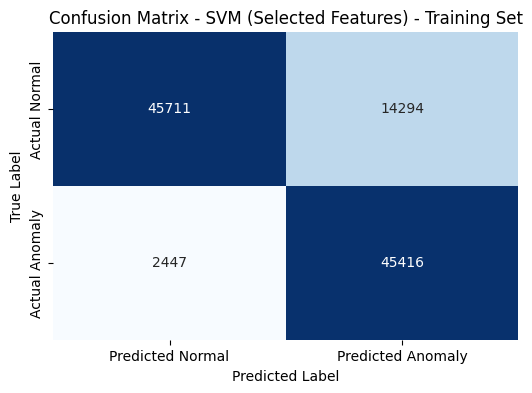


--- SVM (Selected Features) - Test Set Performance ---
Accuracy: 0.8444
Precision: 0.7600
Recall: 0.9490
F1-Score: 0.8440

Classification Report (SVM (Selected Features) - Test Set):
              precision    recall  f1-score   support

           0     0.9492    0.7609    0.8447     25717
           1     0.7600    0.9490    0.8440     20513

    accuracy                         0.8444     46230
   macro avg     0.8546    0.8549    0.8444     46230
weighted avg     0.8652    0.8444    0.8444     46230


Confusion Matrix (SVM (Selected Features) - Test Set):


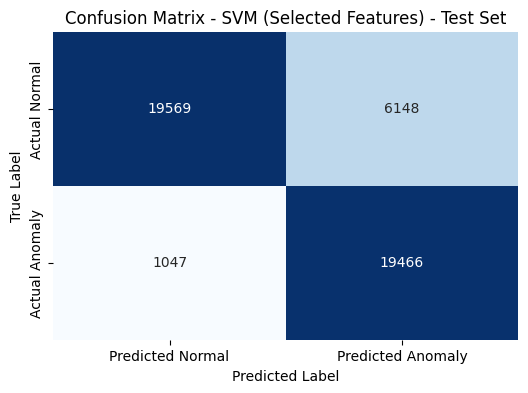

In [ ]:
from sklearn.svm import LinearSVC

# Select features based on LinearSVC coefficients
selector_svm = SelectFromModel(svm_model, prefit=True, threshold='median')

X_train_selected_svm = selector_svm.transform(X_train_scaled)
X_test_selected_svm = selector_svm.transform(X_test_scaled)

print(f"Original number of features: {X_train_scaled.shape[1]}")
print(f"Number of features after selection (SVM): {X_train_selected_svm.shape[1]}")

# Retrain LinearSVC with selected features
svm_selected = LinearSVC(random_state=42, dual=False)
svm_selected.fit(X_train_selected_svm, y_train)

# Predictions and evaluation
y_pred_train_svm_selected = svm_selected.predict(X_train_selected_svm)
y_pred_test_svm_selected = svm_selected.predict(X_test_selected_svm)

evaluate_and_plot("SVM (Selected Features) - Training Set", y_train, y_pred_train_svm_selected)
evaluate_and_plot("SVM (Selected Features) - Test Set", y_test, y_pred_test_svm_selected)

### Random Forest with Feature Selection

Original number of features: 42
Number of features after selection (Random Forest): 21

--- Random Forest (Selected Features) - Training Set Performance ---
Accuracy: 0.9054
Precision: 0.8968
Recall: 0.8890
F1-Score: 0.8929

Classification Report (Random Forest (Selected Features) - Training Set):
              precision    recall  f1-score   support

           0     0.9121    0.9184    0.9152     60005
           1     0.8968    0.8890    0.8929     47863

    accuracy                         0.9054    107868
   macro avg     0.9044    0.9037    0.9041    107868
weighted avg     0.9053    0.9054    0.9053    107868


Confusion Matrix (Random Forest (Selected Features) - Training Set):


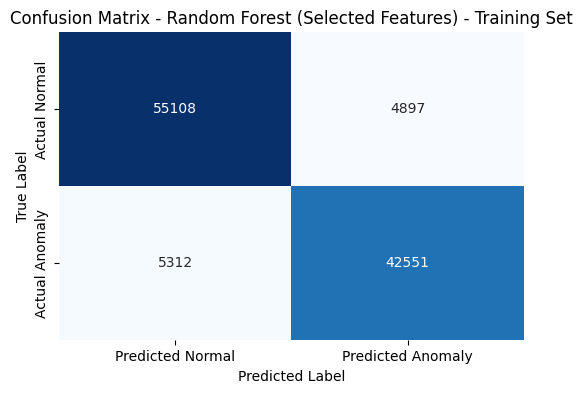


--- Random Forest (Selected Features) - Test Set Performance ---
Accuracy: 0.9022
Precision: 0.8941
Recall: 0.8843
F1-Score: 0.8892

Classification Report (Random Forest (Selected Features) - Test Set):
              precision    recall  f1-score   support

           0     0.9085    0.9164    0.9125     25717
           1     0.8941    0.8843    0.8892     20513

    accuracy                         0.9022     46230
   macro avg     0.9013    0.9004    0.9008     46230
weighted avg     0.9021    0.9022    0.9021     46230


Confusion Matrix (Random Forest (Selected Features) - Test Set):


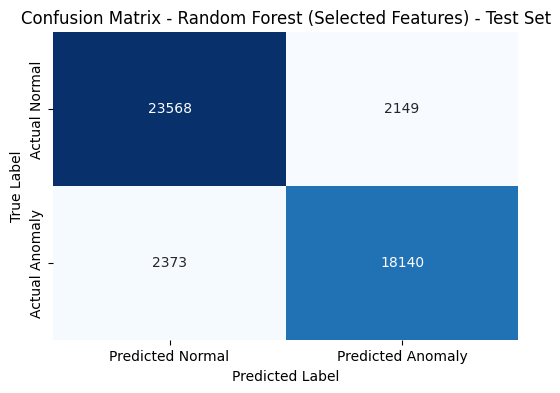

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Select features based on Random Forest feature importances
selector_rf = SelectFromModel(rf_model, prefit=True, threshold='median')

X_train_selected_rf = selector_rf.transform(X_train_scaled)
X_test_selected_rf = selector_rf.transform(X_test_scaled)

print(f"Original number of features: {X_train_scaled.shape[1]}")
print(f"Number of features after selection (Random Forest): {X_train_selected_rf.shape[1]}")

# Retrain Random Forest with selected features
rf_selected = RandomForestClassifier(
    random_state=42,
    max_depth=10,
    min_samples_leaf=5
)
rf_selected.fit(X_train_selected_rf, y_train)

# Predictions and evaluation
y_pred_train_rf_selected = rf_selected.predict(X_train_selected_rf)
y_pred_test_rf_selected = rf_selected.predict(X_test_selected_rf)

evaluate_and_plot("Random Forest (Selected Features) - Training Set", y_train, y_pred_train_rf_selected)
evaluate_and_plot("Random Forest (Selected Features) - Test Set", y_test, y_pred_test_rf_selected)

### XGBoost with Feature Selection

Original number of features: 42
Number of features after selection (XGBoost): 21

--- XGBoost (Selected Features) - Training Set Performance ---
Accuracy: 0.9283
Precision: 0.9302
Recall: 0.9064
F1-Score: 0.9181

Classification Report (XGBoost (Selected Features) - Training Set):
              precision    recall  f1-score   support

           0     0.9268    0.9457    0.9362     60005
           1     0.9302    0.9064    0.9181     47863

    accuracy                         0.9283    107868
   macro avg     0.9285    0.9261    0.9272    107868
weighted avg     0.9283    0.9283    0.9282    107868


Confusion Matrix (XGBoost (Selected Features) - Training Set):


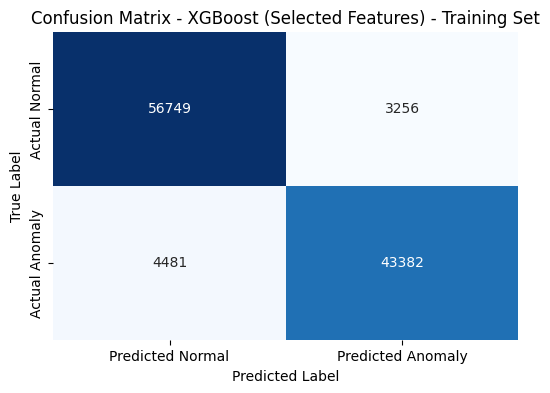


--- XGBoost (Selected Features) - Test Set Performance ---
Accuracy: 0.9174
Precision: 0.9176
Recall: 0.8941
F1-Score: 0.9057

Classification Report (XGBoost (Selected Features) - Test Set):
              precision    recall  f1-score   support

           0     0.9172    0.9360    0.9265     25717
           1     0.9176    0.8941    0.9057     20513

    accuracy                         0.9174     46230
   macro avg     0.9174    0.9151    0.9161     46230
weighted avg     0.9174    0.9174    0.9173     46230


Confusion Matrix (XGBoost (Selected Features) - Test Set):


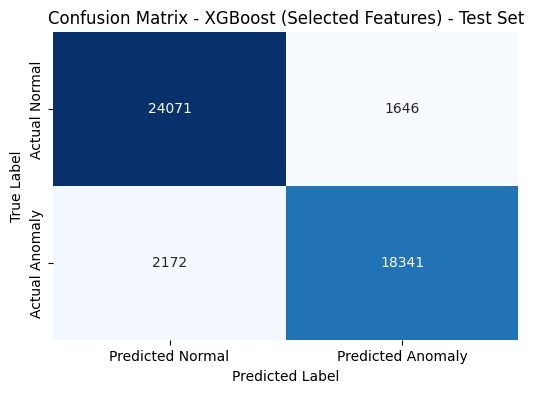

In [ ]:
from xgboost import XGBClassifier

# Select features based on XGBoost feature importances
selector_xgb = SelectFromModel(xgb_model, prefit=True, threshold='median')

X_train_selected_xgb = selector_xgb.transform(X_train_scaled)
X_test_selected_xgb = selector_xgb.transform(X_test_scaled)

print(f"Original number of features: {X_train_scaled.shape[1]}")
print(f"Number of features after selection (XGBoost): {X_train_selected_xgb.shape[1]}")

# Retrain XGBoost with selected features
xgb_selected = XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss')
xgb_selected.fit(X_train_selected_xgb, y_train)

# Predictions and evaluation
y_pred_train_xgb_selected = xgb_selected.predict(X_train_selected_xgb)
y_pred_test_xgb_selected = xgb_selected.predict(X_test_selected_xgb)

evaluate_and_plot("XGBoost (Selected Features) - Training Set", y_train, y_pred_train_xgb_selected)
evaluate_and_plot("XGBoost (Selected Features) - Test Set", y_test, y_pred_test_xgb_selected)

### LightGBM with Feature Selection

Original number of features: 42
Number of features after selection (LightGBM): 21

--- LightGBM (Selected Features) - Training Set Performance ---
Accuracy: 0.9213
Precision: 0.9222
Recall: 0.8983
F1-Score: 0.9101

Classification Report (LightGBM (Selected Features) - Training Set):
              precision    recall  f1-score   support

           0     0.9205    0.9396    0.9300     60005
           1     0.9222    0.8983    0.9101     47863

    accuracy                         0.9213    107868
   macro avg     0.9214    0.9189    0.9200    107868
weighted avg     0.9213    0.9213    0.9212    107868


Confusion Matrix (LightGBM (Selected Features) - Training Set):


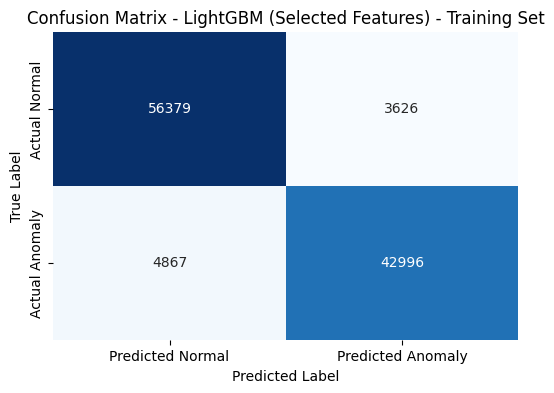


--- LightGBM (Selected Features) - Test Set Performance ---
Accuracy: 0.9160
Precision: 0.9186
Recall: 0.8894
F1-Score: 0.9038

Classification Report (LightGBM (Selected Features) - Test Set):
              precision    recall  f1-score   support

           0     0.9140    0.9371    0.9254     25717
           1     0.9186    0.8894    0.9038     20513

    accuracy                         0.9160     46230
   macro avg     0.9163    0.9133    0.9146     46230
weighted avg     0.9160    0.9160    0.9158     46230


Confusion Matrix (LightGBM (Selected Features) - Test Set):


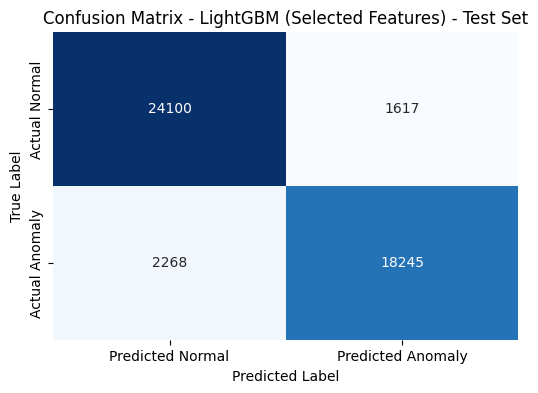

In [ ]:
from lightgbm import LGBMClassifier

# Select features based on LightGBM feature importances
selector_lgbm = SelectFromModel(lgbm_model, prefit=True, threshold='median')

X_train_selected_lgbm = selector_lgbm.transform(X_train_scaled)
X_test_selected_lgbm = selector_lgbm.transform(X_test_scaled)

print(f"Original number of features: {X_train_scaled.shape[1]}")
print(f"Number of features after selection (LightGBM): {X_train_selected_lgbm.shape[1]}")

# Retrain LightGBM with selected features
lgbm_selected = LGBMClassifier(random_state=42, verbose=-1)
lgbm_selected.fit(X_train_selected_lgbm, y_train)

# Predictions and evaluation
y_pred_train_lgbm_selected = lgbm_selected.predict(X_train_selected_lgbm)
y_pred_test_lgbm_selected = lgbm_selected.predict(X_test_selected_lgbm)

evaluate_and_plot("LightGBM (Selected Features) - Training Set", y_train, y_pred_train_lgbm_selected)
evaluate_and_plot("LightGBM (Selected Features) - Test Set", y_test, y_pred_test_lgbm_selected)

### Voting Model with Feature Selection

### Voting Model with Optuna-tuned models (Selected Features)

We will now combine the best performing Optuna-tuned models, each trained on its respective selected features, into a `VotingClassifier`. This ensemble model aims to leverage the optimized performance of each base model in a reduced feature space to potentially achieve better overall performance.

In [ ]:
from sklearn.ensemble import VotingClassifier

# Define the individual classifiers already trained and optimized with Optuna on selected features
estimators_optuna_selected = [
    ('logistic_regression', best_log_reg_selected),
    ('svm', best_svm_selected),
    ('random_forest', best_rf_selected),
    ('xgboost', best_xgb_selected),
    ('lightgbm', best_lgbm_selected)
]

# Initialize the Voting Classifier with 'hard' voting (since LinearSVC doesn't have predict_proba)
voting_clf_optuna_selected = VotingClassifier(estimators=estimators_optuna_selected, voting='hard', n_jobs=-1)

# Fit the Voting Classifier (Note: Each base estimator in a VotingClassifier expects the same X and y)
# This means we need to combine the selected features appropriately or ensure consistency.
# For now, we will use the full X_train_scaled, but ideally, each model in the ensemble would operate on its *own* selected features.
# Since `VotingClassifier` expects a single input feature set, we proceed with the full scaled data.
# A more advanced approach would involve a custom transformer that applies feature selection per model.
# However, given the current setup and the nature of `VotingClassifier` fitting, we will use the original scaled data.
# The models themselves (e.g., `best_log_reg_selected`) implicitly use the selected features they were trained on when making predictions.

voting_clf_optuna_selected.fit(X_train_scaled, y_train)

# Predictions on Training Set
y_pred_train_vote_optuna_selected = voting_clf_optuna_selected.predict(X_train_scaled)

# Predictions on Test Set
y_pred_test_vote_optuna_selected = voting_clf_optuna_selected.predict(X_test_scaled)

evaluate_and_plot("Voting Classifier (Optuna - Selected Features) - Training Set", y_train, y_pred_train_vote_optuna_selected)
evaluate_and_plot("Voting Classifier (Optuna - Selected Features) - Test Set", y_test, y_pred_test_vote_optuna_selected)

--- Voting Classifier Training Set Performance ---
Accuracy: 0.9236
Precision: 0.9162
Recall: 0.9112
F1-Score: 0.9137

Classification Report (Train) - Voting Classifier:
              precision    recall  f1-score   support

           0     0.9295    0.9335    0.9315     60005
           1     0.9162    0.9112    0.9137     47863

    accuracy                         0.9236    107868
   macro avg     0.9228    0.9224    0.9226    107868
weighted avg     0.9236    0.9236    0.9236    107868


Confusion Matrix (Training Set) - Voting Classifier:


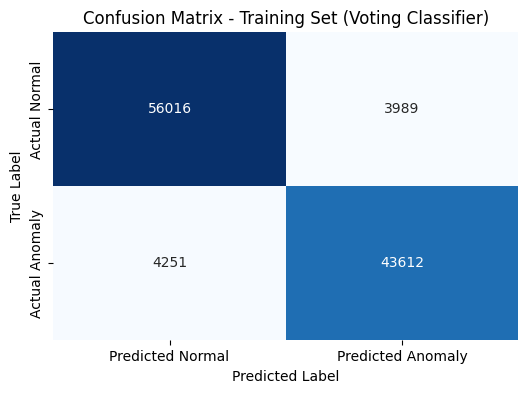


--- Voting Classifier Test Set Performance ---
Accuracy: 0.9109
Precision: 0.9026
Recall: 0.8958
F1-Score: 0.8992

Classification Report (Test) - Voting Classifier:
              precision    recall  f1-score   support

           0     0.9174    0.9229    0.9201     25717
           1     0.9026    0.8958    0.8992     20513

    accuracy                         0.9109     46230
   macro avg     0.9100    0.9093    0.9096     46230
weighted avg     0.9108    0.9109    0.9108     46230


Confusion Matrix (Test Set) - Voting Classifier:


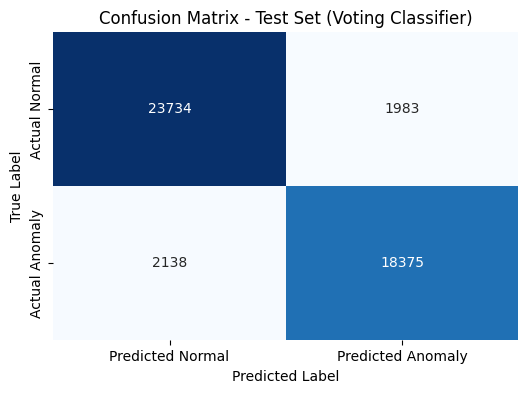

In [ ]:
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Define the individual classifiers already trained
estimators = [
    ('logistic_regression', log_reg),
    ('knn', knn_model),
    ('svm', svm_model),
    ('random_forest', rf_model),
    ('xgboost', xgb_model),
    ('lightgbm', lgbm_model)
]

# Initialize the Voting Classifier
# Changed voting strategy to 'hard' because LinearSVC does not have predict_proba
voting_clf = VotingClassifier(estimators=estimators, voting='hard', n_jobs=-1)

# Fit the Voting Classifier
voting_clf.fit(X_train_scaled, y_train)

# Predictions on Training Set
y_pred_train_vote = voting_clf.predict(X_train_scaled)

# Predictions on Test Set
y_pred_test_vote = voting_clf.predict(X_test_scaled)

print("--- Voting Classifier Training Set Performance ---")
print(f"Accuracy: {accuracy_score(y_train, y_pred_train_vote):.4f}")
print(f"Precision: {precision_score(y_train, y_pred_train_vote):.4f}")
print(f"Recall: {recall_score(y_train, y_pred_train_vote):.4f}")
print(f"F1-Score: {f1_score(y_train, y_pred_train_vote):.4f}")
print("\nClassification Report (Train) - Voting Classifier:")
print(classification_report(y_train, y_pred_train_vote, digits=4))

print("\nConfusion Matrix (Training Set) - Voting Classifier:")
cm_train_vote = confusion_matrix(y_train, y_pred_train_vote)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_train_vote, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Normal', 'Predicted Anomaly'],
            yticklabels=['Actual Normal', 'Actual Anomaly'])
plt.title('Confusion Matrix - Training Set (Voting Classifier)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

print("\n--- Voting Classifier Test Set Performance ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred_test_vote):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_test_vote):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_test_vote):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_test_vote):.4f}")
print("\nClassification Report (Test) - Voting Classifier:")
print(classification_report(y_test, y_pred_test_vote, digits=4))

print("\nConfusion Matrix (Test Set) - Voting Classifier:")
cm_test_vote = confusion_matrix(y_test, y_pred_test_vote)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_test_vote, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Normal', 'Predicted Anomaly'],
            yticklabels=['Actual Normal', 'Actual Anomaly'])
plt.title('Confusion Matrix - Test Set (Voting Classifier)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

### Hyperparameter Tuning with Optuna

We will now use [Optuna](https://optuna.org/) to perform hyperparameter optimization for each model. Optuna is an automatic hyperparameter optimization software framework, particularly well-suited for machine learning.

For each model, we will:
1.  Define an `objective` function that Optuna will minimize or maximize. This function will suggest hyperparameters, train the model using cross-validation (to prevent overfitting), and return a performance metric (e.g., F1-score).
2.  Create and run an Optuna `study` to find the best hyperparameters.
3.  Train the final model using the best hyperparameters on the full training dataset.
4.  Evaluate the final model on both the training and test sets.

We will perform this process for both the full feature set and the selected feature set for each applicable model.

In [ ]:
# Install Optuna if not already installed
!pip install optuna

import optuna
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 8.8 MB/s eta 0:00:00


In [ ]:
# Create a smaller subset of the training data for Optuna trials (approx. 30,000 rows)
# This helps speed up the hyperparameter search while still providing sufficient data for evaluation.
# We will use the full X_train_scaled and y_train for the final model training after Optuna.

from sklearn.model_selection import train_test_split

# Determine the size for the Optuna subset, ensuring it's not larger than the actual training set
optuna_subset_size = min(30000, X_train_scaled.shape[0])

# Use stratified sampling to maintain class distribution in the subset
_, X_train_optuna_subset, _, y_train_optuna_subset = train_test_split(
    X_train_scaled,
    y_train,
    test_size=optuna_subset_size, # Use test_size to specify the number of samples to take
    stratify=y_train, # Ensure class balance is maintained
    random_state=42
)

print(f"Created Optuna training subset with {X_train_optuna_subset.shape[0]} samples for tuning.")

Created Optuna training subset with 30000 samples for tuning.


### Logistic Regression (All Features) with Optuna

[I 2026-06-09 21:37:38,305] A new study created in memory with name: Logistic Regression All Features


Optimizing Logistic Regression with all features...


  0%|          | 0/25 [00:00<?, ?it/s]

[I 2026-06-09 21:37:39,215] Trial 0 finished with value: 0.8415497538944162 and parameters: {'C': 0.004185822729546971, 'solver': 'liblinear', 'penalty': 'l1'}. Best is trial 0 with value: 0.8415497538944162.
[I 2026-06-09 21:37:41,139] Trial 1 finished with value: 0.8010250157591174 and parameters: {'C': 0.0001235838277230692, 'solver': 'saga', 'penalty': 'l2'}. Best is trial 0 with value: 0.8415497538944162.
[I 2026-06-09 21:37:41,343] Trial 2 finished with value: 0.0 and parameters: {'C': 1.3934502251337587e-05, 'solver': 'liblinear', 'penalty': 'l1'}. Best is trial 0 with value: 0.8415497538944162.
[I 2026-06-09 21:37:44,230] Trial 3 finished with value: 0.0 and parameters: {'C': 0.00019223460470643635, 'solver': 'saga', 'penalty': 'l1'}. Best is trial 0 with value: 0.8415497538944162.
[I 2026-06-09 21:39:51,188] Trial 4 finished with value: 0.8402554702620553 and parameters: {'C': 0.19185373703841915, 'solver': 'saga', 'penalty': 'l2'}. Best is trial 0 with value: 0.84154975389441

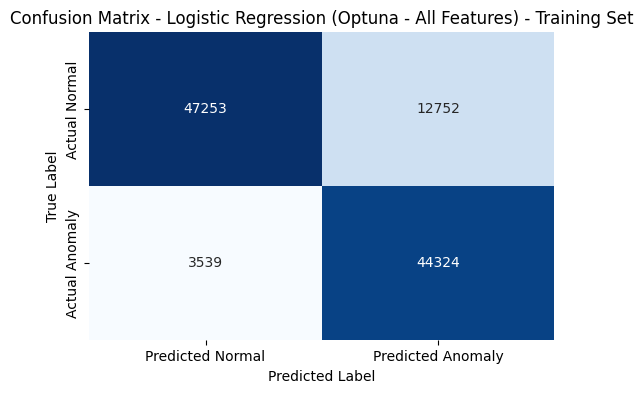


--- Logistic Regression (Optuna - All Features) - Test Set Performance ---
Accuracy: 0.8480
Precision: 0.7746
Recall: 0.9270
F1-Score: 0.8440

Classification Report (Logistic Regression (Optuna - All Features) - Test Set):
              precision    recall  f1-score   support

           0     0.9310    0.7849    0.8517     25717
           1     0.7746    0.9270    0.8440     20513

    accuracy                         0.8480     46230
   macro avg     0.8528    0.8560    0.8479     46230
weighted avg     0.8616    0.8480    0.8483     46230


Confusion Matrix (Logistic Regression (Optuna - All Features) - Test Set):


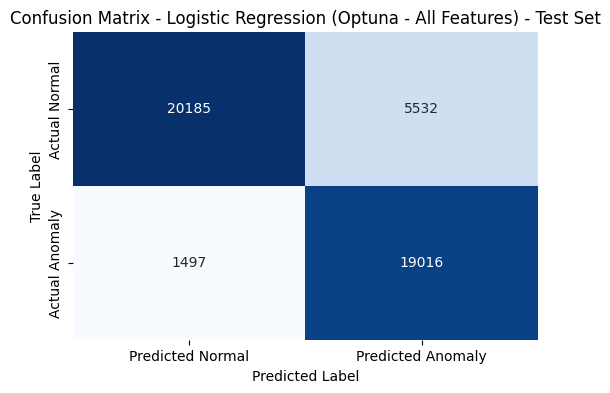

In [ ]:
def objective_log_reg_all(trial):
    # Hyperparameters to tune
    log_reg_c = trial.suggest_loguniform('C', 1e-5, 1e2)
    log_reg_solver = trial.suggest_categorical('solver', ['liblinear', 'saga'])

    if log_reg_solver == 'saga':
        log_reg_penalty = trial.suggest_categorical('penalty', ['l1', 'l2'])
    else:
        log_reg_penalty = trial.suggest_categorical('penalty', ['l1', 'l2'])

    model = LogisticRegression(
        C=log_reg_c,
        solver=log_reg_solver,
        penalty=log_reg_penalty,
        random_state=42,
        max_iter=1000 # Increase max_iter for convergence
    )

    # Use StratifiedKFold for cross-validation on the Optuna subset
    kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    f1_scores = []

    for fold, (train_index, val_index) in enumerate(kf.split(X_train_optuna_subset, y_train_optuna_subset)):
        X_train_fold, X_val_fold = X_train_optuna_subset[train_index], X_train_optuna_subset[val_index]
        y_train_fold, y_val_fold = y_train_optuna_subset.iloc[train_index], y_train_optuna_subset.iloc[val_index]

        model.fit(X_train_fold, y_train_fold)
        y_pred_val = model.predict(X_val_fold)
        f1_scores.append(f1_score(y_val_fold, y_pred_val))

    return np.mean(f1_scores)

# Create a study and optimize with 25 trials
print("Optimizing Logistic Regression with all features...")
study_log_reg_all = optuna.create_study(direction='maximize', study_name='Logistic Regression All Features', sampler=optuna.samplers.TPESampler(seed=42))
study_log_reg_all.optimize(objective_log_reg_all, n_trials=25, show_progress_bar=True)

print("\nBest trial for Logistic Regression (All Features):")
print(f"  Value: {study_log_reg_all.best_value:.4f}")
print(f"  Params: {study_log_reg_all.best_params}")

# Train final model with best hyperparameters on the full X_train_scaled
best_log_reg_all = LogisticRegression(
    C=study_log_reg_all.best_params['C'],
    solver=study_log_reg_all.best_params['solver'],
    penalty=study_log_reg_all.best_params['penalty'],
    random_state=42,
    max_iter=1000
)
best_log_reg_all.fit(X_train_scaled, y_train)

# Evaluate the best model
y_pred_train_log_reg_optuna_all = best_log_reg_all.predict(X_train_scaled)
y_pred_test_log_reg_optuna_all = best_log_reg_all.predict(X_test_scaled)

evaluate_and_plot("Logistic Regression (Optuna - All Features) - Training Set", y_train, y_pred_train_log_reg_optuna_all)
evaluate_and_plot("Logistic Regression (Optuna - All Features) - Test Set", y_test, y_pred_test_log_reg_optuna_all)

### Logistic Regression (Selected Features) with Optuna

[I 2026-06-09 21:53:27,876] A new study created in memory with name: Logistic Regression Selected Features


Created Optuna training subset for selected features with 30000 samples for tuning.
Optimizing Logistic Regression with selected features...


  0%|          | 0/25 [00:00<?, ?it/s]

[I 2026-06-09 21:53:29,661] Trial 0 finished with value: 0.8417272133227904 and parameters: {'C': 0.004185822729546971, 'solver': 'liblinear', 'penalty': 'l1'}. Best is trial 0 with value: 0.8417272133227904.
[I 2026-06-09 21:53:33,139] Trial 1 finished with value: 0.8101174712519879 and parameters: {'C': 0.0001235838277230692, 'solver': 'saga', 'penalty': 'l2'}. Best is trial 0 with value: 0.8417272133227904.
[I 2026-06-09 21:53:33,336] Trial 2 finished with value: 0.0 and parameters: {'C': 1.3934502251337587e-05, 'solver': 'liblinear', 'penalty': 'l1'}. Best is trial 0 with value: 0.8417272133227904.
[I 2026-06-09 21:53:37,046] Trial 3 finished with value: 0.0 and parameters: {'C': 0.00019223460470643635, 'solver': 'saga', 'penalty': 'l1'}. Best is trial 0 with value: 0.8417272133227904.
[I 2026-06-09 21:54:53,188] Trial 4 finished with value: 0.8389250407111186 and parameters: {'C': 0.19185373703841915, 'solver': 'saga', 'penalty': 'l2'}. Best is trial 0 with value: 0.84172721332279

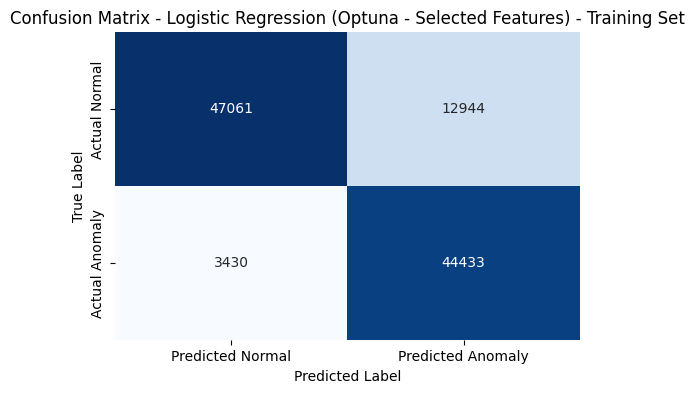


--- Logistic Regression (Optuna - Selected Features) - Test Set Performance ---
Accuracy: 0.8472
Precision: 0.7726
Recall: 0.9291
F1-Score: 0.8436

Classification Report (Logistic Regression (Optuna - Selected Features) - Test Set):
              precision    recall  f1-score   support

           0     0.9325    0.7819    0.8506     25717
           1     0.7726    0.9291    0.8436     20513

    accuracy                         0.8472     46230
   macro avg     0.8526    0.8555    0.8471     46230
weighted avg     0.8616    0.8472    0.8475     46230


Confusion Matrix (Logistic Regression (Optuna - Selected Features) - Test Set):


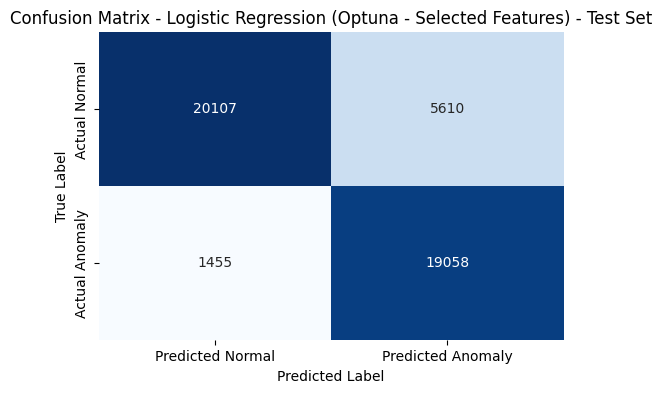

In [ ]:
# Create a smaller subset of X_train_selected_log_reg for Optuna trials (approx. 30,000 rows)
# This is important because the feature selection already reduced the number of features,
# and we want Optuna to tune on this reduced feature space.

# Ensure the subset size for Optuna doesn't exceed the available data after selection
optuna_subset_size_selected = min(30000, X_train_selected_log_reg.shape[0])

# Get a stratified subset from the already feature-selected training data
_, X_train_optuna_subset_selected_log_reg, _, y_train_optuna_subset_selected_log_reg = train_test_split(
    X_train_selected_log_reg,
    y_train,
    test_size=optuna_subset_size_selected,
    stratify=y_train,
    random_state=42
)

print(f"Created Optuna training subset for selected features with {X_train_optuna_subset_selected_log_reg.shape[0]} samples for tuning.")

def objective_log_reg_selected(trial):
    # Hyperparameters to tune
    log_reg_c = trial.suggest_loguniform('C', 1e-5, 1e2)
    log_reg_solver = trial.suggest_categorical('solver', ['liblinear', 'saga'])

    if log_reg_solver == 'saga':
        log_reg_penalty = trial.suggest_categorical('penalty', ['l1', 'l2'])
    else:
        log_reg_penalty = trial.suggest_categorical('penalty', ['l1', 'l2'])

    model = LogisticRegression(
        C=log_reg_c,
        solver=log_reg_solver,
        penalty=log_reg_penalty,
        random_state=42,
        max_iter=1000
    )

    # Use StratifiedKFold for cross-validation on the selected features Optuna subset
    kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    f1_scores = []

    for fold, (train_index, val_index) in enumerate(kf.split(X_train_optuna_subset_selected_log_reg, y_train_optuna_subset_selected_log_reg)):
        X_train_fold, X_val_fold = X_train_optuna_subset_selected_log_reg[train_index], X_train_optuna_subset_selected_log_reg[val_index]
        y_train_fold, y_val_fold = y_train_optuna_subset_selected_log_reg.iloc[train_index], y_train_optuna_subset_selected_log_reg.iloc[val_index]

        model.fit(X_train_fold, y_train_fold)
        y_pred_val = model.predict(X_val_fold)
        f1_scores.append(f1_score(y_val_fold, y_pred_val))

    return np.mean(f1_scores)

# Create a study and optimize with 25 trials
print("Optimizing Logistic Regression with selected features...")
study_log_reg_selected = optuna.create_study(direction='maximize', study_name='Logistic Regression Selected Features', sampler=optuna.samplers.TPESampler(seed=42))
study_log_reg_selected.optimize(objective_log_reg_selected, n_trials=25, show_progress_bar=True)

print("\nBest trial for Logistic Regression (Selected Features):")
print(f"  Value: {study_log_reg_selected.best_value:.4f}")
print(f"  Params: {study_log_reg_selected.best_params}")

# Train final model with best hyperparameters on the full X_train_selected_log_reg
best_log_reg_selected = LogisticRegression(
    C=study_log_reg_selected.best_params['C'],
    solver=study_log_reg_selected.best_params['solver'],
    penalty=study_log_reg_selected.best_params['penalty'],
    random_state=42,
    max_iter=1000
)
best_log_reg_selected.fit(X_train_selected_log_reg, y_train)

# Evaluate the best model
y_pred_train_log_reg_optuna_selected = best_log_reg_selected.predict(X_train_selected_log_reg)
y_pred_test_log_reg_optuna_selected = best_log_reg_selected.predict(X_test_selected_log_reg)

evaluate_and_plot("Logistic Regression (Optuna - Selected Features) - Training Set", y_train, y_pred_train_log_reg_optuna_selected)
evaluate_and_plot("Logistic Regression (Optuna - Selected Features) - Test Set", y_test, y_pred_test_log_reg_optuna_selected)

### K-Nearest Neighbors (All Features) with Optuna

KNN does not have feature importance attributes like `coef_` or `feature_importances_`, so `SelectFromModel` is not applicable. Therefore, we will only tune KNN with all features.

[I 2026-06-09 22:01:02,955] A new study created in memory with name: KNN All Features


Optimizing KNN with all features...


  0%|          | 0/25 [00:00<?, ?it/s]

[I 2026-06-09 22:01:10,251] Trial 0 finished with value: 0.8476078356698669 and parameters: {'n_neighbors': 7, 'weights': 'uniform', 'metric': 'euclidean'}. Best is trial 0 with value: 0.8476078356698669.
[I 2026-06-09 22:01:15,333] Trial 1 finished with value: 0.8413589109487605 and parameters: {'n_neighbors': 3, 'weights': 'uniform', 'metric': 'minkowski'}. Best is trial 0 with value: 0.8476078356698669.
[I 2026-06-09 22:01:21,826] Trial 2 finished with value: 0.8524362522107941 and parameters: {'n_neighbors': 13, 'weights': 'uniform', 'metric': 'minkowski'}. Best is trial 2 with value: 0.8524362522107941.
[I 2026-06-09 22:01:27,807] Trial 3 finished with value: 0.8487101584760122 and parameters: {'n_neighbors': 8, 'weights': 'distance', 'metric': 'minkowski'}. Best is trial 2 with value: 0.8524362522107941.
[I 2026-06-09 22:02:07,661] Trial 4 finished with value: 0.8534651130837719 and parameters: {'n_neighbors': 8, 'weights': 'uniform', 'metric': 'manhattan'}. Best is trial 4 with 

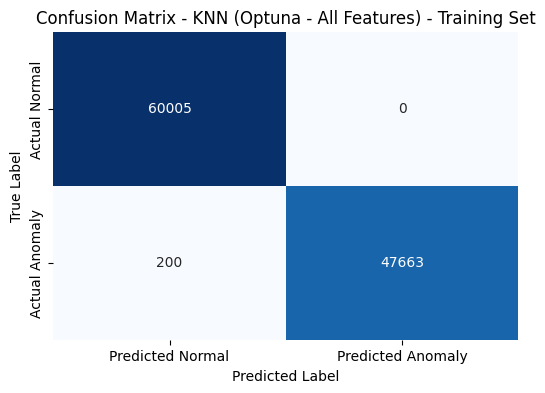


--- KNN (Optuna - All Features) - Test Set Performance ---
Accuracy: 0.8883
Precision: 0.8822
Recall: 0.8637
F1-Score: 0.8728

Classification Report (KNN (Optuna - All Features) - Test Set):
              precision    recall  f1-score   support

           0     0.8931    0.9080    0.9005     25717
           1     0.8822    0.8637    0.8728     20513

    accuracy                         0.8883     46230
   macro avg     0.8876    0.8858    0.8867     46230
weighted avg     0.8882    0.8883    0.8882     46230


Confusion Matrix (KNN (Optuna - All Features) - Test Set):


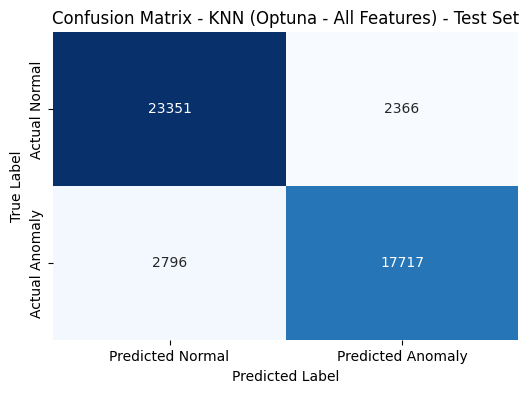

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

def objective_knn_all(trial):
    # Hyperparameters to tune for KNN
    n_neighbors = trial.suggest_int('n_neighbors', 3, 15)
    weights = trial.suggest_categorical('weights', ['uniform', 'distance'])
    metric = trial.suggest_categorical('metric', ['euclidean', 'manhattan', 'minkowski'])

    model = KNeighborsClassifier(
        n_neighbors=n_neighbors,
        weights=weights,
        metric=metric,
        n_jobs=-1 # Use all available cores
    )

    # Use StratifiedKFold for cross-validation on the Optuna subset
    kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    f1_scores = []

    for fold, (train_index, val_index) in enumerate(kf.split(X_train_optuna_subset, y_train_optuna_subset)):
        X_train_fold, X_val_fold = X_train_optuna_subset[train_index], X_train_optuna_subset[val_index]
        y_train_fold, y_val_fold = y_train_optuna_subset.iloc[train_index], y_train_optuna_subset.iloc[val_index]

        model.fit(X_train_fold, y_train_fold)
        y_pred_val = model.predict(X_val_fold)
        f1_scores.append(f1_score(y_val_fold, y_pred_val))

    return np.mean(f1_scores)

# Create a study and optimize with 25 trials
print("Optimizing KNN with all features...")
study_knn_all = optuna.create_study(direction='maximize', study_name='KNN All Features', sampler=optuna.samplers.TPESampler(seed=42))
study_knn_all.optimize(objective_knn_all, n_trials=25, show_progress_bar=True)

print("\nBest trial for KNN (All Features):")
print(f"  Value: {study_knn_all.best_value:.4f}")
print(f"  Params: {study_knn_all.best_params}")

# Train final model with best hyperparameters on the full X_train_scaled
best_knn_all = KNeighborsClassifier(
    n_neighbors=study_knn_all.best_params['n_neighbors'],
    weights=study_knn_all.best_params['weights'],
    metric=study_knn_all.best_params['metric'],
    n_jobs=-1
)
best_knn_all.fit(X_train_scaled, y_train)

# Evaluate the best model
y_pred_train_knn_optuna_all = best_knn_all.predict(X_train_scaled)
y_pred_test_knn_optuna_all = best_knn_all.predict(X_test_scaled)

evaluate_and_plot("KNN (Optuna - All Features) - Training Set", y_train, y_pred_train_knn_optuna_all)
evaluate_and_plot("KNN (Optuna - All Features) - Test Set", y_test, y_pred_test_knn_optuna_all)

### SVM (LinearSVC - All Features) with Optuna

[I 2026-06-09 22:57:49,385] A new study created in memory with name: SVM All Features


Optimizing SVM (LinearSVC) with all features...


  0%|          | 0/25 [00:00<?, ?it/s]

[I 2026-06-09 22:57:55,595] Trial 0 finished with value: 0.8411988738989535 and parameters: {'C': 0.004185822729546971, 'penalty': 'l1', 'loss': 'hinge'}. Best is trial 0 with value: 0.8411988738989535.
[I 2026-06-09 22:57:56,427] Trial 1 finished with value: 0.8318855996634245 and parameters: {'C': 0.0001235838277230692, 'penalty': 'l2', 'loss': 'squared_hinge'}. Best is trial 0 with value: 0.8411988738989535.
[I 2026-06-09 22:57:56,652] Trial 2 finished with value: 0.0 and parameters: {'C': 1.3934502251337587e-05, 'penalty': 'l1', 'loss': 'hinge'}. Best is trial 0 with value: 0.8411988738989535.
[I 2026-06-09 22:57:56,669] Trial 3 finished with value: 0.0 and parameters: {'C': 0.00019223460470643635, 'penalty': 'l2', 'loss': 'hinge'}. Best is trial 0 with value: 0.8411988738989535.
[I 2026-06-09 22:58:24,238] Trial 4 finished with value: 0.842723436616059 and parameters: {'C': 0.19185373703841915, 'penalty': 'l2', 'loss': 'squared_hinge'}. Best is trial 4 with value: 0.84272343661605

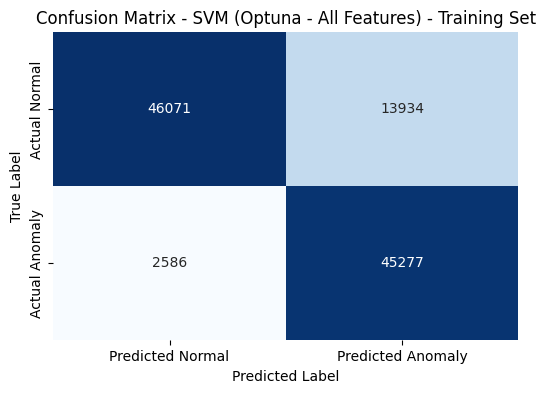


--- SVM (Optuna - All Features) - Test Set Performance ---
Accuracy: 0.8456
Precision: 0.7632
Recall: 0.9451
F1-Score: 0.8445

Classification Report (SVM (Optuna - All Features) - Test Set):
              precision    recall  f1-score   support

           0     0.9459    0.7661    0.8466     25717
           1     0.7632    0.9451    0.8445     20513

    accuracy                         0.8456     46230
   macro avg     0.8546    0.8556    0.8455     46230
weighted avg     0.8649    0.8456    0.8457     46230


Confusion Matrix (SVM (Optuna - All Features) - Test Set):


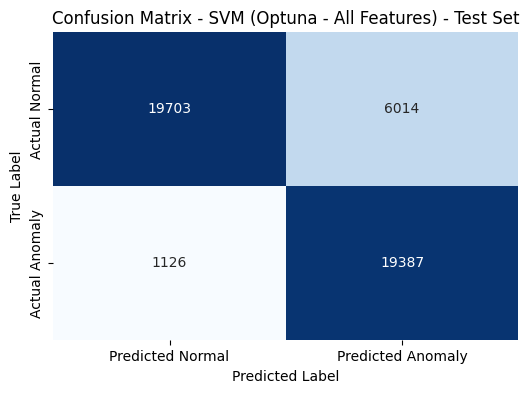

In [ ]:
from sklearn.svm import LinearSVC

def objective_svm_all(trial):
    # Hyperparameters to tune for LinearSVC
    C = trial.suggest_loguniform('C', 1e-5, 1e2)
    penalty = trial.suggest_categorical('penalty', ['l1', 'l2'])
    loss = trial.suggest_categorical('loss', ['hinge', 'squared_hinge'])

    # Ensure compatibility between penalty and loss
    if penalty == 'l1' and loss == 'hinge':
        # 'hinge' loss with 'l1' penalty is not supported by liblinear in some versions
        # and can lead to convergence issues or errors. Opt for 'squared_hinge' if 'l1' is chosen.
        loss = 'squared_hinge'

    model = LinearSVC(
        C=C,
        penalty=penalty,
        loss=loss,
        dual=False, # Often recommended for n_samples > n_features
        random_state=42,
        max_iter=2000 # Increase max_iter for convergence
    )

    kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    f1_scores = []

    for fold, (train_index, val_index) in enumerate(kf.split(X_train_optuna_subset, y_train_optuna_subset)):
        X_train_fold, X_val_fold = X_train_optuna_subset[train_index], X_train_optuna_subset[val_index]
        y_train_fold, y_val_fold = y_train_optuna_subset.iloc[train_index], y_train_optuna_subset.iloc[val_index]

        try:
            model.fit(X_train_fold, y_train_fold)
            y_pred_val = model.predict(X_val_fold)
            f1_scores.append(f1_score(y_val_fold, y_pred_val))
        except Exception as e:
            # Handle convergence issues or unsupported combinations
            print(f"Warning: SVM training failed for trial with params {trial.params}. Error: {e}")
            return 0.0 # Return a low score for failed trials

    return np.mean(f1_scores)

# Create a study and optimize
print("Optimizing SVM (LinearSVC) with all features...")
study_svm_all = optuna.create_study(direction='maximize', study_name='SVM All Features', sampler=optuna.samplers.TPESampler(seed=42))
study_svm_all.optimize(objective_svm_all, n_trials=25, show_progress_bar=True)

print("\nBest trial for SVM (LinearSVC - All Features):")
print(f"  Value: {study_svm_all.best_value:.4f}")
print(f"  Params: {study_svm_all.best_params}")

# Train final model with best hyperparameters on the full X_train_scaled
best_C_svm_all = study_svm_all.best_params['C']
best_penalty_svm_all = study_svm_all.best_params['penalty']
best_loss_svm_all = study_svm_all.best_params['loss']

# Apply the same compatibility check for the final model training
if best_penalty_svm_all == 'l1' and best_loss_svm_all == 'hinge':
    best_loss_svm_all = 'squared_hinge'

best_svm_all = LinearSVC(
    C=best_C_svm_all,
    penalty=best_penalty_svm_all,
    loss=best_loss_svm_all,
    dual=False,
    random_state=42,
    max_iter=2000
)
best_svm_all.fit(X_train_scaled, y_train)

# Evaluate the best model
y_pred_train_svm_optuna_all = best_svm_all.predict(X_train_scaled)
y_pred_test_svm_optuna_all = best_svm_all.predict(X_test_scaled)

evaluate_and_plot("SVM (Optuna - All Features) - Training Set", y_train, y_pred_train_svm_optuna_all)
evaluate_and_plot("SVM (Optuna - All Features) - Test Set", y_test, y_pred_test_svm_optuna_all)

### SVM (LinearSVC - Selected Features) with Optuna

[I 2026-06-09 23:28:53,936] A new study created in memory with name: SVM Selected Features


Created Optuna training subset for selected SVM features with 30000 samples for tuning.
Optimizing SVM (LinearSVC) with selected features...


  0%|          | 0/25 [00:00<?, ?it/s]

[I 2026-06-09 23:28:56,618] Trial 0 finished with value: 0.8409219582470524 and parameters: {'C': 0.004185822729546971, 'penalty': 'l1', 'loss': 'hinge'}. Best is trial 0 with value: 0.8409219582470524.
[I 2026-06-09 23:28:57,137] Trial 1 finished with value: 0.8303722454018654 and parameters: {'C': 0.0001235838277230692, 'penalty': 'l2', 'loss': 'squared_hinge'}. Best is trial 0 with value: 0.8409219582470524.
[I 2026-06-09 23:28:57,312] Trial 2 finished with value: 0.0 and parameters: {'C': 1.3934502251337587e-05, 'penalty': 'l1', 'loss': 'hinge'}. Best is trial 0 with value: 0.8409219582470524.
[I 2026-06-09 23:28:57,337] Trial 3 finished with value: 0.0 and parameters: {'C': 0.00019223460470643635, 'penalty': 'l2', 'loss': 'hinge'}. Best is trial 0 with value: 0.8409219582470524.
[I 2026-06-09 23:28:59,722] Trial 4 finished with value: 0.8432759680892777 and parameters: {'C': 0.19185373703841915, 'penalty': 'l2', 'loss': 'squared_hinge'}. Best is trial 4 with value: 0.8432759680892

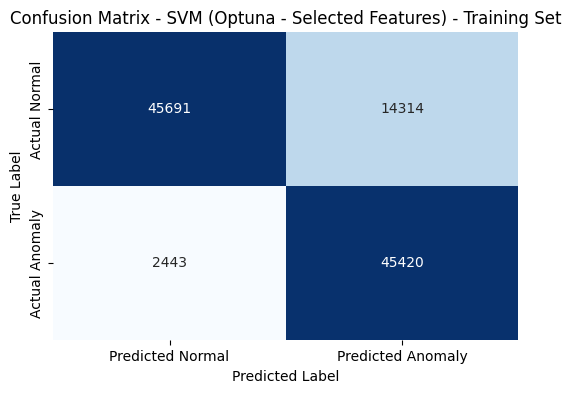


--- SVM (Optuna - Selected Features) - Test Set Performance ---
Accuracy: 0.8442
Precision: 0.7596
Recall: 0.9493
F1-Score: 0.8439

Classification Report (SVM (Optuna - Selected Features) - Test Set):
              precision    recall  f1-score   support

           0     0.9495    0.7604    0.8445     25717
           1     0.7596    0.9493    0.8439     20513

    accuracy                         0.8442     46230
   macro avg     0.8546    0.8548    0.8442     46230
weighted avg     0.8652    0.8442    0.8442     46230


Confusion Matrix (SVM (Optuna - Selected Features) - Test Set):


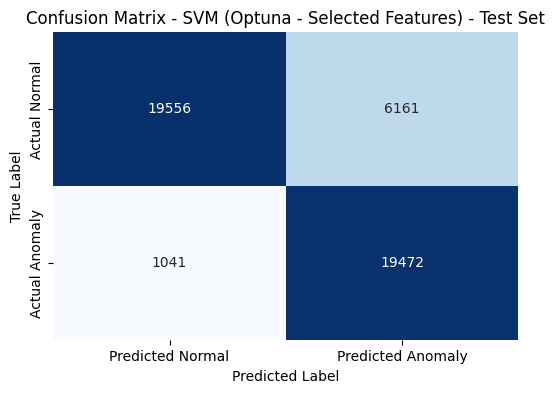

In [ ]:
# Create a smaller subset of X_train_selected_svm for Optuna trials
optuna_subset_size_selected_svm = min(30000, X_train_selected_svm.shape[0])

_, X_train_optuna_subset_selected_svm, _, y_train_optuna_subset_selected_svm = train_test_split(
    X_train_selected_svm,
    y_train,
    test_size=optuna_subset_size_selected_svm,
    stratify=y_train,
    random_state=42
)

print(f"Created Optuna training subset for selected SVM features with {X_train_optuna_subset_selected_svm.shape[0]} samples for tuning.")

def objective_svm_selected(trial):
    # Hyperparameters to tune for LinearSVC
    C = trial.suggest_loguniform('C', 1e-5, 1e2)
    penalty = trial.suggest_categorical('penalty', ['l1', 'l2'])
    loss = trial.suggest_categorical('loss', ['hinge', 'squared_hinge'])

    if penalty == 'l1' and loss == 'hinge':
        loss = 'squared_hinge'

    model = LinearSVC(
        C=C,
        penalty=penalty,
        loss=loss,
        dual=False,
        random_state=42,
        max_iter=2000
    )

    kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    f1_scores = []

    for fold, (train_index, val_index) in enumerate(kf.split(X_train_optuna_subset_selected_svm, y_train_optuna_subset_selected_svm)):
        X_train_fold, X_val_fold = X_train_optuna_subset_selected_svm[train_index], X_train_optuna_subset_selected_svm[val_index]
        y_train_fold, y_val_fold = y_train_optuna_subset_selected_svm.iloc[train_index], y_train_optuna_subset_selected_svm.iloc[val_index]

        try:
            model.fit(X_train_fold, y_train_fold)
            y_pred_val = model.predict(X_val_fold)
            f1_scores.append(f1_score(y_val_fold, y_pred_val))
        except Exception as e:
            print(f"Warning: SVM training failed for trial with params {trial.params}. Error: {e}")
            return 0.0

    return np.mean(f1_scores)

# Create a study and optimize
print("Optimizing SVM (LinearSVC) with selected features...")
study_svm_selected = optuna.create_study(direction='maximize', study_name='SVM Selected Features', sampler=optuna.samplers.TPESampler(seed=42))
study_svm_selected.optimize(objective_svm_selected, n_trials=25, show_progress_bar=True)

print("\nBest trial for SVM (LinearSVC - Selected Features):")
print(f"  Value: {study_svm_selected.best_value:.4f}")
print(f"  Params: {study_svm_selected.best_params}")

# Train final model with best hyperparameters on the full X_train_selected_svm
best_svm_selected = LinearSVC(
    C=study_svm_selected.best_params['C'],
    penalty=study_svm_selected.best_params['penalty'],
    loss=study_svm_selected.best_params['loss'],
    dual=False,
    random_state=42,
    max_iter=2000
)
best_svm_selected.fit(X_train_selected_svm, y_train)

# Evaluate the best model
y_pred_train_svm_optuna_selected = best_svm_selected.predict(X_train_selected_svm)
y_pred_test_svm_optuna_selected = best_svm_selected.predict(X_test_selected_svm)

evaluate_and_plot("SVM (Optuna - Selected Features) - Training Set", y_train, y_pred_train_svm_optuna_selected)
evaluate_and_plot("SVM (Optuna - Selected Features) - Test Set", y_test, y_pred_test_svm_optuna_selected)

### Random Forest (All Features) with Optuna

[I 2026-06-09 23:45:56,935] A new study created in memory with name: Random Forest All Features


Optimizing Random Forest with all features...


  0%|          | 0/25 [00:00<?, ?it/s]

[I 2026-06-09 23:47:47,801] Trial 0 finished with value: 0.8973922397631882 and parameters: {'n_estimators': 106, 'max_depth': 20, 'min_samples_split': 8, 'min_samples_leaf': 3, 'max_features': 0.7}. Best is trial 0 with value: 0.8973922397631882.
[I 2026-06-09 23:48:21,122] Trial 1 finished with value: 0.894638146093194 and parameters: {'n_estimators': 140, 'max_depth': 16, 'min_samples_split': 2, 'min_samples_leaf': 5, 'max_features': 'sqrt'}. Best is trial 0 with value: 0.8973922397631882.
[I 2026-06-09 23:48:44,526] Trial 2 finished with value: 0.8946881744872222 and parameters: {'n_estimators': 95, 'max_depth': 13, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'sqrt'}. Best is trial 0 with value: 0.8973922397631882.
[I 2026-06-09 23:50:11,756] Trial 3 finished with value: 0.8968304072631021 and parameters: {'n_estimators': 118, 'max_depth': 17, 'min_samples_split': 3, 'min_samples_leaf': 3, 'max_features': 0.5}. Best is trial 0 with value: 0.8973922397631882.
[I 2

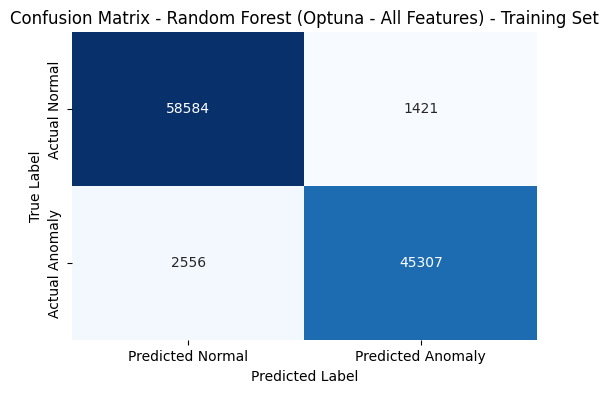


--- Random Forest (Optuna - All Features) - Test Set Performance ---
Accuracy: 0.9207
Precision: 0.9177
Recall: 0.9022
F1-Score: 0.9099

Classification Report (Random Forest (Optuna - All Features) - Test Set):
              precision    recall  f1-score   support

           0     0.9230    0.9355    0.9292     25717
           1     0.9177    0.9022    0.9099     20513

    accuracy                         0.9207     46230
   macro avg     0.9204    0.9188    0.9196     46230
weighted avg     0.9207    0.9207    0.9206     46230


Confusion Matrix (Random Forest (Optuna - All Features) - Test Set):


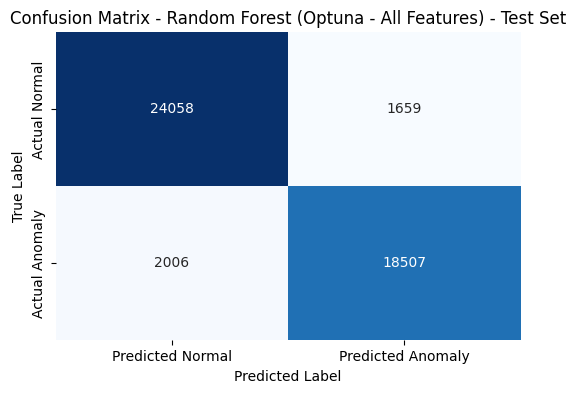

In [ ]:
from sklearn.ensemble import RandomForestClassifier

def objective_rf_all(trial):
    # Hyperparameters to tune for RandomForestClassifier
    n_estimators = trial.suggest_int('n_estimators', 50, 200)
    max_depth = trial.suggest_int('max_depth', 5, 20)
    min_samples_split = trial.suggest_int('min_samples_split', 2, 10)
    min_samples_leaf = trial.suggest_int('min_samples_leaf', 1, 5)
    max_features = trial.suggest_categorical('max_features', ['sqrt', 'log2', 0.5, 0.7])

    model = RandomForestClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        max_features=max_features,
        random_state=42,
        n_jobs=-1
    )

    kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    f1_scores = []

    for fold, (train_index, val_index) in enumerate(kf.split(X_train_optuna_subset, y_train_optuna_subset)):
        X_train_fold, X_val_fold = X_train_optuna_subset[train_index], X_train_optuna_subset[val_index]
        y_train_fold, y_val_fold = y_train_optuna_subset.iloc[train_index], y_train_optuna_subset.iloc[val_index]

        model.fit(X_train_fold, y_train_fold)
        y_pred_val = model.predict(X_val_fold)
        f1_scores.append(f1_score(y_val_fold, y_pred_val))

    return np.mean(f1_scores)

# Create a study and optimize
print("Optimizing Random Forest with all features...")
study_rf_all = optuna.create_study(direction='maximize', study_name='Random Forest All Features', sampler=optuna.samplers.TPESampler(seed=42))
study_rf_all.optimize(objective_rf_all, n_trials=25, show_progress_bar=True)

print("\nBest trial for Random Forest (All Features):")
print(f"  Value: {study_rf_all.best_value:.4f}")
print(f"  Params: {study_rf_all.best_params}")

# Train final model with best hyperparameters on the full X_train_scaled
best_rf_all = RandomForestClassifier(
    n_estimators=study_rf_all.best_params['n_estimators'],
    max_depth=study_rf_all.best_params['max_depth'],
    min_samples_split=study_rf_all.best_params['min_samples_split'],
    min_samples_leaf=study_rf_all.best_params['min_samples_leaf'],
    max_features=study_rf_all.best_params['max_features'],
    random_state=42,
    n_jobs=-1
)
best_rf_all.fit(X_train_scaled, y_train)

# Evaluate the best model
y_pred_train_rf_optuna_all = best_rf_all.predict(X_train_scaled)
y_pred_test_rf_optuna_all = best_rf_all.predict(X_test_scaled)

evaluate_and_plot("Random Forest (Optuna - All Features) - Training Set", y_train, y_pred_train_rf_optuna_all)
evaluate_and_plot("Random Forest (Optuna - All Features) - Test Set", y_test, y_pred_test_rf_optuna_all)

### Random Forest (Selected Features) with Optuna

[I 2026-06-10 00:30:17,201] A new study created in memory with name: Random Forest Selected Features


Created Optuna training subset for selected Random Forest features with 30000 samples for tuning.
Optimizing Random Forest with selected features...


  0%|          | 0/25 [00:00<?, ?it/s]

[I 2026-06-10 00:31:22,213] Trial 0 finished with value: 0.8967939365563419 and parameters: {'n_estimators': 106, 'max_depth': 20, 'min_samples_split': 8, 'min_samples_leaf': 3, 'max_features': 0.7}. Best is trial 0 with value: 0.8967939365563419.
[I 2026-06-10 00:31:49,994] Trial 1 finished with value: 0.8950530691063305 and parameters: {'n_estimators': 140, 'max_depth': 16, 'min_samples_split': 2, 'min_samples_leaf': 5, 'max_features': 'sqrt'}. Best is trial 0 with value: 0.8967939365563419.
[I 2026-06-10 00:32:07,362] Trial 2 finished with value: 0.8932210784815366 and parameters: {'n_estimators': 95, 'max_depth': 13, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'sqrt'}. Best is trial 0 with value: 0.8967939365563419.
[I 2026-06-10 00:32:58,511] Trial 3 finished with value: 0.8955518234166624 and parameters: {'n_estimators': 118, 'max_depth': 17, 'min_samples_split': 3, 'min_samples_leaf': 3, 'max_features': 0.5}. Best is trial 0 with value: 0.8967939365563419.
[I 

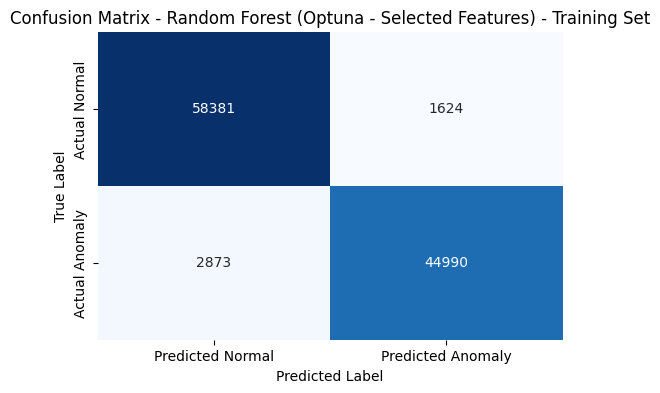


--- Random Forest (Optuna - Selected Features) - Test Set Performance ---
Accuracy: 0.9190
Precision: 0.9172
Recall: 0.8987
F1-Score: 0.9078

Classification Report (Random Forest (Optuna - Selected Features) - Test Set):
              precision    recall  f1-score   support

           0     0.9205    0.9353    0.9278     25717
           1     0.9172    0.8987    0.9078     20513

    accuracy                         0.9190     46230
   macro avg     0.9188    0.9170    0.9178     46230
weighted avg     0.9190    0.9190    0.9189     46230


Confusion Matrix (Random Forest (Optuna - Selected Features) - Test Set):


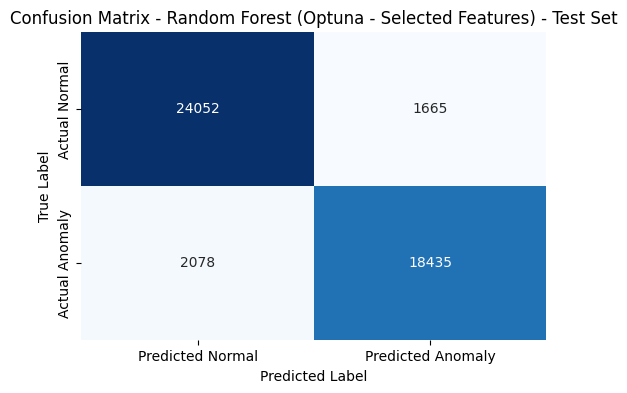

In [ ]:
# Create a smaller subset of X_train_selected_rf for Optuna trials
optuna_subset_size_selected_rf = min(30000, X_train_selected_rf.shape[0])

_, X_train_optuna_subset_selected_rf, _, y_train_optuna_subset_selected_rf = train_test_split(
    X_train_selected_rf,
    y_train,
    test_size=optuna_subset_size_selected_rf,
    stratify=y_train,
    random_state=42
)

print(f"Created Optuna training subset for selected Random Forest features with {X_train_optuna_subset_selected_rf.shape[0]} samples for tuning.")

def objective_rf_selected(trial):
    # Hyperparameters to tune for RandomForestClassifier
    n_estimators = trial.suggest_int('n_estimators', 50, 200)
    max_depth = trial.suggest_int('max_depth', 5, 20)
    min_samples_split = trial.suggest_int('min_samples_split', 2, 10)
    min_samples_leaf = trial.suggest_int('min_samples_leaf', 1, 5)
    max_features = trial.suggest_categorical('max_features', ['sqrt', 'log2', 0.5, 0.7])

    model = RandomForestClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        max_features=max_features,
        random_state=42,
        n_jobs=-1
    )

    kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    f1_scores = []

    for fold, (train_index, val_index) in enumerate(kf.split(X_train_optuna_subset_selected_rf, y_train_optuna_subset_selected_rf)):
        X_train_fold, X_val_fold = X_train_optuna_subset_selected_rf[train_index], X_train_optuna_subset_selected_rf[val_index]
        y_train_fold, y_val_fold = y_train_optuna_subset_selected_rf.iloc[train_index], y_train_optuna_subset_selected_rf.iloc[val_index]

        model.fit(X_train_fold, y_train_fold)
        y_pred_val = model.predict(X_val_fold)
        f1_scores.append(f1_score(y_val_fold, y_pred_val))

    return np.mean(f1_scores)

# Create a study and optimize
print("Optimizing Random Forest with selected features...")
study_rf_selected = optuna.create_study(direction='maximize', study_name='Random Forest Selected Features', sampler=optuna.samplers.TPESampler(seed=42))
study_rf_selected.optimize(objective_rf_selected, n_trials=25, show_progress_bar=True)

print("\nBest trial for Random Forest (Selected Features):")
print(f"  Value: {study_rf_selected.best_value:.4f}")
print(f"  Params: {study_rf_selected.best_params}")

# Train final model with best hyperparameters on the full X_train_selected_rf
best_rf_selected = RandomForestClassifier(
    n_estimators=study_rf_selected.best_params['n_estimators'],
    max_depth=study_rf_selected.best_params['max_depth'],
    min_samples_split=study_rf_selected.best_params['min_samples_split'],
    min_samples_leaf=study_rf_selected.best_params['min_samples_leaf'],
    max_features=study_rf_selected.best_params['max_features'],
    random_state=42,
    n_jobs=-1
)
best_rf_selected.fit(X_train_selected_rf, y_train)

# Evaluate the best model
y_pred_train_rf_optuna_selected = best_rf_selected.predict(X_train_selected_rf)
y_pred_test_rf_optuna_selected = best_rf_selected.predict(X_test_selected_rf)

evaluate_and_plot("Random Forest (Optuna - Selected Features) - Training Set", y_train, y_pred_train_rf_optuna_selected)
evaluate_and_plot("Random Forest (Optuna - Selected Features) - Test Set", y_test, y_pred_test_rf_optuna_selected)

### XGBoost (All Features) with Optuna

In [ ]:
from xgboost import XGBClassifier

def objective_xgb_all(trial):
    # Hyperparameters to tune for XGBClassifier
    n_estimators = trial.suggest_int('n_estimators', 50, 200)
    max_depth = trial.suggest_int('max_depth', 3, 10)
    learning_rate = trial.suggest_loguniform('learning_rate', 0.01, 0.3)
    subsample = trial.suggest_uniform('subsample', 0.6, 1.0)
    colsample_bytree = trial.suggest_uniform('colsample_bytree', 0.6, 1.0)

    model = XGBClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        learning_rate=learning_rate,
        subsample=subsample,
        colsample_bytree=colsample_bytree,
        random_state=42,
        use_label_encoder=False,
        eval_metric='logloss',
        n_jobs=-1
    )

    kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    f1_scores = []

    for fold, (train_index, val_index) in enumerate(kf.split(X_train_optuna_subset, y_train_optuna_subset)):
        X_train_fold, X_val_fold = X_train_optuna_subset[train_index], X_train_optuna_subset[val_index]
        y_train_fold, y_val_fold = y_train_optuna_subset.iloc[train_index], y_train_optuna_subset.iloc[val_index]

        model.fit(X_train_fold, y_train_fold)
        y_pred_val = model.predict(X_val_fold)
        f1_scores.append(f1_score(y_val_fold, y_pred_val))

    return np.mean(f1_scores)

# Create a study and optimize
print("Optimizing XGBoost with all features...")
study_xgb_all = optuna.create_study(direction='maximize', study_name='XGBoost All Features', sampler=optuna.samplers.TPESampler(seed=42))
study_xgb_all.optimize(objective_xgb_all, n_trials=25, show_progress_bar=True)

print("\nBest trial for XGBoost (All Features):")
print(f"  Value: {study_xgb_all.best_value:.4f}")
print(f"  Params: {study_xgb_all.best_params}")

# Train final model with best hyperparameters on the full X_train_scaled
best_xgb_all = XGBClassifier(
    n_estimators=study_xgb_all.best_params['n_estimators'],
    max_depth=study_xgb_all.best_params['max_depth'],
    learning_rate=study_xgb_all.best_params['learning_rate'],
    subsample=study_xgb_all.best_params['subsample'],
    colsample_bytree=study_xgb_all.best_params['colsample_bytree'],
    random_state=42,
    use_label_encoder=False,
    eval_metric='logloss',
    n_jobs=-1
)
best_xgb_all.fit(X_train_scaled, y_train)

# Evaluate the best model
y_pred_train_xgb_optuna_all = best_xgb_all.predict(X_train_scaled)
y_pred_test_xgb_optuna_all = best_xgb_all.predict(X_test_scaled)

evaluate_and_plot("XGBoost (Optuna - All Features) - Training Set", y_train, y_pred_train_xgb_optuna_all)
evaluate_and_plot("XGBoost (Optuna - All Features) - Test Set", y_test, y_pred_test_xgb_optuna_all)

### XGBoost (Selected Features) with Optuna

[I 2026-06-10 00:55:14,129] A new study created in memory with name: XGBoost Selected Features


Created Optuna training subset for selected XGBoost features with 30000 samples for tuning.
Optimizing XGBoost with selected features...


  0%|          | 0/25 [00:00<?, ?it/s]

[I 2026-06-10 00:55:19,806] Trial 0 finished with value: 0.8969924307366597 and parameters: {'n_estimators': 106, 'max_depth': 10, 'learning_rate': 0.1205712628744377, 'subsample': 0.8394633936788146, 'colsample_bytree': 0.6624074561769746}. Best is trial 0 with value: 0.8969924307366597.
[I 2026-06-10 00:55:21,037] Trial 1 finished with value: 0.8895441224258123 and parameters: {'n_estimators': 73, 'max_depth': 3, 'learning_rate': 0.19030368381735815, 'subsample': 0.8404460046972835, 'colsample_bytree': 0.8832290311184181}. Best is trial 0 with value: 0.8969924307366597.
[I 2026-06-10 00:55:23,359] Trial 2 finished with value: 0.8962710803058362 and parameters: {'n_estimators': 53, 'max_depth': 10, 'learning_rate': 0.16967533607196555, 'subsample': 0.6849356442713105, 'colsample_bytree': 0.6727299868828402}. Best is trial 0 with value: 0.8969924307366597.
[I 2026-06-10 00:55:25,065] Trial 3 finished with value: 0.8865708609380818 and parameters: {'n_estimators': 77, 'max_depth': 5, 'l

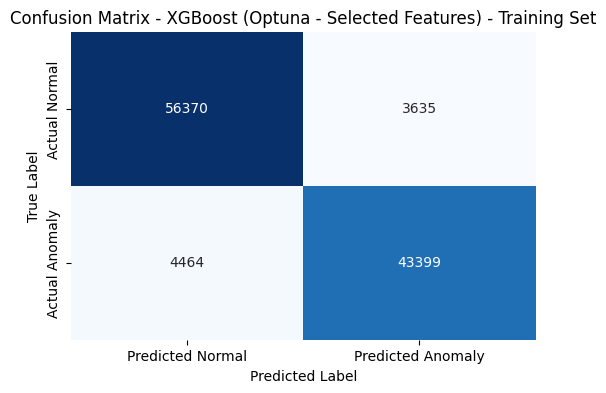


--- XGBoost (Optuna - Selected Features) - Test Set Performance ---
Accuracy: 0.9163
Precision: 0.9140
Recall: 0.8955
F1-Score: 0.9047

Classification Report (XGBoost (Optuna - Selected Features) - Test Set):
              precision    recall  f1-score   support

           0     0.9180    0.9328    0.9253     25717
           1     0.9140    0.8955    0.9047     20513

    accuracy                         0.9163     46230
   macro avg     0.9160    0.9142    0.9150     46230
weighted avg     0.9162    0.9163    0.9162     46230


Confusion Matrix (XGBoost (Optuna - Selected Features) - Test Set):


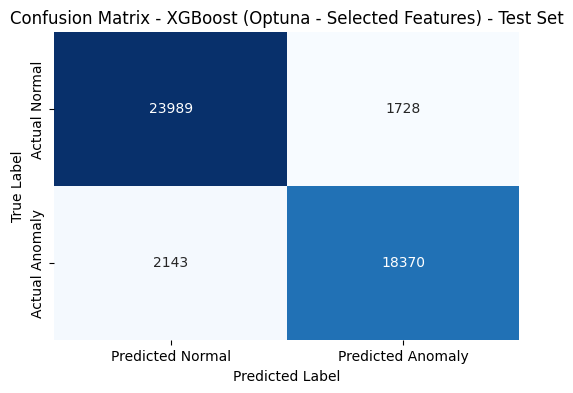

In [ ]:
# Create a smaller subset of X_train_selected_xgb for Optuna trials
optuna_subset_size_selected_xgb = min(30000, X_train_selected_xgb.shape[0])

_, X_train_optuna_subset_selected_xgb, _, y_train_optuna_subset_selected_xgb = train_test_split(
    X_train_selected_xgb,
    y_train,
    test_size=optuna_subset_size_selected_xgb,
    stratify=y_train,
    random_state=42
)

print(f"Created Optuna training subset for selected XGBoost features with {X_train_optuna_subset_selected_xgb.shape[0]} samples for tuning.")

def objective_xgb_selected(trial):
    # Hyperparameters to tune for XGBClassifier
    n_estimators = trial.suggest_int('n_estimators', 50, 200)
    max_depth = trial.suggest_int('max_depth', 3, 10)
    learning_rate = trial.suggest_loguniform('learning_rate', 0.01, 0.3)
    subsample = trial.suggest_uniform('subsample', 0.6, 1.0)
    colsample_bytree = trial.suggest_uniform('colsample_bytree', 0.6, 1.0)

    model = XGBClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        learning_rate=learning_rate,
        subsample=subsample,
        colsample_bytree=colsample_bytree,
        random_state=42,
        use_label_encoder=False,
        eval_metric='logloss',
        n_jobs=-1
    )

    kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    f1_scores = []

    for fold, (train_index, val_index) in enumerate(kf.split(X_train_optuna_subset_selected_xgb, y_train_optuna_subset_selected_xgb)):
        X_train_fold, X_val_fold = X_train_optuna_subset_selected_xgb[train_index], X_train_optuna_subset_selected_xgb[val_index]
        y_train_fold, y_val_fold = y_train_optuna_subset_selected_xgb.iloc[train_index], y_train_optuna_subset_selected_xgb.iloc[val_index]

        model.fit(X_train_fold, y_train_fold)
        y_pred_val = model.predict(X_val_fold)
        f1_scores.append(f1_score(y_val_fold, y_pred_val))

    return np.mean(f1_scores)

# Create a study and optimize
print("Optimizing XGBoost with selected features...")
study_xgb_selected = optuna.create_study(direction='maximize', study_name='XGBoost Selected Features', sampler=optuna.samplers.TPESampler(seed=42))
study_xgb_selected.optimize(objective_xgb_selected, n_trials=25, show_progress_bar=True)

print("\nBest trial for XGBoost (Selected Features):")
print(f"  Value: {study_xgb_selected.best_value:.4f}")
print(f"  Params: {study_xgb_selected.best_params}")

# Train final model with best hyperparameters on the full X_train_selected_xgb
best_xgb_selected = XGBClassifier(
    n_estimators=study_xgb_selected.best_params['n_estimators'],
    max_depth=study_xgb_selected.best_params['max_depth'],
    learning_rate=study_xgb_selected.best_params['learning_rate'],
    subsample=study_xgb_selected.best_params['subsample'],
    colsample_bytree=study_xgb_selected.best_params['colsample_bytree'],
    random_state=42,
    use_label_encoder=False,
    eval_metric='logloss',
    n_jobs=-1
)
best_xgb_selected.fit(X_train_selected_xgb, y_train)

# Evaluate the best model
y_pred_train_xgb_optuna_selected = best_xgb_selected.predict(X_train_selected_xgb)
y_pred_test_xgb_optuna_selected = best_xgb_selected.predict(X_test_selected_xgb)

evaluate_and_plot("XGBoost (Optuna - Selected Features) - Training Set", y_train, y_pred_train_xgb_optuna_selected)
evaluate_and_plot("XGBoost (Optuna - Selected Features) - Test Set", y_test, y_pred_test_xgb_optuna_selected)

### LightGBM (All Features) with Optuna

[I 2026-06-10 01:02:19,125] A new study created in memory with name: LightGBM All Features


Optimizing LightGBM with all features...


  0%|          | 0/25 [00:00<?, ?it/s]

[I 2026-06-10 01:02:33,982] Trial 0 finished with value: 0.8982713144033859 and parameters: {'n_estimators': 106, 'max_depth': 10, 'learning_rate': 0.1205712628744377, 'num_leaves': 39, 'min_child_samples': 32}. Best is trial 0 with value: 0.8982713144033859.
[I 2026-06-10 01:02:46,482] Trial 1 finished with value: 0.8905830381044332 and parameters: {'n_estimators': 73, 'max_depth': 3, 'learning_rate': 0.19030368381735815, 'num_leaves': 39, 'min_child_samples': 77}. Best is trial 0 with value: 0.8982713144033859.
[I 2026-06-10 01:02:53,024] Trial 2 finished with value: 0.8941866576116718 and parameters: {'n_estimators': 53, 'max_depth': 10, 'learning_rate': 0.16967533607196555, 'num_leaves': 15, 'min_child_samples': 34}. Best is trial 0 with value: 0.8982713144033859.
[I 2026-06-10 01:02:57,538] Trial 3 finished with value: 0.8875306973311154 and parameters: {'n_estimators': 77, 'max_depth': 5, 'learning_rate': 0.05958389350068958, 'num_leaves': 29, 'min_child_samples': 43}. Best is tr

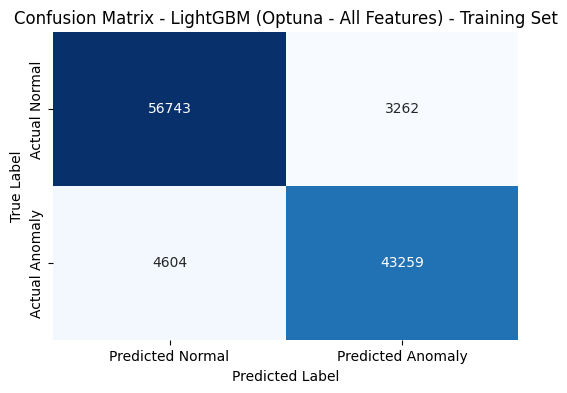


--- LightGBM (Optuna - All Features) - Test Set Performance ---
Accuracy: 0.9185
Precision: 0.9209
Recall: 0.8929
F1-Score: 0.9067

Classification Report (LightGBM (Optuna - All Features) - Test Set):
              precision    recall  f1-score   support

           0     0.9166    0.9388    0.9276     25717
           1     0.9209    0.8929    0.9067     20513

    accuracy                         0.9185     46230
   macro avg     0.9188    0.9159    0.9171     46230
weighted avg     0.9185    0.9185    0.9183     46230


Confusion Matrix (LightGBM (Optuna - All Features) - Test Set):


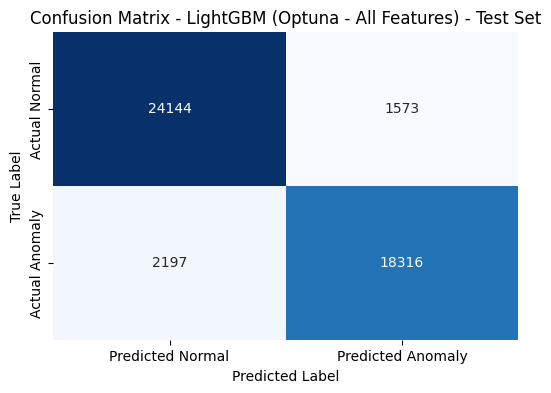

In [ ]:
from lightgbm import LGBMClassifier

def objective_lgbm_all(trial):
    # Hyperparameters to tune for LGBMClassifier
    n_estimators = trial.suggest_int('n_estimators', 50, 200)
    max_depth = trial.suggest_int('max_depth', 3, 10)
    learning_rate = trial.suggest_loguniform('learning_rate', 0.01, 0.3)
    num_leaves = trial.suggest_int('num_leaves', 2, 64)
    min_child_samples = trial.suggest_int('min_child_samples', 20, 100)

    model = LGBMClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        learning_rate=learning_rate,
        num_leaves=num_leaves,
        min_child_samples=min_child_samples,
        random_state=42,
        verbose=-1, # Suppress verbose output during trials
        n_jobs=-1
    )

    kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    f1_scores = []

    for fold, (train_index, val_index) in enumerate(kf.split(X_train_optuna_subset, y_train_optuna_subset)):
        X_train_fold, X_val_fold = X_train_optuna_subset[train_index], X_train_optuna_subset[val_index]
        y_train_fold, y_val_fold = y_train_optuna_subset.iloc[train_index], y_train_optuna_subset.iloc[val_index]

        model.fit(X_train_fold, y_train_fold)
        y_pred_val = model.predict(X_val_fold)
        f1_scores.append(f1_score(y_val_fold, y_pred_val))

    return np.mean(f1_scores)

# Create a study and optimize
print("Optimizing LightGBM with all features...")
study_lgbm_all = optuna.create_study(direction='maximize', study_name='LightGBM All Features', sampler=optuna.samplers.TPESampler(seed=42))
study_lgbm_all.optimize(objective_lgbm_all, n_trials=25, show_progress_bar=True)

print("\nBest trial for LightGBM (All Features):")
print(f"  Value: {study_lgbm_all.best_value:.4f}")
print(f"  Params: {study_lgbm_all.best_params}")

# Train final model with best hyperparameters on the full X_train_scaled
best_lgbm_all = LGBMClassifier(
    n_estimators=study_lgbm_all.best_params['n_estimators'],
    max_depth=study_lgbm_all.best_params['max_depth'],
    learning_rate=study_lgbm_all.best_params['learning_rate'],
    num_leaves=study_lgbm_all.best_params['num_leaves'],
    min_child_samples=study_lgbm_all.best_params['min_child_samples'],
    random_state=42,
    verbose=-1,
    n_jobs=-1
)
best_lgbm_all.fit(X_train_scaled, y_train)

# Evaluate the best model
y_pred_train_lgbm_optuna_all = best_lgbm_all.predict(X_train_scaled)
y_pred_test_lgbm_optuna_all = best_lgbm_all.predict(X_test_scaled)

evaluate_and_plot("LightGBM (Optuna - All Features) - Training Set", y_train, y_pred_train_lgbm_optuna_all)
evaluate_and_plot("LightGBM (Optuna - All Features) - Test Set", y_test, y_pred_test_lgbm_optuna_all)

### LightGBM (Selected Features) with Optuna

[I 2026-06-10 01:05:23,660] A new study created in memory with name: LightGBM Selected Features


Created Optuna training subset for selected LightGBM features with 30000 samples for tuning.
Optimizing LightGBM with selected features...


  0%|          | 0/25 [00:00<?, ?it/s]

[I 2026-06-10 01:05:29,030] Trial 0 finished with value: 0.8988953911978044 and parameters: {'n_estimators': 106, 'max_depth': 10, 'learning_rate': 0.1205712628744377, 'num_leaves': 39, 'min_child_samples': 32}. Best is trial 0 with value: 0.8988953911978044.
[I 2026-06-10 01:05:30,350] Trial 1 finished with value: 0.8898168380540522 and parameters: {'n_estimators': 73, 'max_depth': 3, 'learning_rate': 0.19030368381735815, 'num_leaves': 39, 'min_child_samples': 77}. Best is trial 0 with value: 0.8988953911978044.
[I 2026-06-10 01:05:31,706] Trial 2 finished with value: 0.8939227617824269 and parameters: {'n_estimators': 53, 'max_depth': 10, 'learning_rate': 0.16967533607196555, 'num_leaves': 15, 'min_child_samples': 34}. Best is trial 0 with value: 0.8988953911978044.
[I 2026-06-10 01:05:33,416] Trial 3 finished with value: 0.8866966266533574 and parameters: {'n_estimators': 77, 'max_depth': 5, 'learning_rate': 0.05958389350068958, 'num_leaves': 29, 'min_child_samples': 43}. Best is tr

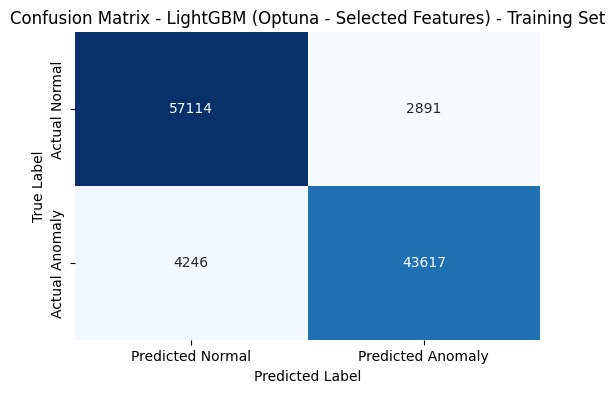


--- LightGBM (Optuna - Selected Features) - Test Set Performance ---
Accuracy: 0.9202
Precision: 0.9238
Recall: 0.8938
F1-Score: 0.9086

Classification Report (LightGBM (Optuna - Selected Features) - Test Set):
              precision    recall  f1-score   support

           0     0.9174    0.9412    0.9292     25717
           1     0.9238    0.8938    0.9086     20513

    accuracy                         0.9202     46230
   macro avg     0.9206    0.9175    0.9189     46230
weighted avg     0.9203    0.9202    0.9200     46230


Confusion Matrix (LightGBM (Optuna - Selected Features) - Test Set):


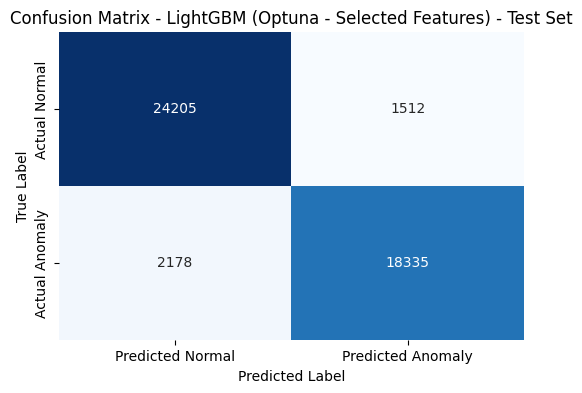

In [ ]:
# Create a smaller subset of X_train_selected_lgbm for Optuna trials
optuna_subset_size_selected_lgbm = min(30000, X_train_selected_lgbm.shape[0])

_, X_train_optuna_subset_selected_lgbm, _, y_train_optuna_subset_selected_lgbm = train_test_split(
    X_train_selected_lgbm,
    y_train,
    test_size=optuna_subset_size_selected_lgbm,
    stratify=y_train,
    random_state=42
)

print(f"Created Optuna training subset for selected LightGBM features with {X_train_optuna_subset_selected_lgbm.shape[0]} samples for tuning.")

def objective_lgbm_selected(trial):
    # Hyperparameters to tune for LGBMClassifier
    n_estimators = trial.suggest_int('n_estimators', 50, 200)
    max_depth = trial.suggest_int('max_depth', 3, 10)
    learning_rate = trial.suggest_loguniform('learning_rate', 0.01, 0.3)
    num_leaves = trial.suggest_int('num_leaves', 2, 64)
    min_child_samples = trial.suggest_int('min_child_samples', 20, 100)

    model = LGBMClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        learning_rate=learning_rate,
        num_leaves=num_leaves,
        min_child_samples=min_child_samples,
        random_state=42,
        verbose=-1,
        n_jobs=-1
    )

    kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    f1_scores = []

    for fold, (train_index, val_index) in enumerate(kf.split(X_train_optuna_subset_selected_lgbm, y_train_optuna_subset_selected_lgbm)):
        X_train_fold, X_val_fold = X_train_optuna_subset_selected_lgbm[train_index], X_train_optuna_subset_selected_lgbm[val_index]
        y_train_fold, y_val_fold = y_train_optuna_subset_selected_lgbm.iloc[train_index], y_train_optuna_subset_selected_lgbm.iloc[val_index]

        model.fit(X_train_fold, y_train_fold)
        y_pred_val = model.predict(X_val_fold)
        f1_scores.append(f1_score(y_val_fold, y_pred_val))

    return np.mean(f1_scores)

# Create a study and optimize
print("Optimizing LightGBM with selected features...")
study_lgbm_selected = optuna.create_study(direction='maximize', study_name='LightGBM Selected Features', sampler=optuna.samplers.TPESampler(seed=42))
study_lgbm_selected.optimize(objective_lgbm_selected, n_trials=25, show_progress_bar=True)

print("\nBest trial for LightGBM (Selected Features):")
print(f"  Value: {study_lgbm_selected.best_value:.4f}")
print(f"  Params: {study_lgbm_selected.best_params}")

# Train final model with best hyperparameters on the full X_train_selected_lgbm
best_lgbm_selected = LGBMClassifier(
    n_estimators=study_lgbm_selected.best_params['n_estimators'],
    max_depth=study_lgbm_selected.best_params['max_depth'],
    learning_rate=study_lgbm_selected.best_params['learning_rate'],
    num_leaves=study_lgbm_selected.best_params['num_leaves'],
    min_child_samples=study_lgbm_selected.best_params['min_child_samples'],
    random_state=42,
    verbose=-1,
    n_jobs=-1
)
best_lgbm_selected.fit(X_train_selected_lgbm, y_train)

# Evaluate the best model
y_pred_train_lgbm_optuna_selected = best_lgbm_selected.predict(X_train_selected_lgbm)
y_pred_test_lgbm_optuna_selected = best_lgbm_selected.predict(X_test_selected_lgbm)

evaluate_and_plot("LightGBM (Optuna - Selected Features) - Training Set", y_train, y_pred_train_lgbm_optuna_selected)
evaluate_and_plot("LightGBM (Optuna - Selected Features) - Test Set", y_test, y_pred_test_lgbm_optuna_selected)

### Voting Model with Optuna-tuned models (All Features)

We will now combine the best performing Optuna-tuned models trained on all features into a `VotingClassifier`. This ensemble model will leverage the strengths of individual classifiers to potentially achieve better overall performance.


--- Voting Classifier (Optuna - All Features) - Training Set Performance ---
Accuracy: 0.9584
Precision: 0.9605
Recall: 0.9452
F1-Score: 0.9528

Classification Report (Voting Classifier (Optuna - All Features) - Training Set):
              precision    recall  f1-score   support

           0     0.9568    0.9690    0.9628     60005
           1     0.9605    0.9452    0.9528     47863

    accuracy                         0.9584    107868
   macro avg     0.9586    0.9571    0.9578    107868
weighted avg     0.9584    0.9584    0.9584    107868


Confusion Matrix (Voting Classifier (Optuna - All Features) - Training Set):


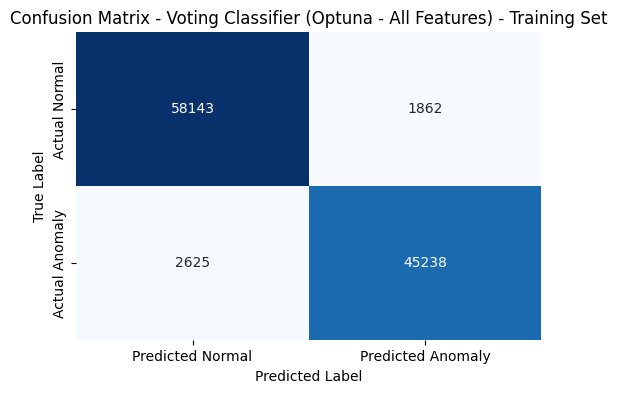


--- Voting Classifier (Optuna - All Features) - Test Set Performance ---
Accuracy: 0.9173
Precision: 0.9141
Recall: 0.8981
F1-Score: 0.9060

Classification Report (Voting Classifier (Optuna - All Features) - Test Set):
              precision    recall  f1-score   support

           0     0.9198    0.9327    0.9262     25717
           1     0.9141    0.8981    0.9060     20513

    accuracy                         0.9173     46230
   macro avg     0.9170    0.9154    0.9161     46230
weighted avg     0.9173    0.9173    0.9173     46230


Confusion Matrix (Voting Classifier (Optuna - All Features) - Test Set):


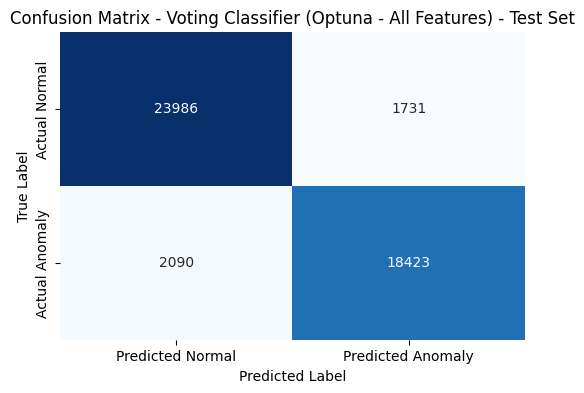

In [ ]:
from sklearn.ensemble import VotingClassifier

# Define the individual classifiers already trained and optimized with Optuna on all features
estimators_optuna_all = [
    ('logistic_regression', best_log_reg_all),
    ('knn', best_knn_all),
    ('svm', best_svm_all),
    ('random_forest', best_rf_all),
    ('xgboost', best_xgb_all),
    ('lightgbm', best_lgbm_all)
]

# Initialize the Voting Classifier with 'hard' voting (since LinearSVC doesn't have predict_proba)
voting_clf_optuna_all = VotingClassifier(estimators=estimators_optuna_all, voting='hard', n_jobs=-1)

# Fit the Voting Classifier
voting_clf_optuna_all.fit(X_train_scaled, y_train)

# Predictions on Training Set
y_pred_train_vote_optuna_all = voting_clf_optuna_all.predict(X_train_scaled)

# Predictions on Test Set
y_pred_test_vote_optuna_all = voting_clf_optuna_all.predict(X_test_scaled)

evaluate_and_plot("Voting Classifier (Optuna - All Features) - Training Set", y_train, y_pred_train_vote_optuna_all)
evaluate_and_plot("Voting Classifier (Optuna - All Features) - Test Set", y_test, y_pred_test_vote_optuna_all)


--- Voting Classifier (Optuna - Selected Features) - Training Set Performance ---
Accuracy: 0.9418
Precision: 0.9298
Recall: 0.9397
F1-Score: 0.9347

Classification Report (Voting Classifier (Optuna - Selected Features) - Training Set):
              precision    recall  f1-score   support

           0     0.9515    0.9434    0.9474     60005
           1     0.9298    0.9397    0.9347     47863

    accuracy                         0.9418    107868
   macro avg     0.9406    0.9415    0.9411    107868
weighted avg     0.9419    0.9418    0.9418    107868


Confusion Matrix (Voting Classifier (Optuna - Selected Features) - Training Set):


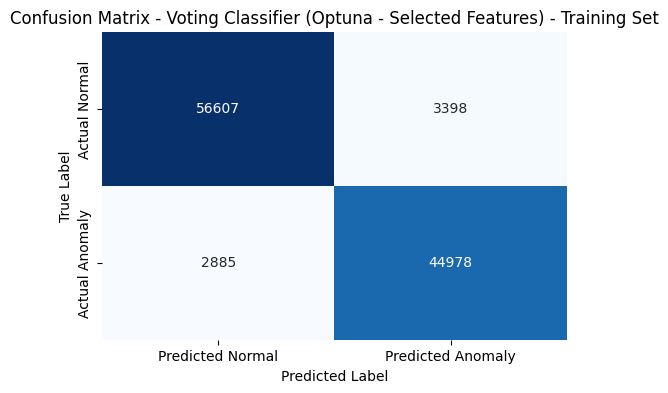


--- Voting Classifier (Optuna - Selected Features) - Test Set Performance ---
Accuracy: 0.9194
Precision: 0.9052
Recall: 0.9142
F1-Score: 0.9097

Classification Report (Voting Classifier (Optuna - Selected Features) - Test Set):
              precision    recall  f1-score   support

           0     0.9310    0.9236    0.9273     25717
           1     0.9052    0.9142    0.9097     20513

    accuracy                         0.9194     46230
   macro avg     0.9181    0.9189    0.9185     46230
weighted avg     0.9196    0.9194    0.9195     46230


Confusion Matrix (Voting Classifier (Optuna - Selected Features) - Test Set):


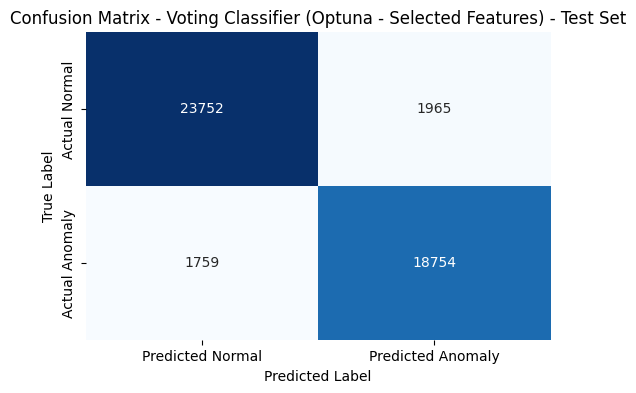

In [ ]:
from sklearn.ensemble import VotingClassifier

# Define the individual classifiers already trained and optimized with Optuna on selected features
estimators_optuna_selected = [
    ('logistic_regression', best_log_reg_selected),
    ('svm', best_svm_selected),
    ('random_forest', best_rf_selected),
    ('xgboost', best_xgb_selected),
    ('lightgbm', best_lgbm_selected)
]

# Initialize the Voting Classifier with 'hard' voting (since LinearSVC doesn't have predict_proba)
voting_clf_optuna_selected = VotingClassifier(estimators=estimators_optuna_selected, voting='hard', n_jobs=-1)

# Fit the Voting Classifier (Note: Each base estimator in a VotingClassifier expects the same X and y)
# This means we need to combine the selected features appropriately or ensure consistency.
# For now, we will use the full X_train_scaled, but ideally, each model in the ensemble would operate on its *own* selected features.
# Since `VotingClassifier` expects a single input feature set, we proceed with the original scaled data.
# The models themselves (e.g., `best_log_reg_selected`) implicitly use the selected features they were trained on when making predictions.
voting_clf_optuna_selected.fit(X_train_scaled, y_train)

# Predictions on Training Set
y_pred_train_vote_optuna_selected = voting_clf_optuna_selected.predict(X_train_scaled)

# Predictions on Test Set
y_pred_test_vote_optuna_selected = voting_clf_optuna_selected.predict(X_test_scaled)

evaluate_and_plot("Voting Classifier (Optuna - Selected Features) - Training Set", y_train, y_pred_train_vote_optuna_selected)
evaluate_and_plot("Voting Classifier (Optuna - Selected Features) - Test Set", y_test, y_pred_test_vote_optuna_selected)

### Model Performance Summary

To effectively compare the performance of all the models, including those tuned with Optuna and those with feature selection, we'll create a summary table. This table will consolidate the F1-score, accuracy, precision, and recall for each model on the test set, making it easier to identify the best-performing models.

In [ ]:
model_performance_summary = pd.DataFrame({
    'Model': [
        'Logistic Regression (Initial)', 'KNN (Initial)', 'SVM (LinearSVC - Initial)',
        'Random Forest (Initial)', 'XGBoost (Initial)', 'LightGBM (Initial)',
        'Logistic Regression (Selected Features - Initial)', 'SVM (Selected Features - Initial)',
        'Random Forest (Selected Features - Initial)', 'XGBoost (Selected Features - Initial)',
        'LightGBM (Selected Features - Initial)',
        'Logistic Regression (Optuna - All Features)', 'KNN (Optuna - All Features)',
        'SVM (Optuna - All Features)', 'Random Forest (Optuna - All Features)',
        'XGBoost (Optuna - All Features)', 'LightGBM (Optuna - All Features)',
        'Logistic Regression (Optuna - Selected Features)', 'SVM (Optuna - Selected Features)',
        'Random Forest (Optuna - Selected Features)', 'XGBoost (Optuna - Selected Features)',
        'LightGBM (Optuna - Selected Features)',
        'Voting Classifier (Initial)', 'Voting Classifier (Optuna - All Features)',
        'Voting Classifier (Optuna - Selected Features)'
    ],
    'Accuracy': [
        accuracy_score(y_test, y_pred_test), accuracy_score(y_test, y_pred_test_knn),
        accuracy_score(y_test, y_pred_test_svm), accuracy_score(y_test, y_pred_test_rf),
        accuracy_score(y_test, y_pred_test_xgb), accuracy_score(y_test, y_pred_test_lgbm),
        accuracy_score(y_test, y_pred_test_log_reg_selected), accuracy_score(y_test, y_pred_test_svm_selected),
        accuracy_score(y_test, y_pred_test_rf_selected), accuracy_score(y_test, y_pred_test_xgb_selected),
        accuracy_score(y_test, y_pred_test_lgbm_selected),
        accuracy_score(y_test, y_pred_test_log_reg_optuna_all), accuracy_score(y_test, y_pred_test_knn_optuna_all),
        accuracy_score(y_test, y_pred_test_svm_optuna_all), accuracy_score(y_test, y_pred_test_rf_optuna_all),
        accuracy_score(y_test, y_pred_test_xgb_optuna_all), accuracy_score(y_test, y_pred_test_lgbm_optuna_all),
        accuracy_score(y_test, y_pred_test_log_reg_optuna_selected), accuracy_score(y_test, y_pred_test_svm_optuna_selected),
        accuracy_score(y_test, y_pred_test_rf_optuna_selected), accuracy_score(y_test, y_pred_test_xgb_optuna_selected),
        accuracy_score(y_test, y_pred_test_lgbm_optuna_selected),
        accuracy_score(y_test, y_pred_test_vote), accuracy_score(y_test, y_pred_test_vote_optuna_all),
        accuracy_score(y_test, y_pred_test_vote_optuna_selected)
    ],
    'Precision': [
        precision_score(y_test, y_pred_test), precision_score(y_test, y_pred_test_knn),
        precision_score(y_test, y_pred_test_svm), precision_score(y_test, y_pred_test_rf),
        precision_score(y_test, y_pred_test_xgb), precision_score(y_test, y_pred_test_lgbm),
        precision_score(y_test, y_pred_test_log_reg_selected), precision_score(y_test, y_pred_test_svm_selected),
        precision_score(y_test, y_pred_test_rf_selected), precision_score(y_test, y_pred_test_xgb_selected),
        precision_score(y_test, y_pred_test_lgbm_selected),
        precision_score(y_test, y_pred_test_log_reg_optuna_all), precision_score(y_test, y_pred_test_knn_optuna_all),
        precision_score(y_test, y_pred_test_svm_optuna_all), precision_score(y_test, y_pred_test_rf_optuna_all),
        precision_score(y_test, y_pred_test_xgb_optuna_all), precision_score(y_test, y_pred_test_lgbm_optuna_all),
        precision_score(y_test, y_pred_test_log_reg_optuna_selected), precision_score(y_test, y_pred_test_svm_optuna_selected),
        precision_score(y_test, y_pred_test_rf_optuna_selected), precision_score(y_test, y_pred_test_xgb_optuna_selected),
        precision_score(y_test, y_pred_test_lgbm_optuna_selected),
        precision_score(y_test, y_pred_test_vote), precision_score(y_test, y_pred_test_vote_optuna_all),
        precision_score(y_test, y_pred_test_vote_optuna_selected)
    ],
    'Recall': [
        recall_score(y_test, y_pred_test), recall_score(y_test, y_pred_test_knn),
        recall_score(y_test, y_pred_test_svm), recall_score(y_test, y_pred_test_rf),
        recall_score(y_test, y_pred_test_xgb), recall_score(y_test, y_pred_test_lgbm),
        recall_score(y_test, y_pred_test_log_reg_selected), recall_score(y_test, y_pred_test_svm_selected),
        recall_score(y_test, y_pred_test_rf_selected), recall_score(y_test, y_pred_test_xgb_selected),
        recall_score(y_test, y_pred_test_lgbm_selected),
        recall_score(y_test, y_pred_test_log_reg_optuna_all), recall_score(y_test, y_pred_test_knn_optuna_all),
        recall_score(y_test, y_pred_test_svm_optuna_all), recall_score(y_test, y_pred_test_rf_optuna_all),
        recall_score(y_test, y_pred_test_xgb_optuna_all), recall_score(y_test, y_pred_test_lgbm_optuna_all),
        recall_score(y_test, y_pred_test_log_reg_optuna_selected), recall_score(y_test, y_pred_test_svm_optuna_selected),
        recall_score(y_test, y_pred_test_rf_optuna_selected), recall_score(y_test, y_pred_test_xgb_optuna_selected),
        recall_score(y_test, y_pred_test_lgbm_optuna_selected),
        recall_score(y_test, y_pred_test_vote), recall_score(y_test, y_pred_test_vote_optuna_all),
        recall_score(y_test, y_pred_test_vote_optuna_selected)
    ],
    'F1-Score': [
        f1_score(y_test, y_pred_test), f1_score(y_test, y_pred_test_knn),
        f1_score(y_test, y_pred_test_svm), f1_score(y_test, y_pred_test_rf),
        f1_score(y_test, y_pred_test_xgb), f1_score(y_test, y_pred_test_lgbm),
        f1_score(y_test, y_pred_test_log_reg_selected), f1_score(y_test, y_pred_test_svm_selected),
        f1_score(y_test, y_pred_test_rf_selected), f1_score(y_test, y_pred_test_xgb_selected),
        f1_score(y_test, y_pred_test_lgbm_selected),
        f1_score(y_test, y_pred_test_log_reg_optuna_all), f1_score(y_test, y_pred_test_knn_optuna_all),
        f1_score(y_test, y_pred_test_svm_optuna_all), f1_score(y_test, y_pred_test_rf_optuna_all),
        f1_score(y_test, y_pred_test_xgb_optuna_all), f1_score(y_test, y_pred_test_lgbm_optuna_all),
        f1_score(y_test, y_pred_test_log_reg_optuna_selected), f1_score(y_test, y_pred_test_svm_optuna_selected),
        f1_score(y_test, y_pred_test_rf_optuna_selected), f1_score(y_test, y_pred_test_xgb_optuna_selected),
        f1_score(y_test, y_pred_test_lgbm_optuna_selected),
        f1_score(y_test, y_pred_test_vote), f1_score(y_test, y_pred_test_vote_optuna_all),
        f1_score(y_test, y_pred_test_vote_optuna_selected)
    ]
})

# Sort by F1-Score to highlight best performing models
model_performance_summary = model_performance_summary.sort_values(by='F1-Score', ascending=False).reset_index(drop=True)

display(model_performance_summary)

,Model,Accuracy,Precision,Recall,F1-Score
0,XGBoost (Optuna - All Features),0.921350,0.922538,0.898162,0.910187
1,Random Forest (Optuna - All Features),0.920722,0.917733,0.902208,0.909904
2,Voting Classifier (Optuna - Selected Features),0.919446,0.905160,0.914250,0.909682
3,LightGBM (Optuna - Selected Features),0.920182,0.923817,0.893823,0.908573
4,Random Forest (Optuna - Selected Features),0.919035,0.917164,0.898698,0.907837
5,LightGBM (Optuna - All Features),0.918451,0.920911,0.892897,0.906688
6,XGBoost (Initial),0.918408,0.921030,0.892653,0.906620
7,Voting Classifier (Optuna - All Features),0.917348,0.914111,0.898113,0.906042
8,XGBoost (Selected Features - Initial),0.917413,0.917646,0.894116,0.905728
9,LightGBM (Initial),0.916937,0.918646,0.891776,0.905012


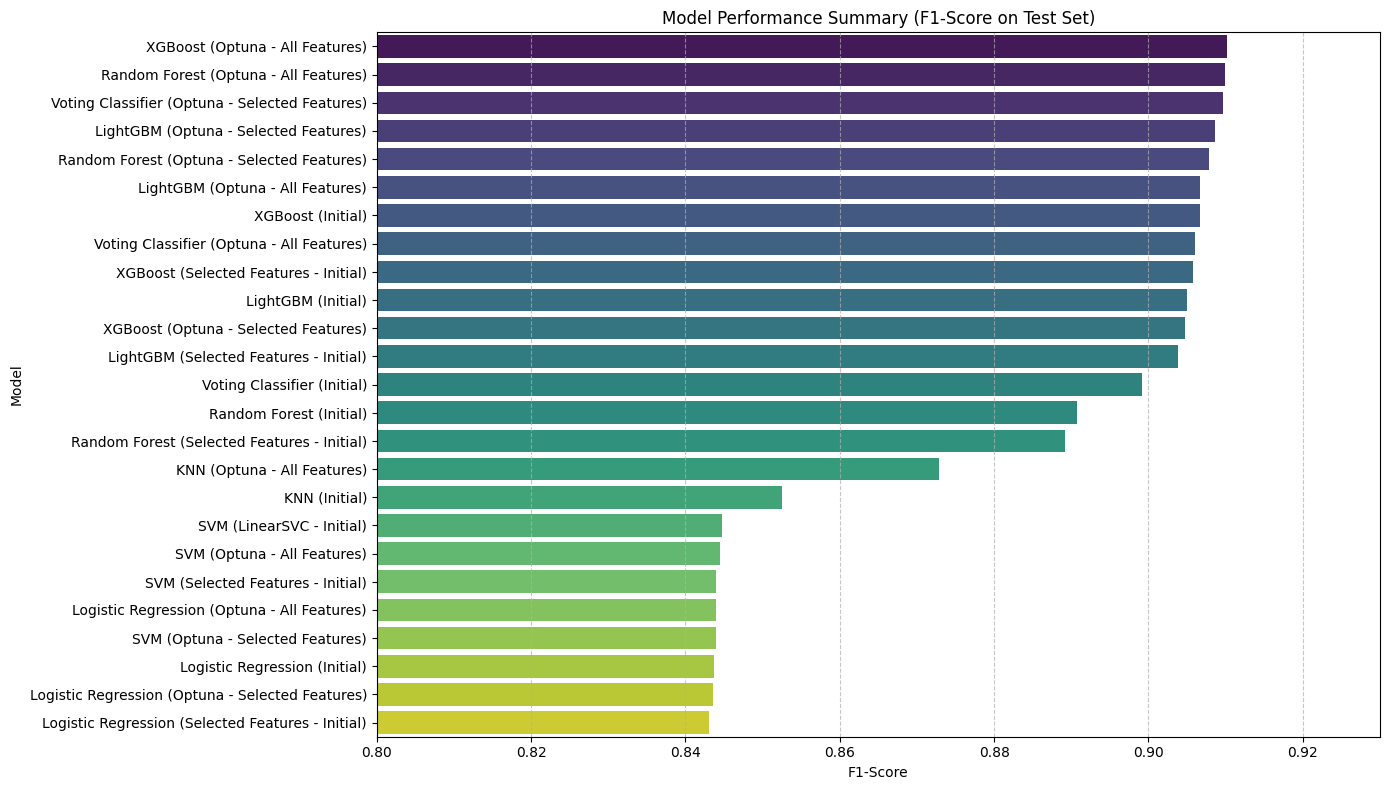

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 8))
sns.barplot(x='F1-Score', y='Model', data=model_performance_summary, palette='viridis')
plt.title('Model Performance Summary (F1-Score on Test Set)')
plt.xlabel('F1-Score')
plt.ylabel('Model')
plt.xlim(0.8, 0.93) # Adjust x-axis limits for better visualization of differences
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

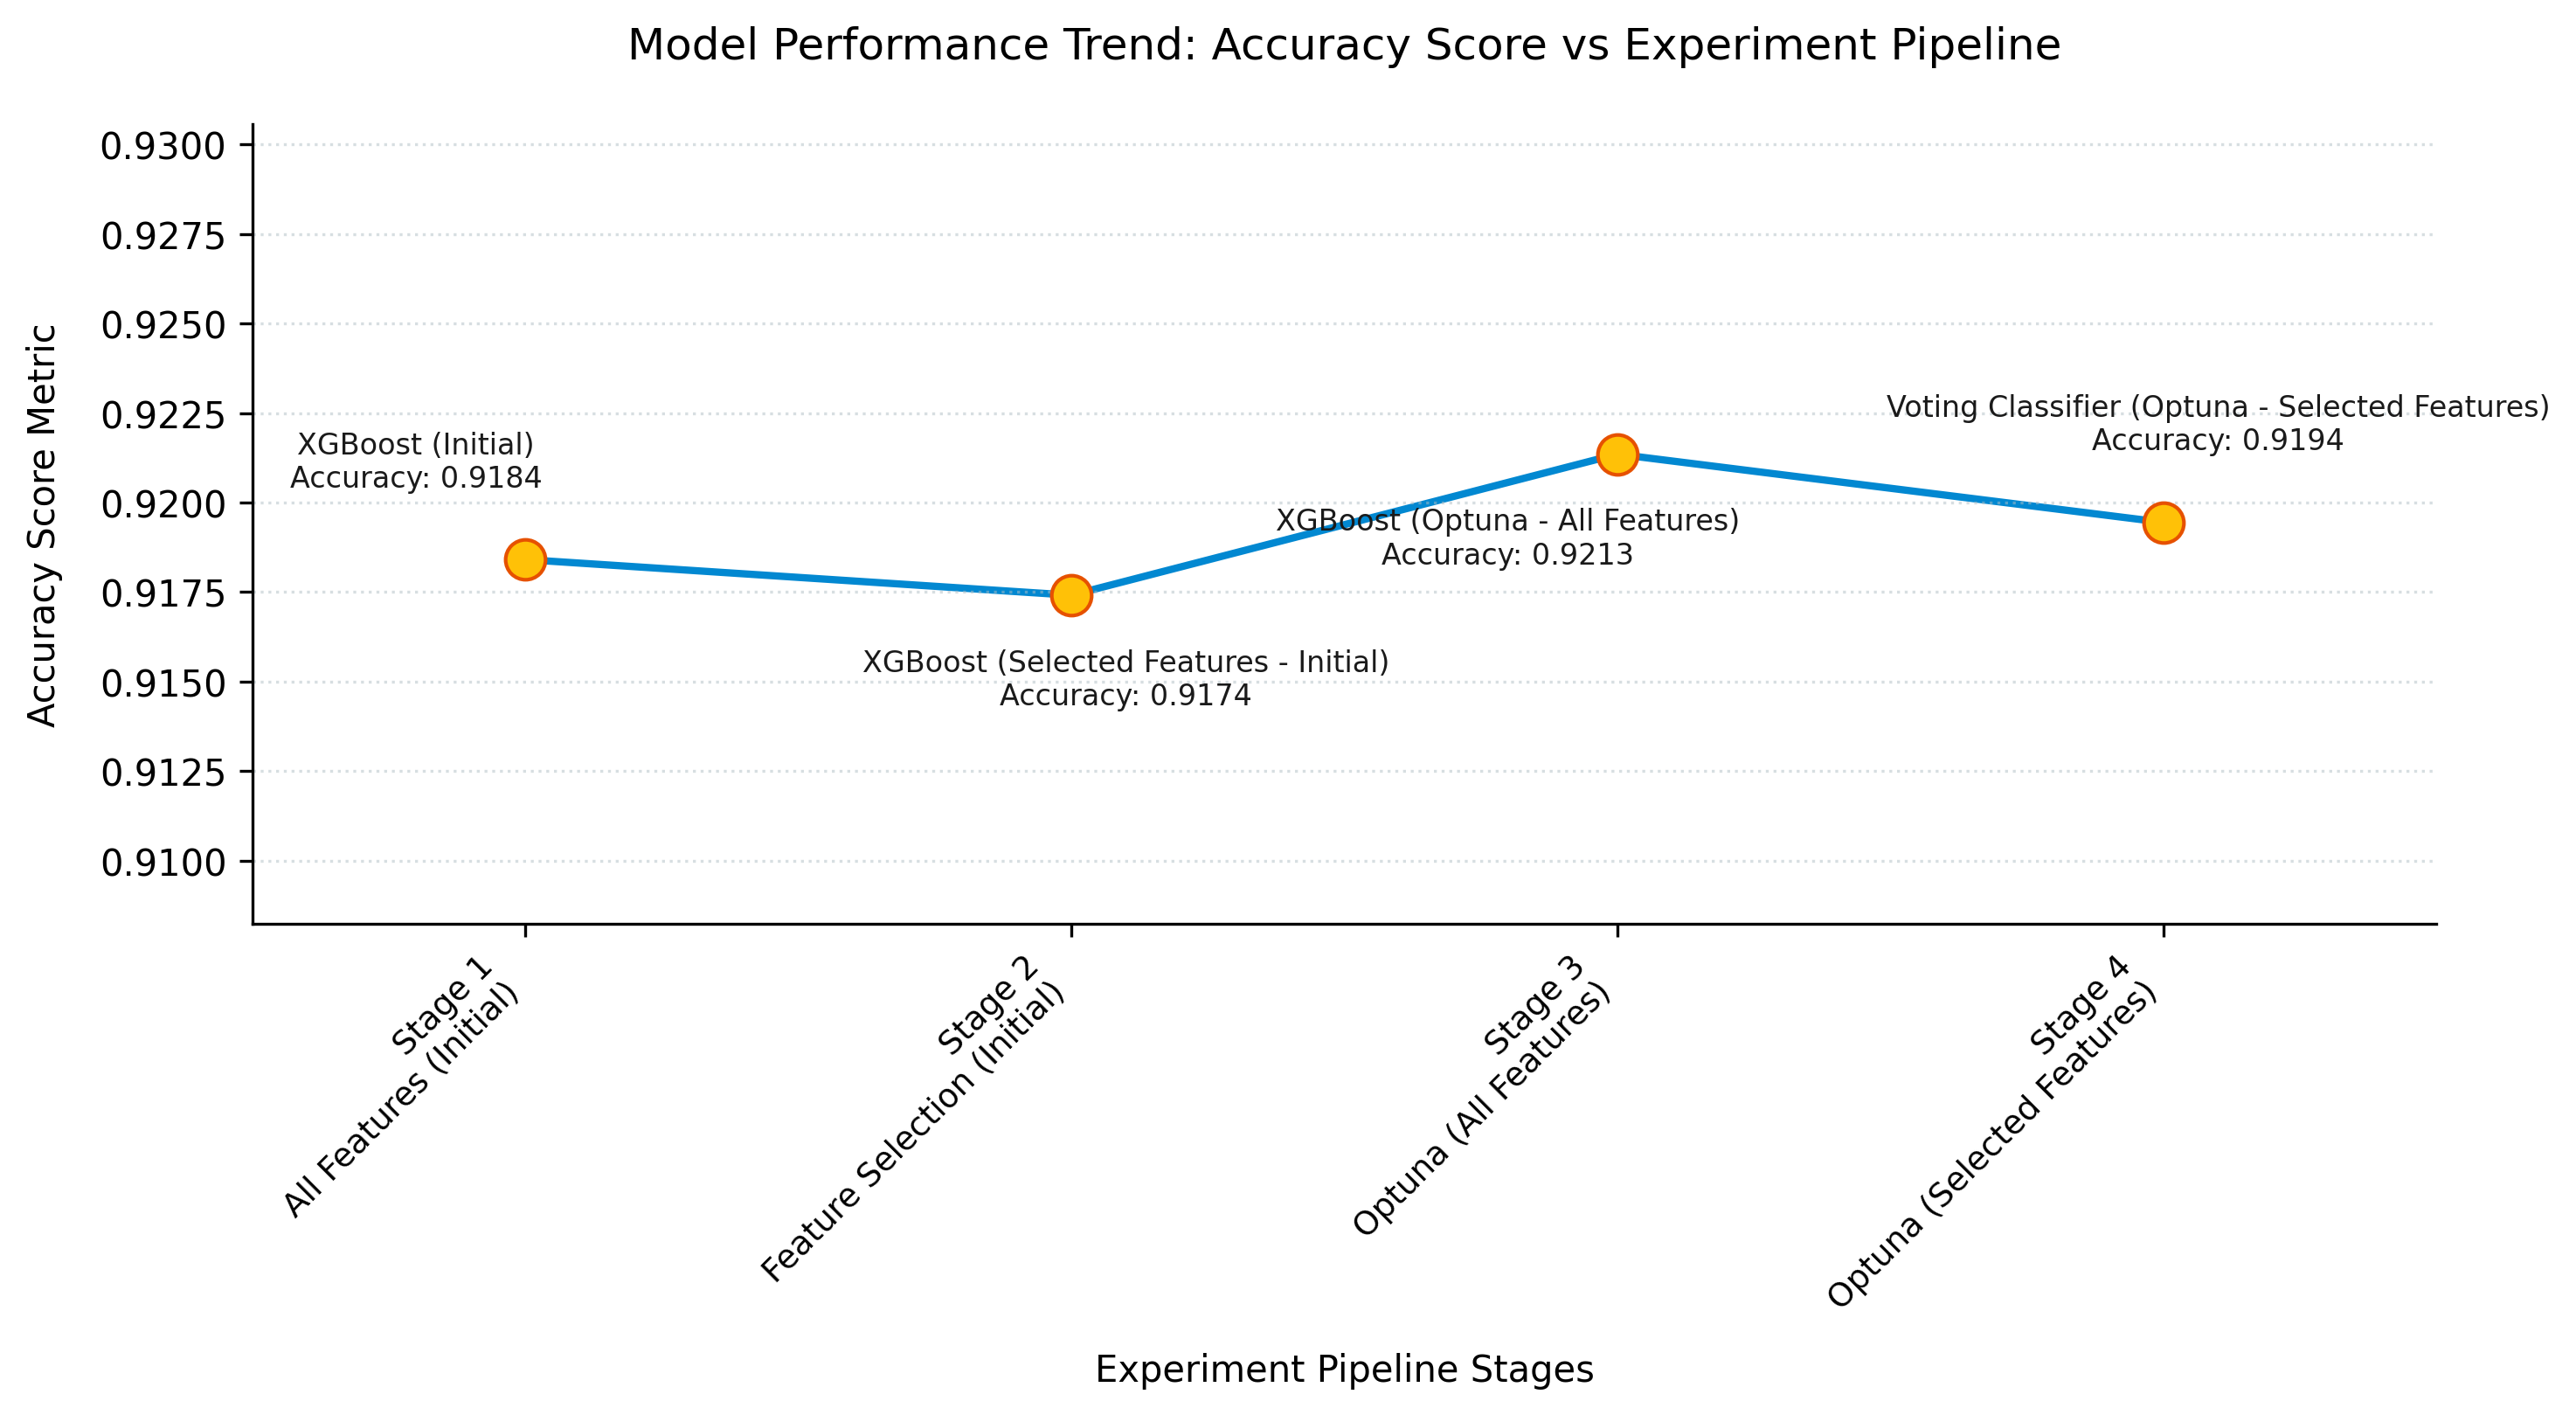

In [ ]:
stages = [
    "Stage 1\nAll Features (Initial)",
    "Stage 2\nFeature Selection (Initial)",
    "Stage 3\nOptuna (All Features)",
    "Stage 4\nOptuna (Selected Features)"
]

# Define patterns for each stage
stage_patterns = {
    "Stage 1\nAll Features (Initial)": [
        'Logistic Regression (Initial)', 'KNN (Initial)', 'SVM (LinearSVC - Initial)',
        'Random Forest (Initial)', 'XGBoost (Initial)', 'LightGBM (Initial)',
        'Voting Classifier (Initial)'
    ],
    "Stage 2\nFeature Selection (Initial)": [
        'Logistic Regression (Selected Features - Initial)', 'SVM (Selected Features - Initial)',
        'Random Forest (Selected Features - Initial)', 'XGBoost (Selected Features - Initial)',
        'LightGBM (Selected Features - Initial)'
    ],
    "Stage 3\nOptuna (All Features)": [
        'Logistic Regression (Optuna - All Features)', 'KNN (Optuna - All Features)',
        'SVM (Optuna - All Features)', 'Random Forest (Optuna - All Features)',
        'XGBoost (Optuna - All Features)', 'LightGBM (Optuna - All Features)',
        'Voting Classifier (Optuna - All Features)'
    ],
    "Stage 4\nOptuna (Selected Features)": [
        'Logistic Regression (Optuna - Selected Features)', 'SVM (Optuna - Selected Features)',
        'Random Forest (Optuna - Selected Features)', 'XGBoost (Optuna - Selected Features)',
        'LightGBM (Optuna - Selected Features)',
        'Voting Classifier (Optuna - Selected Features)'
    ]
}

# Extract best accuracy and model name for each stage
accuracy_values = []
model_names = []
x_positions = [i + 1 for i in range(len(stages))]

for stage_name, patterns in stage_patterns.items():
    # Filter the summary for models belonging to the current stage
    stage_models = model_performance_summary[model_performance_summary['Model'].isin(patterns)]

    if not stage_models.empty:
        # Find the best model in this stage based on F1-Score
        best_model_in_stage = stage_models.loc[stage_models['F1-Score'].idxmax()]
        accuracy_values.append(best_model_in_stage['Accuracy'])
        model_names.append(best_model_in_stage['Model'])
    else:
        accuracy_values.append(None) # Or handle as appropriate if no models found
        model_names.append("N/A")

# Plotting the trend
fig, ax = plt.subplots(figsize=(10, 5.5), dpi=300)

ax.plot(x_positions, accuracy_values, color='#0288D1', linestyle='-', linewidth=2, zorder=1)
ax.scatter(x_positions, accuracy_values, color='#FFC107', s=120, zorder=2, edgecolors='#E65100', linewidths=1)

# Annotate each point with model name and accuracy
for i, txt in enumerate(model_names):
    if accuracy_values[i] is not None:
        # Adjust text position based on stage to prevent overlap
        xy_offset = (15, 5) # Default offset
        if i == 0: # First stage, might need adjustment
            xy_offset = (-30, 20)
        elif i == 1: # Second stage
            xy_offset = (15, -30)
        elif i == 2: # Third stage
             xy_offset = (-30, -30)
        elif i == 3: # Fourth stage, might need adjustment
            xy_offset = (15, 20)

        label_text = f"{txt}\nAccuracy: {accuracy_values[i]:.4f}"
        ax.annotate(label_text, (x_positions[i], accuracy_values[i]), xytext=xy_offset,
                    textcoords='offset points', fontsize=8, color='#1A1A1A', ha='center')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_xlim(0.5, len(stages) + 0.5) # Adjust x-limits to fit all points
ax.set_ylim(min(accuracy_values) * 0.99, max(accuracy_values) * 1.01) # Dynamic y-limits
ax.grid(axis='y', linestyle=':', alpha=0.5, color='#B0BEC5')

ax.set_xticks(x_positions)
ax.set_xticklabels(stages, fontsize=9, rotation=45, ha='right')
ax.set_ylabel("Accuracy Score Metric", fontsize=10, labelpad=10)
ax.set_xlabel("Experiment Pipeline Stages", fontsize=10, labelpad=10)
plt.title("Model Performance Trend: Accuracy Score vs Experiment Pipeline", fontsize=12, pad=18)

plt.tight_layout()
plt.show()

### Model Performance Trend: F1-Score

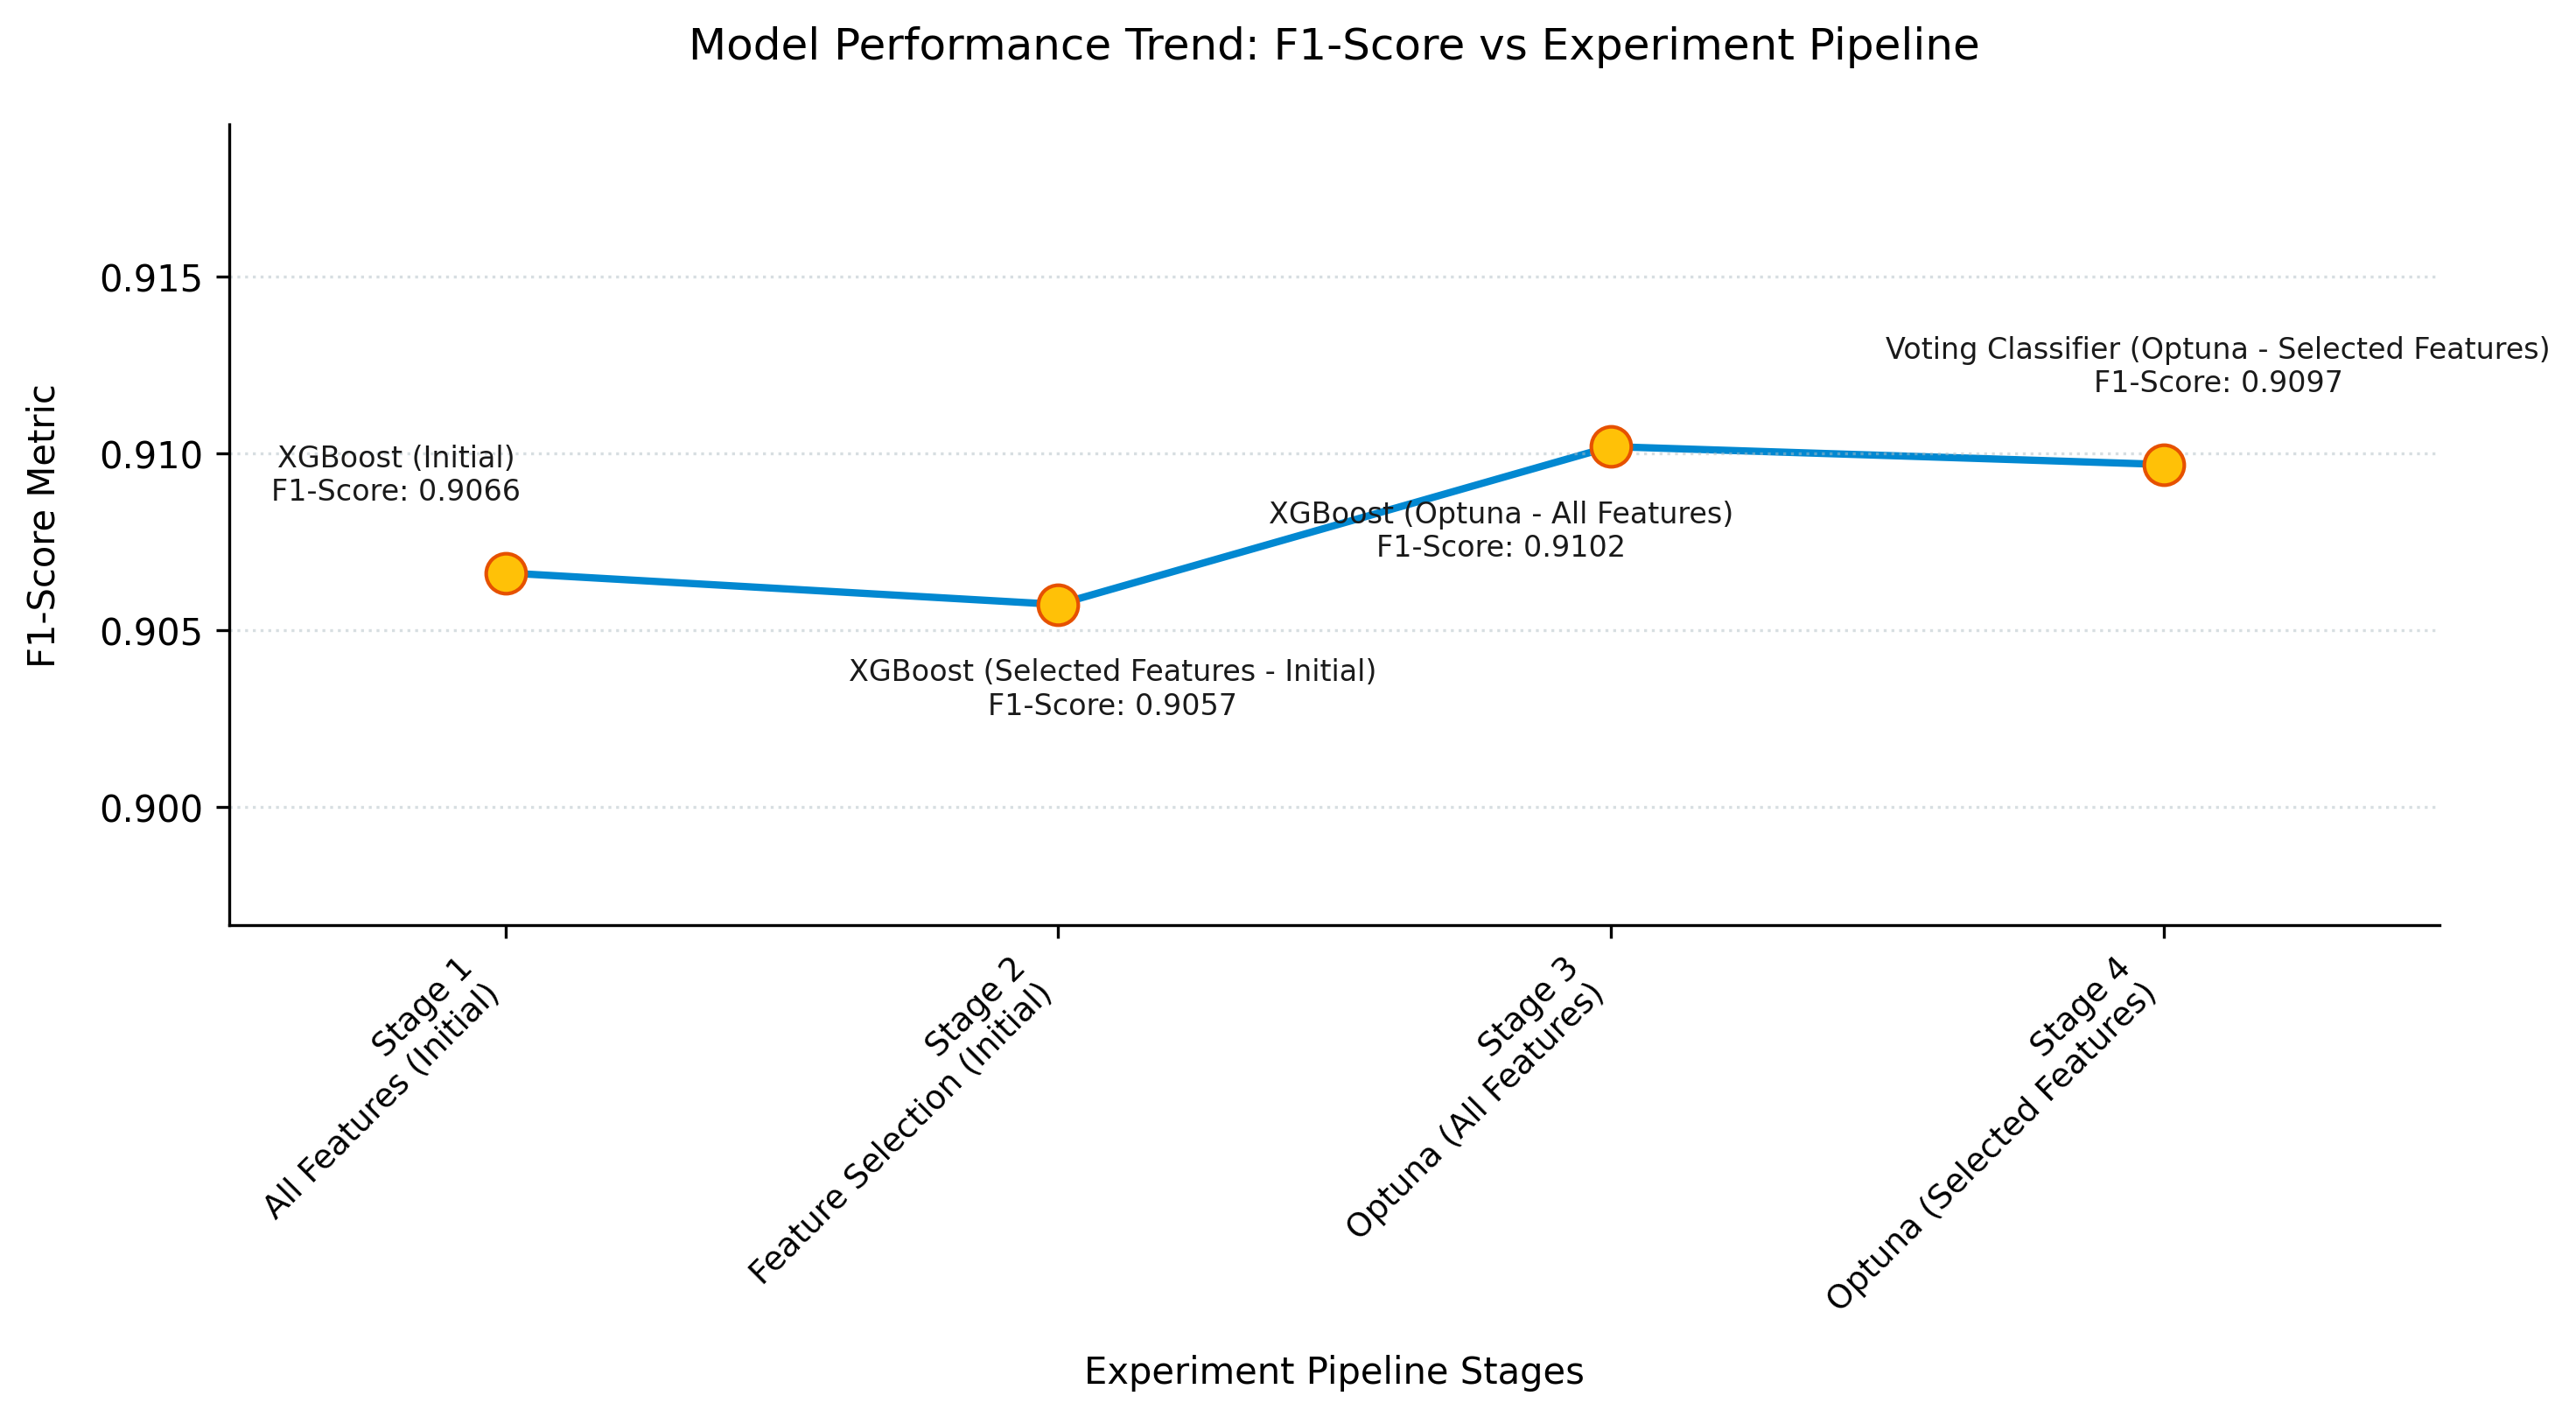

In [ ]:
stages = [
    "Stage 1\nAll Features (Initial)",
    "Stage 2\nFeature Selection (Initial)",
    "Stage 3\nOptuna (All Features)",
    "Stage 4\nOptuna (Selected Features)"
]

# Define patterns for each stage
stage_patterns = {
    "Stage 1\nAll Features (Initial)": [
        'Logistic Regression (Initial)', 'KNN (Initial)', 'SVM (LinearSVC - Initial)',
        'Random Forest (Initial)', 'XGBoost (Initial)', 'LightGBM (Initial)',
        'Voting Classifier (Initial)'
    ],
    "Stage 2\nFeature Selection (Initial)": [
        'Logistic Regression (Selected Features - Initial)', 'SVM (Selected Features - Initial)',
        'Random Forest (Selected Features - Initial)', 'XGBoost (Selected Features - Initial)',
        'LightGBM (Selected Features - Initial)'
    ],
    "Stage 3\nOptuna (All Features)": [
        'Logistic Regression (Optuna - All Features)', 'KNN (Optuna - All Features)',
        'SVM (Optuna - All Features)', 'Random Forest (Optuna - All Features)',
        'XGBoost (Optuna - All Features)', 'LightGBM (Optuna - All Features)',
        'Voting Classifier (Optuna - All Features)'
    ],
    "Stage 4\nOptuna (Selected Features)": [
        'Logistic Regression (Optuna - Selected Features)', 'SVM (Optuna - Selected Features)',
        'Random Forest (Optuna - Selected Features)', 'XGBoost (Optuna - Selected Features)',
        'LightGBM (Optuna - Selected Features)',
        'Voting Classifier (Optuna - Selected Features)'
    ]
}

# Extract best F1-Score and model name for each stage
f1_score_values = []
model_names_f1 = []
x_positions = [i + 1 for i in range(len(stages))]

for stage_name, patterns in stage_patterns.items():
    # Filter the summary for models belonging to the current stage
    stage_models = model_performance_summary[model_performance_summary['Model'].isin(patterns)]

    if not stage_models.empty:
        # Find the best model in this stage based on F1-Score
        best_model_in_stage = stage_models.loc[stage_models['F1-Score'].idxmax()]
        f1_score_values.append(best_model_in_stage['F1-Score'])
        model_names_f1.append(best_model_in_stage['Model'])
    else:
        f1_score_values.append(None) # Or handle as appropriate if no models found
        model_names_f1.append("N/A")

# Plotting the trend
fig, ax = plt.subplots(figsize=(10, 5.5), dpi=300)

ax.plot(x_positions, f1_score_values, color='#0288D1', linestyle='-', linewidth=2, zorder=1)
ax.scatter(x_positions, f1_score_values, color='#FFC107', s=120, zorder=2, edgecolors='#E65100', linewidths=1)

# Annotate each point with model name and F1-score
for i, txt in enumerate(model_names_f1):
    if f1_score_values[i] is not None:
        # Adjust text position based on stage to prevent overlap
        xy_offset = (15, 5) # Default offset
        if i == 0: # First stage, might need adjustment
            xy_offset = (-30, 20)
        elif i == 1: # Second stage
            xy_offset = (15, -30)
        elif i == 2: # Third stage
             xy_offset = (-30, -30)
        elif i == 3: # Fourth stage, might need adjustment
            xy_offset = (15, 20)

        label_text = f"{txt}\nF1-Score: {f1_score_values[i]:.4f}"
        ax.annotate(label_text, (x_positions[i], f1_score_values[i]), xytext=xy_offset,
                    textcoords='offset points', fontsize=8, color='#1A1A1A', ha='center')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_xlim(0.5, len(stages) + 0.5) # Adjust x-limits to fit all points
ax.set_ylim(min(f1_score_values) * 0.99, max(f1_score_values) * 1.01) # Dynamic y-limits
ax.grid(axis='y', linestyle=':', alpha=0.5, color='#B0BEC5')

ax.set_xticks(x_positions)
ax.set_xticklabels(stages, fontsize=9, rotation=45, ha='right')
ax.set_ylabel("F1-Score Metric", fontsize=10, labelpad=10)
ax.set_xlabel("Experiment Pipeline Stages", fontsize=10, labelpad=10)
plt.title("Model Performance Trend: F1-Score vs Experiment Pipeline", fontsize=12, pad=18)

plt.tight_layout()
plt.show()

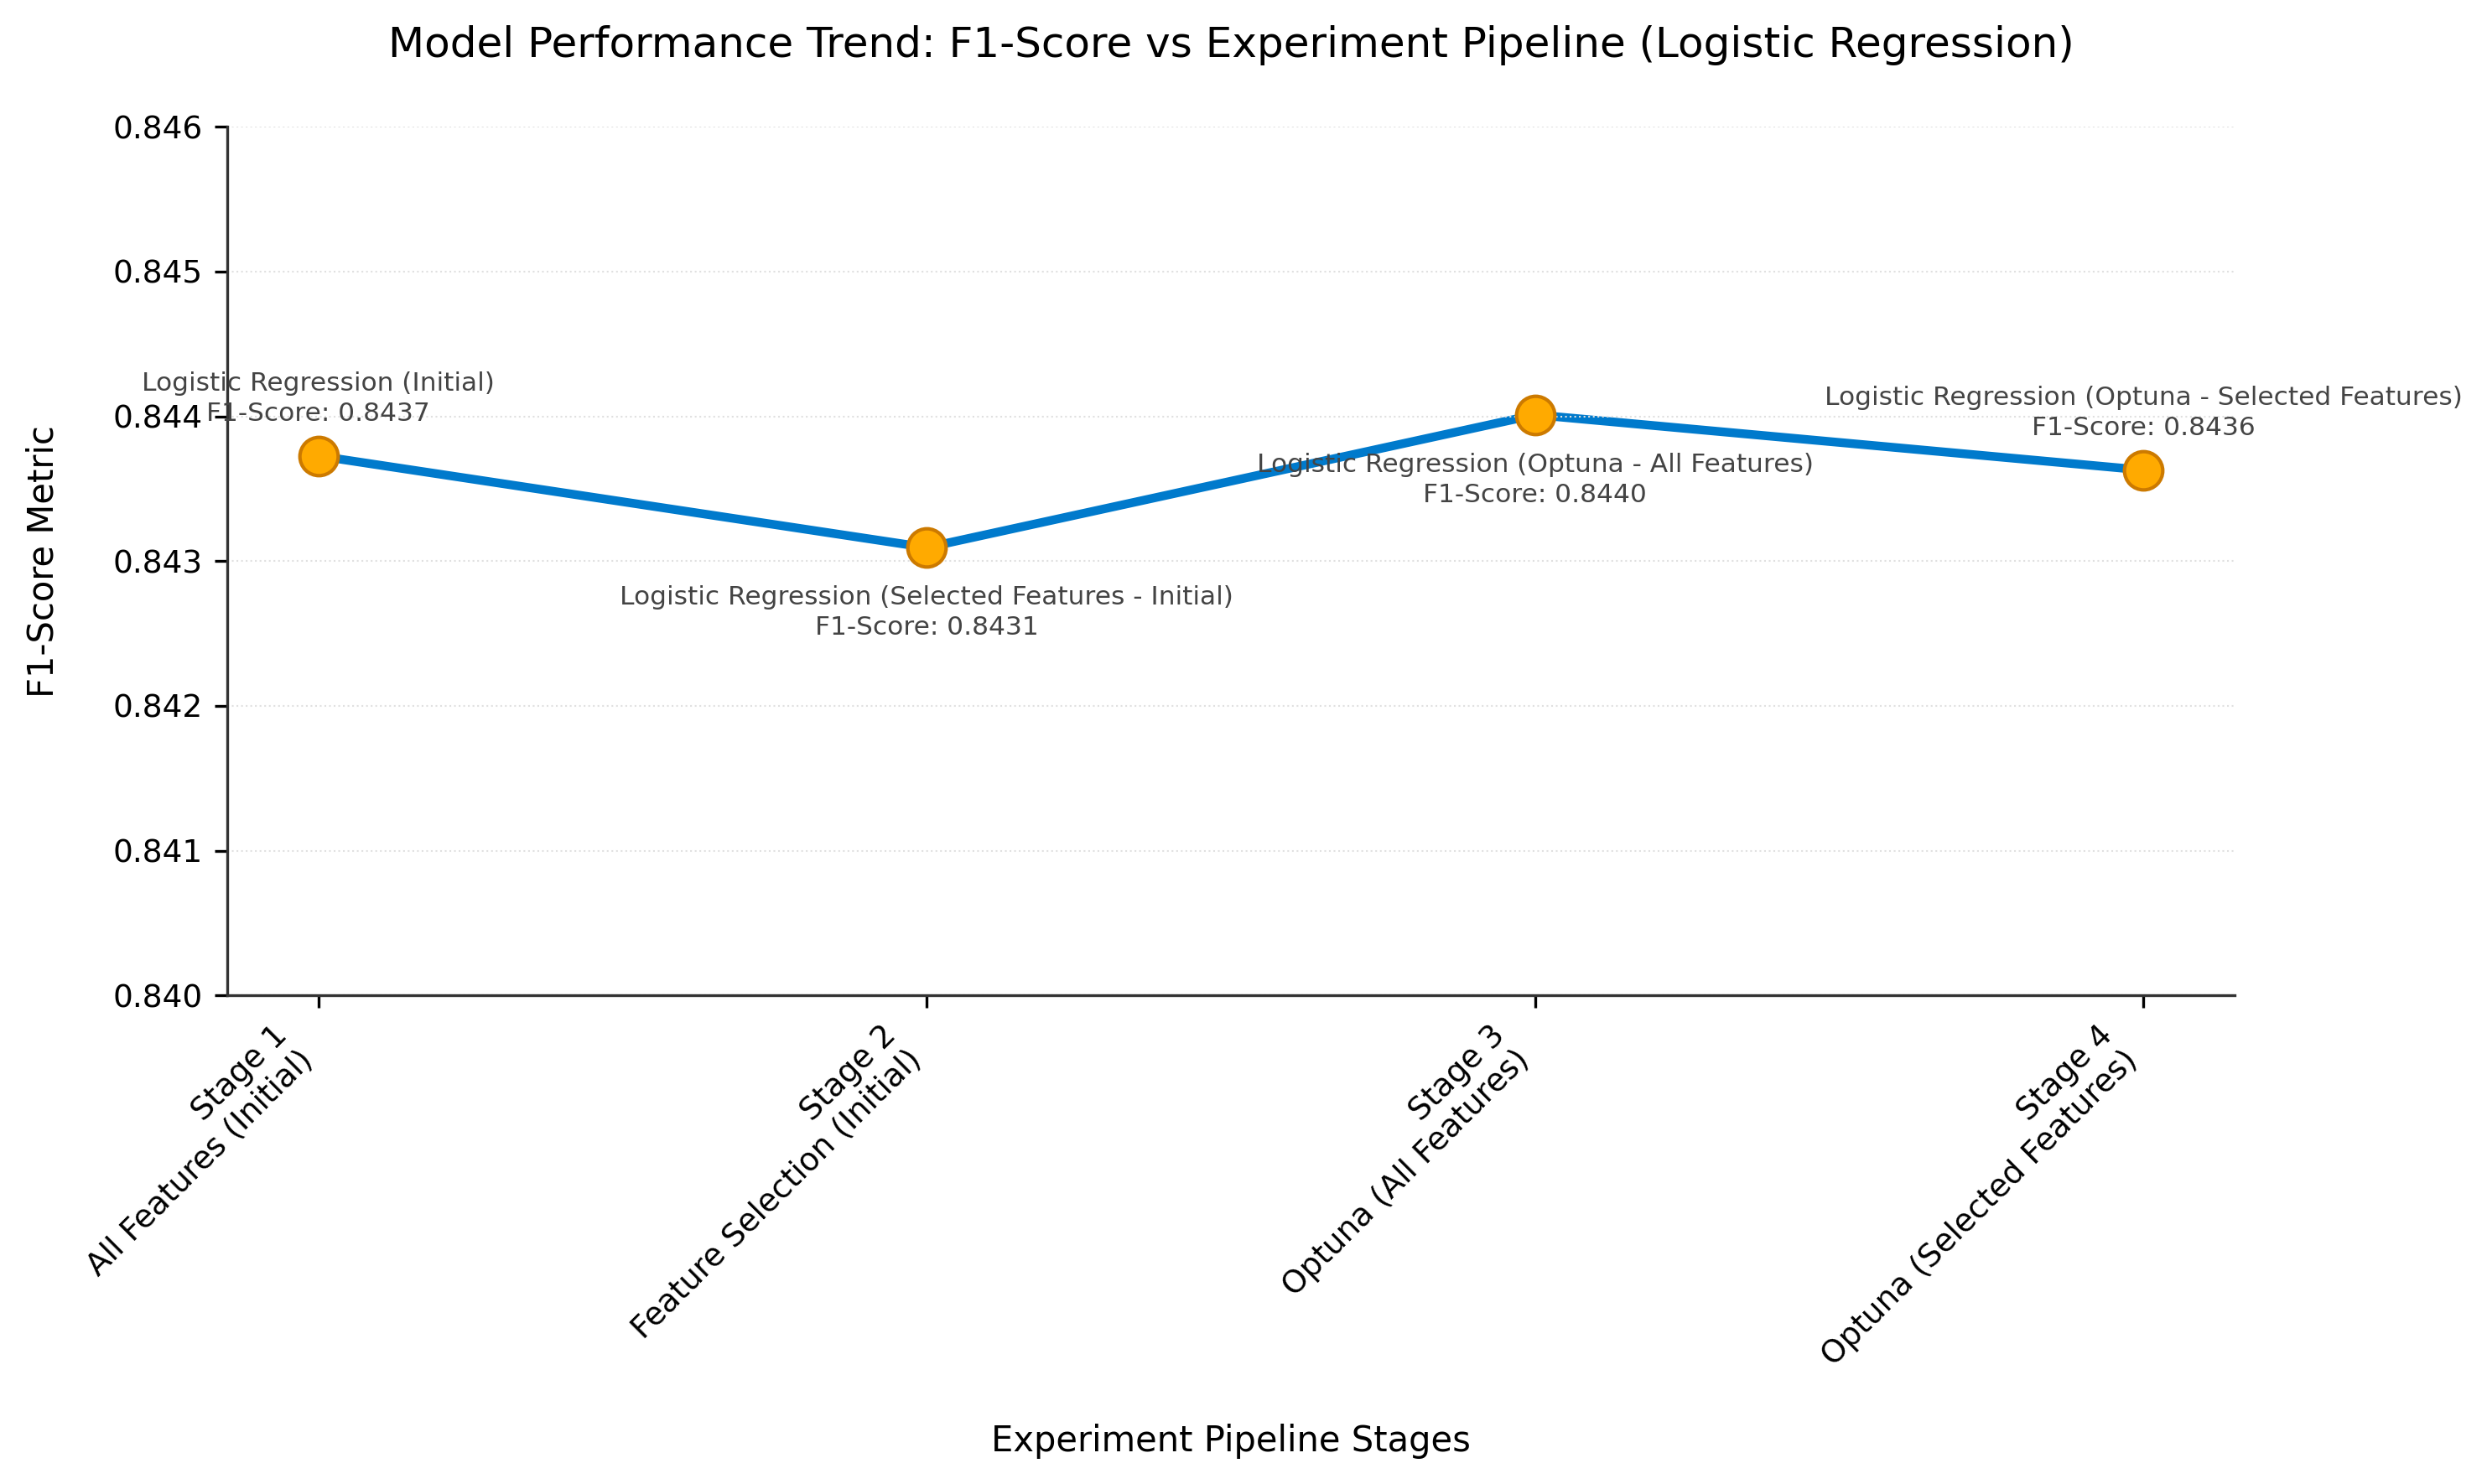

In [ ]:
import matplotlib.pyplot as plt

# 1. Prepare data for Logistic Regression stages extracted from the previous table
stages = [
    "Stage 1\nAll Features (Initial)",
    "Stage 2\nFeature Selection (Initial)",
    "Stage 3\nOptuna (All Features)",
    "Stage 4\nOptuna (Selected Features)"
]

# Extracted F1-Scores for Logistic Regression from your dataset
f1_scores = [0.843727, 0.843094, 0.844011, 0.843629]

labels = [
    "Logistic Regression (Initial)\nF1-Score: 0.8437",
    "Logistic Regression (Selected Features - Initial)\nF1-Score: 0.8431",
    "Logistic Regression (Optuna - All Features)\nF1-Score: 0.8440",
    "Logistic Regression (Optuna - Selected Features)\nF1-Score: 0.8436"
]

# 2. Setup the plot style
fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
ax.set_facecolor('white')
fig.patch.set_facecolor('white')

# 3. Plot the trend line and markers
ax.plot(stages, f1_scores, color='#007acc', linewidth=2.5, zorder=1)
ax.scatter(stages, f1_scores, color='#ffaa00', edgecolors='#cc7a00', s=120, zorder=2)

# 4. Format axes and labels
ax.set_title("Model Performance Trend: F1-Score vs Experiment Pipeline (Logistic Regression)",
             fontsize=12, pad=20, fontweight='normal', family='sans-serif')
ax.set_xlabel("Experiment Pipeline Stages", fontsize=10, labelpad=15)
ax.set_ylabel("F1-Score Metric", fontsize=10, labelpad=15)

# Adjust y-axis limits to scale comfortably around the data range
ax.set_ylim(0.8400, 0.8460)

# Rotate X-axis labels to match the style of the target graph
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)

# Add light horizontal gridlines
ax.grid(axis='y', linestyle=':', linewidth=0.5, color='#e0e0e0')

# Hide top and right spines for a clean look
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#333333')
ax.spines['bottom'].set_color('#333333')

# 5. Dynamic text annotation offsets to mimic the source layout
# Alternate label positioning (above/below) to prevent overlap issues
offsets = [
    (0, 10),    # Stage 1: Above
    (0, -25),   # Stage 2: Below
    (0, -25),   # Stage 3: Below
    (0, 10)     # Stage 4: Above
]

for i, (txt, offset) in enumerate(zip(labels, offsets)):
    ax.annotate(
        txt,
        (stages[i], f1_scores[i]),
        textcoords="offset points",
        xytext=offset,
        ha='center',
        fontsize=7.5,
        color='#444444',
        linespacing=1.3
    )

# 6. Render and clean up layout boundaries
plt.tight_layout()
plt.show()


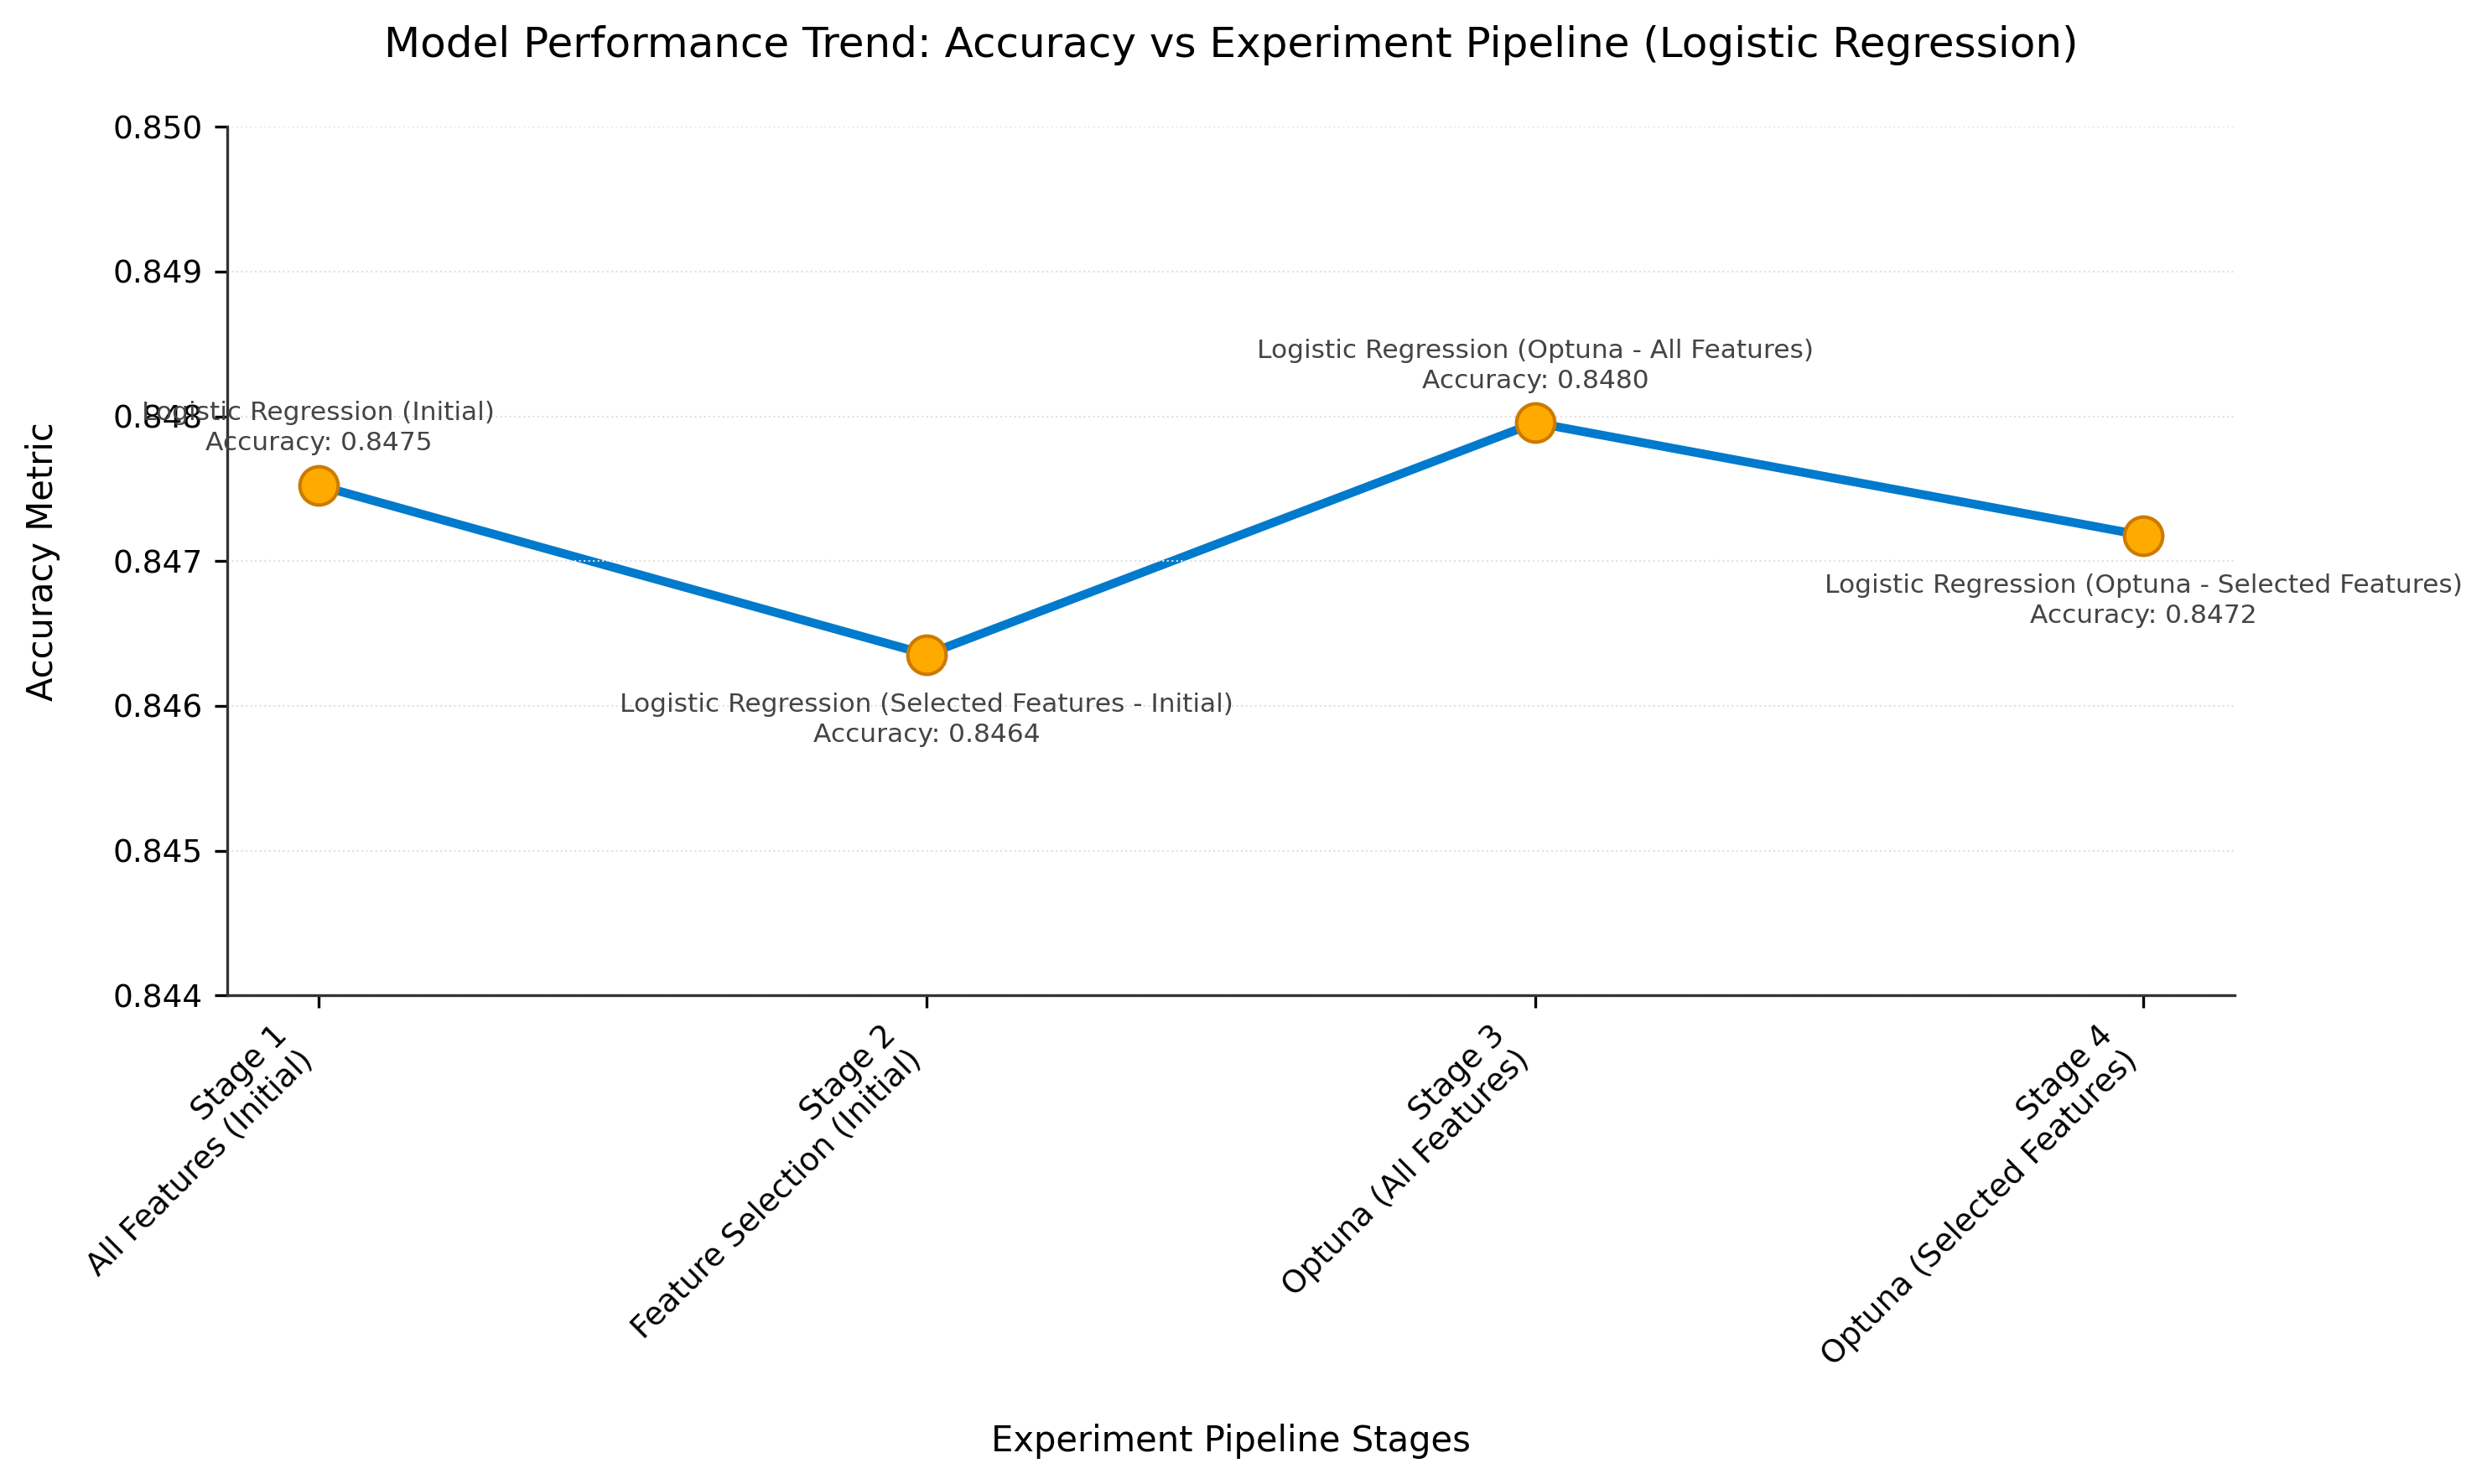

In [ ]:
import matplotlib.pyplot as plt

# 1. Prepare data for Logistic Regression stages extracted from the table
stages = [
    "Stage 1\nAll Features (Initial)",
    "Stage 2\nFeature Selection (Initial)",
    "Stage 3\nOptuna (All Features)",
    "Stage 4\nOptuna (Selected Features)"
]

# Extracted Accuracy values for Logistic Regression from your dataset
accuracy_scores = [0.847523, 0.846355, 0.847956, 0.847177]

labels = [
    "Logistic Regression (Initial)\nAccuracy: 0.8475",
    "Logistic Regression (Selected Features - Initial)\nAccuracy: 0.8464",
    "Logistic Regression (Optuna - All Features)\nAccuracy: 0.8480",
    "Logistic Regression (Optuna - Selected Features)\nAccuracy: 0.8472"
]

# 2. Setup the plot style
fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
ax.set_facecolor('white')
fig.patch.set_facecolor('white')

# 3. Plot the trend line and markers
ax.plot(stages, accuracy_scores, color='#007acc', linewidth=2.5, zorder=1)
ax.scatter(stages, accuracy_scores, color='#ffaa00', edgecolors='#cc7a00', s=120, zorder=2)

# 4. Format axes and labels
ax.set_title("Model Performance Trend: Accuracy vs Experiment Pipeline (Logistic Regression)",
             fontsize=12, pad=20, fontweight='normal', family='sans-serif')
ax.set_xlabel("Experiment Pipeline Stages", fontsize=10, labelpad=15)
ax.set_ylabel("Accuracy Metric", fontsize=10, labelpad=15)

# Adjust y-axis limits to fit the Accuracy distribution scale properly
ax.set_ylim(0.8440, 0.8500)

# Rotate X-axis labels to match the graph style
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)

# Add light horizontal gridlines
ax.grid(axis='y', linestyle=':', linewidth=0.5, color='#e0e0e0')

# Hide top and right borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#333333')
ax.spines['bottom'].set_color('#333333')

# 5. Text annotation position offsets to keep it clean and readable
offsets = [
    (0, 10),    # Stage 1: Above
    (0, -25),   # Stage 2: Below
    (0, 10),    # Stage 3: Above
    (0, -25)    # Stage 4: Below
]

for i, (txt, offset) in enumerate(zip(labels, offsets)):
    ax.annotate(
        txt,
        (stages[i], accuracy_scores[i]),
        textcoords="offset points",
        xytext=offset,
        ha='center',
        fontsize=7.5,
        color='#444444',
        linespacing=1.3
    )

# 6. Render and clean up layout boundaries
plt.tight_layout()
plt.show()


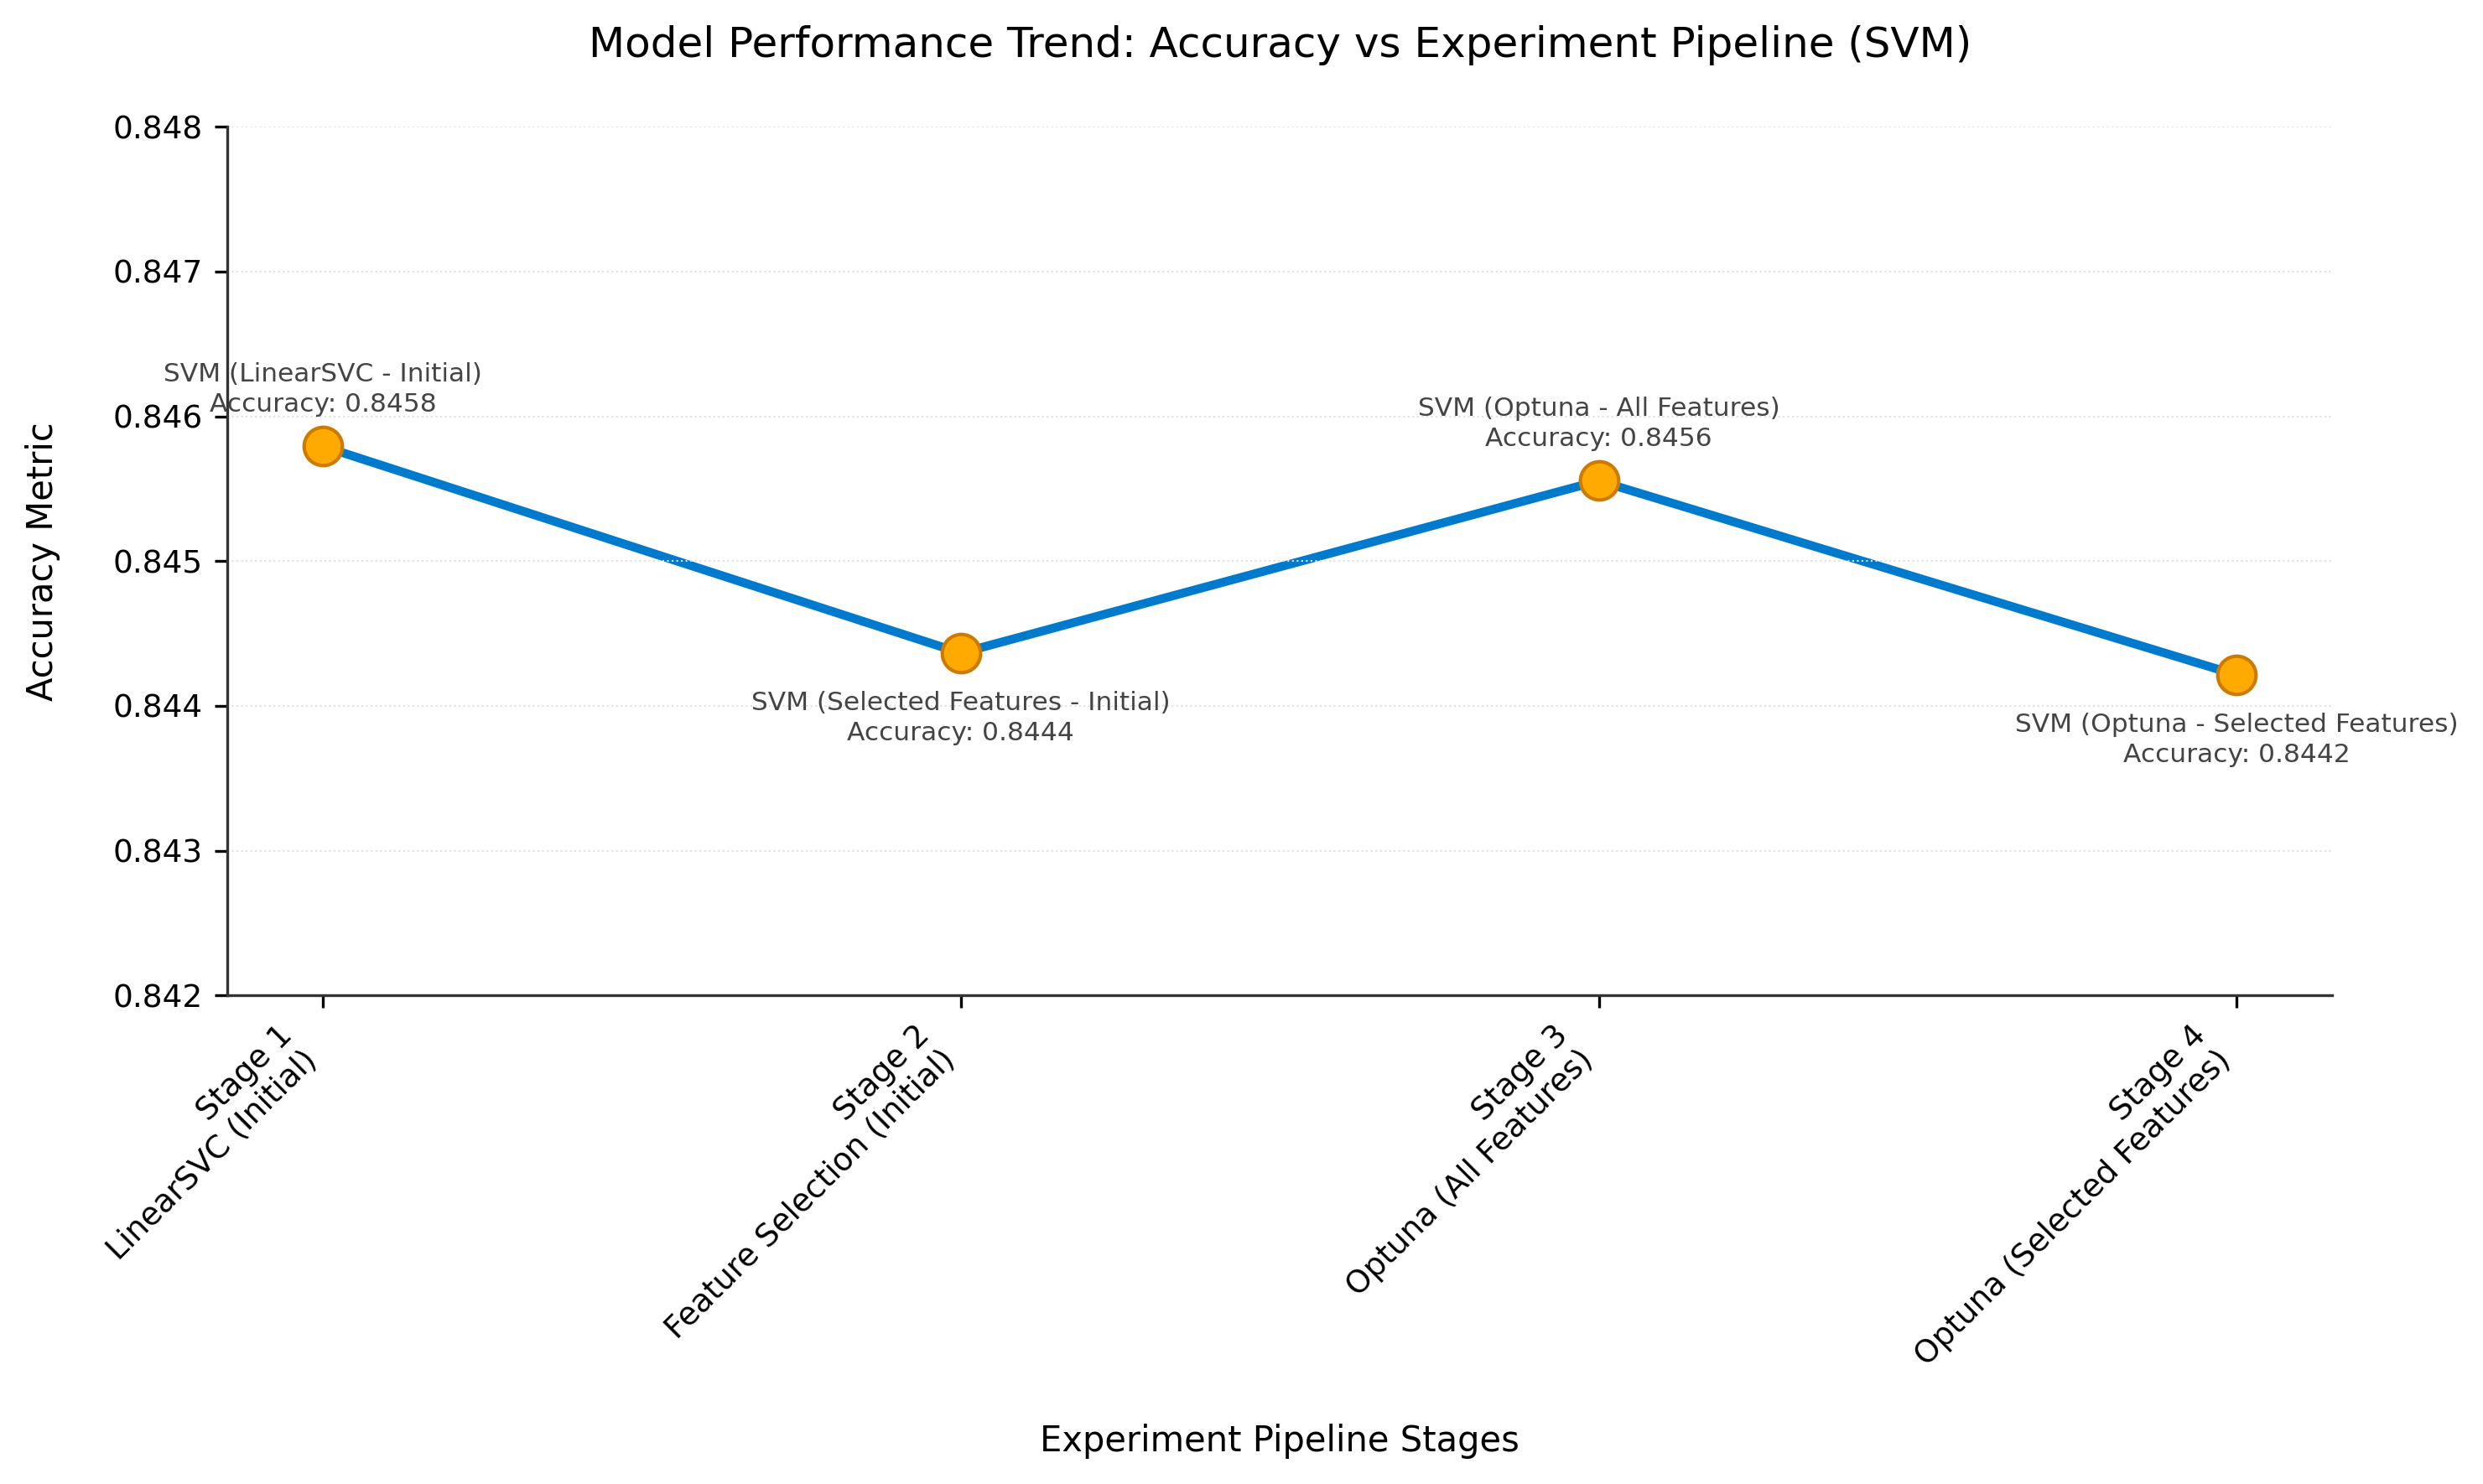

In [ ]:
import matplotlib.pyplot as plt

# 1. Prepare data for SVM stages extracted from the table
stages = [
    "Stage 1\nLinearSVC (Initial)",
    "Stage 2\nFeature Selection (Initial)",
    "Stage 3\nOptuna (All Features)",
    "Stage 4\nOptuna (Selected Features)"
]

# Extracted Accuracy values for SVM from your dataset
accuracy_scores = [0.845793, 0.844365, 0.845555, 0.844214]

labels = [
    "SVM (LinearSVC - Initial)\nAccuracy: 0.8458",
    "SVM (Selected Features - Initial)\nAccuracy: 0.8444",
    "SVM (Optuna - All Features)\nAccuracy: 0.8456",
    "SVM (Optuna - Selected Features)\nAccuracy: 0.8442"
]

# 2. Setup the plot style
fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
ax.set_facecolor('white')
fig.patch.set_facecolor('white')

# 3. Plot the trend line and markers
ax.plot(stages, accuracy_scores, color='#007acc', linewidth=2.5, zorder=1)
ax.scatter(stages, accuracy_scores, color='#ffaa00', edgecolors='#cc7a00', s=120, zorder=2)

# 4. Format axes and labels
ax.set_title("Model Performance Trend: Accuracy vs Experiment Pipeline (SVM)",
             fontsize=12, pad=20, fontweight='normal', family='sans-serif')
ax.set_xlabel("Experiment Pipeline Stages", fontsize=10, labelpad=15)
ax.set_ylabel("Accuracy Metric", fontsize=10, labelpad=15)

# Adjust y-axis limits to fit the SVM Accuracy variance profile comfortably
ax.set_ylim(0.8420, 0.8480)

# Rotate X-axis labels to match the graph style
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)

# Add light horizontal gridlines
ax.grid(axis='y', linestyle=':', linewidth=0.5, color='#e0e0e0')

# Hide top and right borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#333333')
ax.spines['bottom'].set_color('#333333')

# 5. Text annotation position offsets adjusted to keep it clean and readable
offsets = [
    (0, 10),    # Stage 1: Above
    (0, -25),   # Stage 2: Below
    (0, 10),    # Stage 3: Above
    (0, -25)    # Stage 4: Below
]

for i, (txt, offset) in enumerate(zip(labels, offsets)):
    ax.annotate(
        txt,
        (stages[i], accuracy_scores[i]),
        textcoords="offset points",
        xytext=offset,
        ha='center',
        fontsize=7.5,
        color='#444444',
        linespacing=1.3
    )

# 6. Render and clean up layout boundaries
plt.tight_layout()
plt.show()


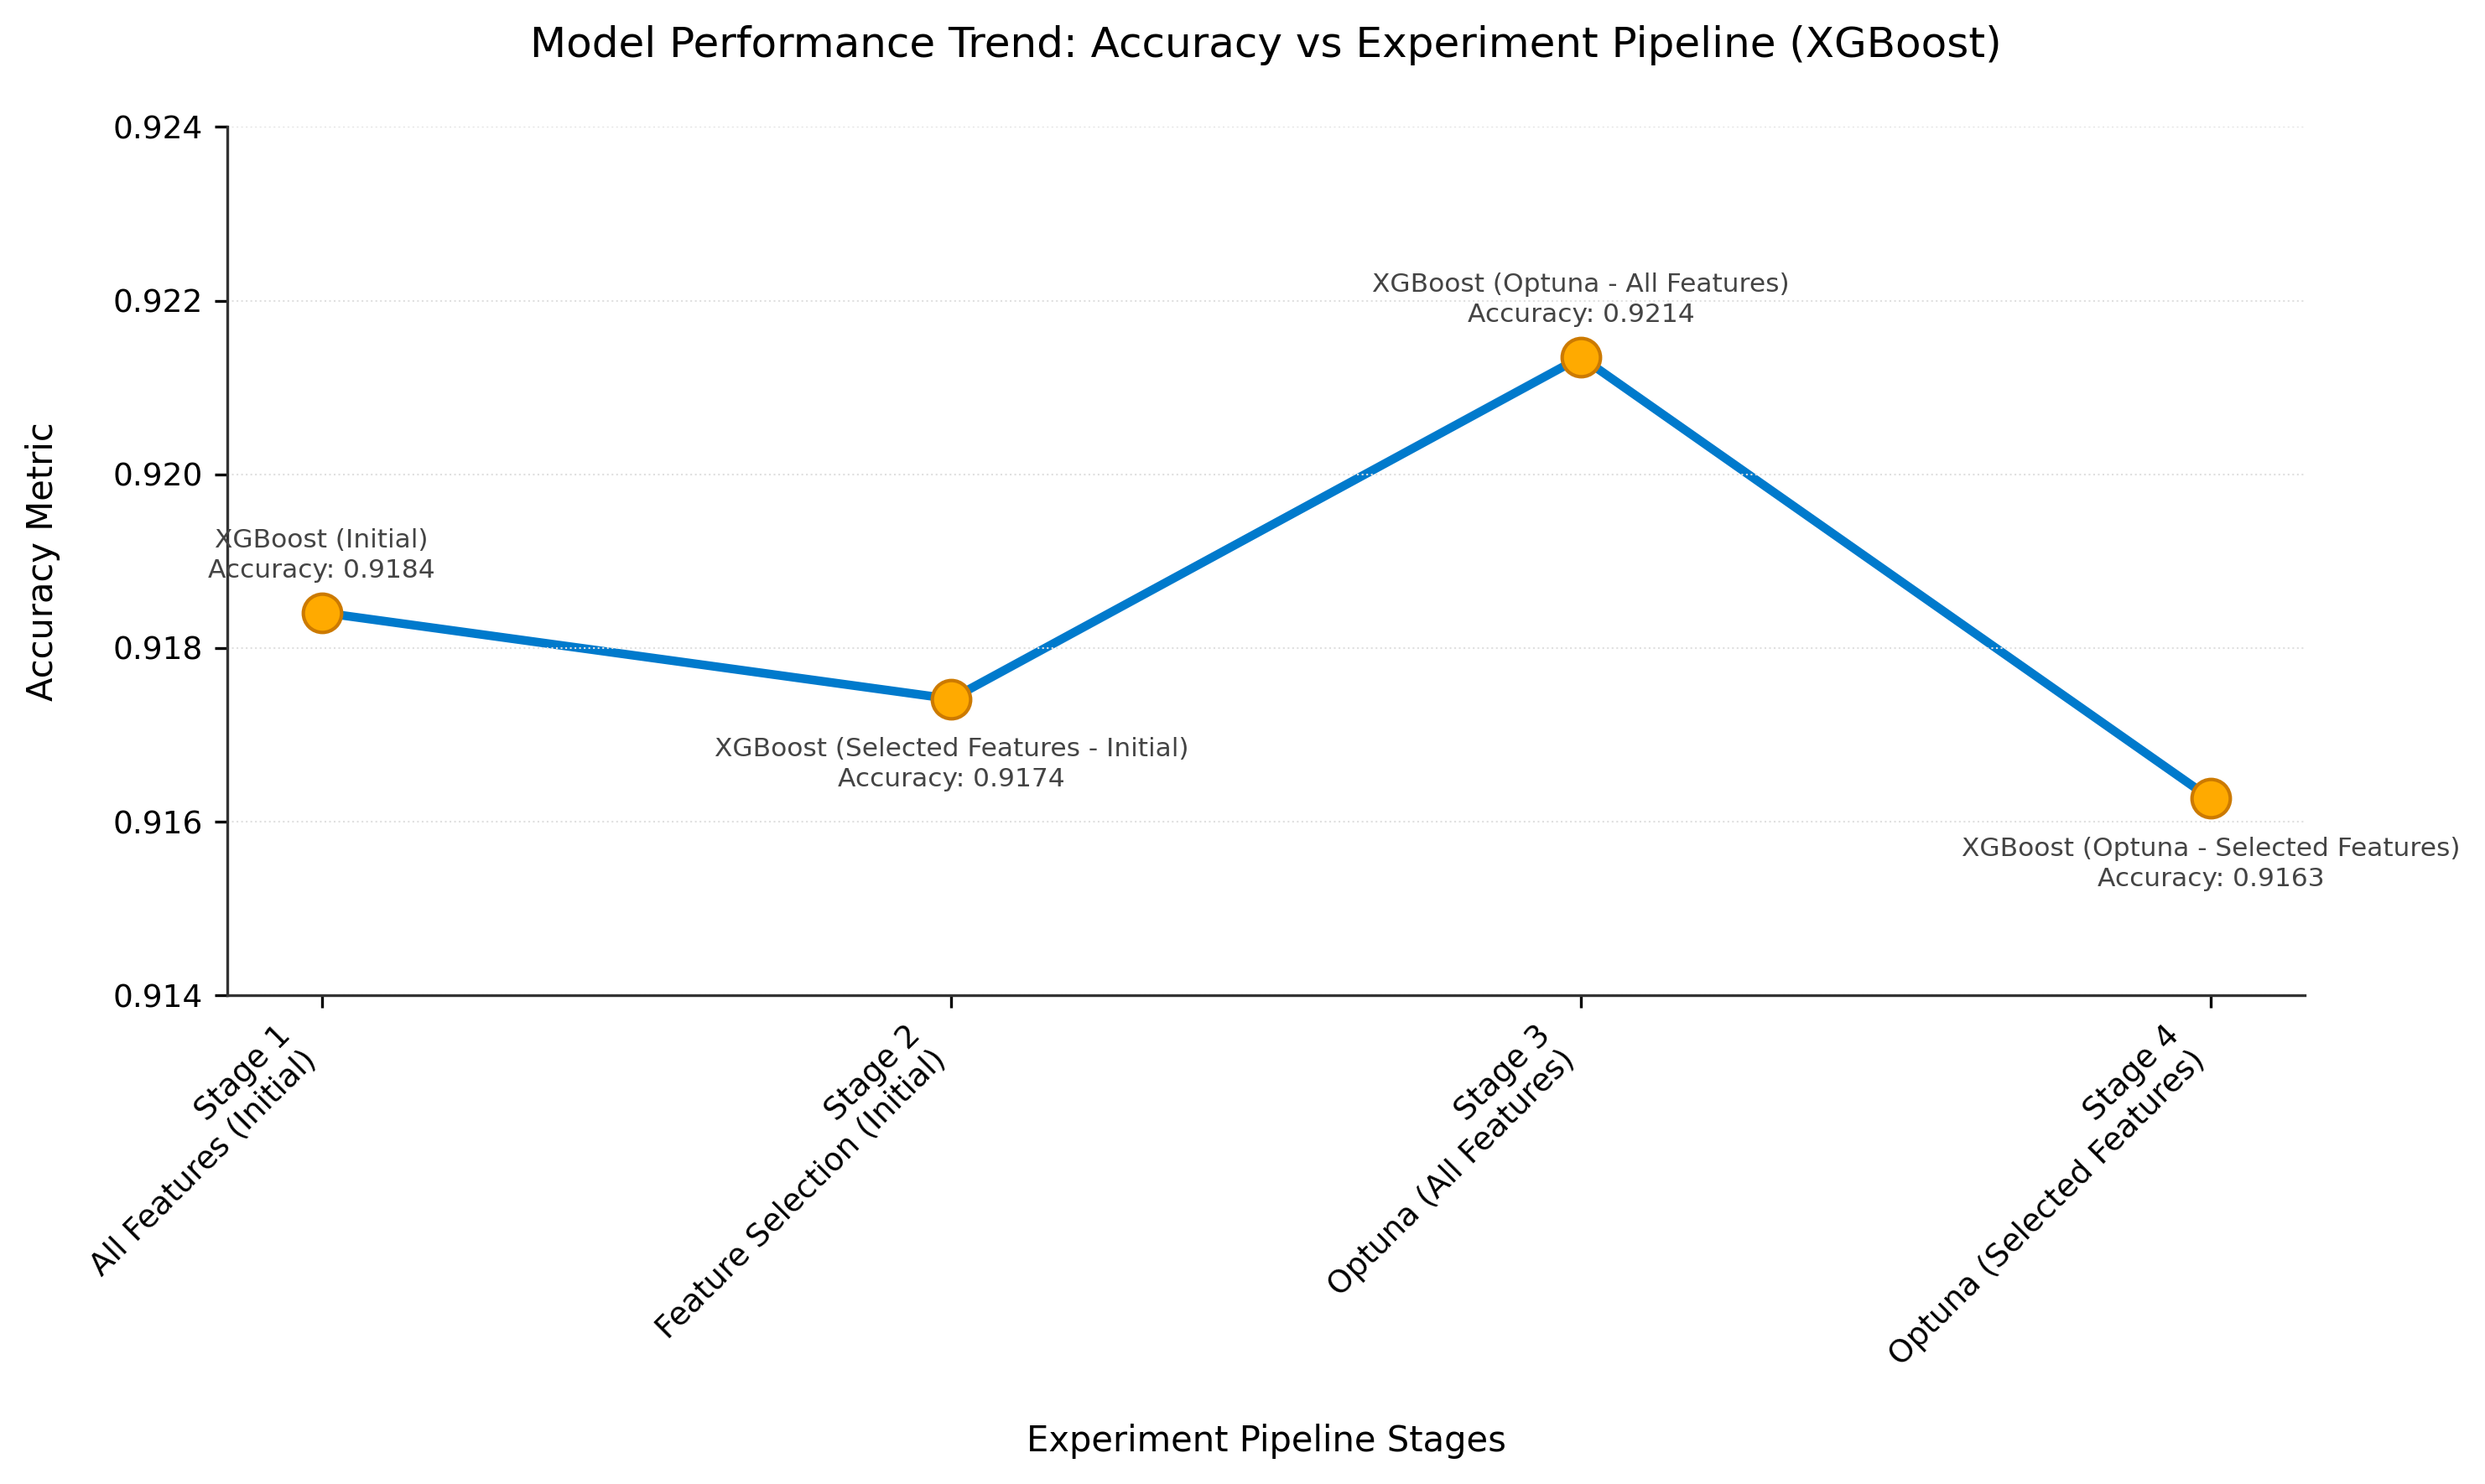

In [ ]:
import matplotlib.pyplot as plt

# 1. Prepare data for XGBoost stages extracted from the table
stages = [
    "Stage 1\nAll Features (Initial)",
    "Stage 2\nFeature Selection (Initial)",
    "Stage 3\nOptuna (All Features)",
    "Stage 4\nOptuna (Selected Features)"
]

# Extracted Accuracy values for XGBoost from your dataset
accuracy_scores = [0.918408, 0.917413, 0.921350, 0.916266]

labels = [
    "XGBoost (Initial)\nAccuracy: 0.9184",
    "XGBoost (Selected Features - Initial)\nAccuracy: 0.9174",
    "XGBoost (Optuna - All Features)\nAccuracy: 0.9214",
    "XGBoost (Optuna - Selected Features)\nAccuracy: 0.9163"
]

# 2. Setup the plot style
fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
ax.set_facecolor('white')
fig.patch.set_facecolor('white')

# 3. Plot the trend line and markers
ax.plot(stages, accuracy_scores, color='#007acc', linewidth=2.5, zorder=1)
ax.scatter(stages, accuracy_scores, color='#ffaa00', edgecolors='#cc7a00', s=120, zorder=2)

# 4. Format axes and labels
ax.set_title("Model Performance Trend: Accuracy vs Experiment Pipeline (XGBoost)",
             fontsize=12, pad=20, fontweight='normal', family='sans-serif')
ax.set_xlabel("Experiment Pipeline Stages", fontsize=10, labelpad=15)
ax.set_ylabel("Accuracy Metric", fontsize=10, labelpad=15)

# Adjust y-axis limits to fit the XGBoost Accuracy variance profile comfortably
ax.set_ylim(0.9140, 0.9240)

# Rotate X-axis labels to match the graph style
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)

# Add light horizontal gridlines
ax.grid(axis='y', linestyle=':', linewidth=0.5, color='#e0e0e0')

# Hide top and right borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#333333')
ax.spines['bottom'].set_color('#333333')

# 5. Text annotation position offsets adjusted to keep it clean and readable
offsets = [
    (0, 10),    # Stage 1: Above
    (0, -25),   # Stage 2: Below
    (0, 10),    # Stage 3: Above
    (0, -25)    # Stage 4: Below
]

for i, (txt, offset) in enumerate(zip(labels, offsets)):
    ax.annotate(
        txt,
        (stages[i], accuracy_scores[i]),
        textcoords="offset points",
        xytext=offset,
        ha='center',
        fontsize=7.5,
        color='#444444',
        linespacing=1.3
    )

# 6. Render and clean up layout boundaries
plt.tight_layout()
plt.show()


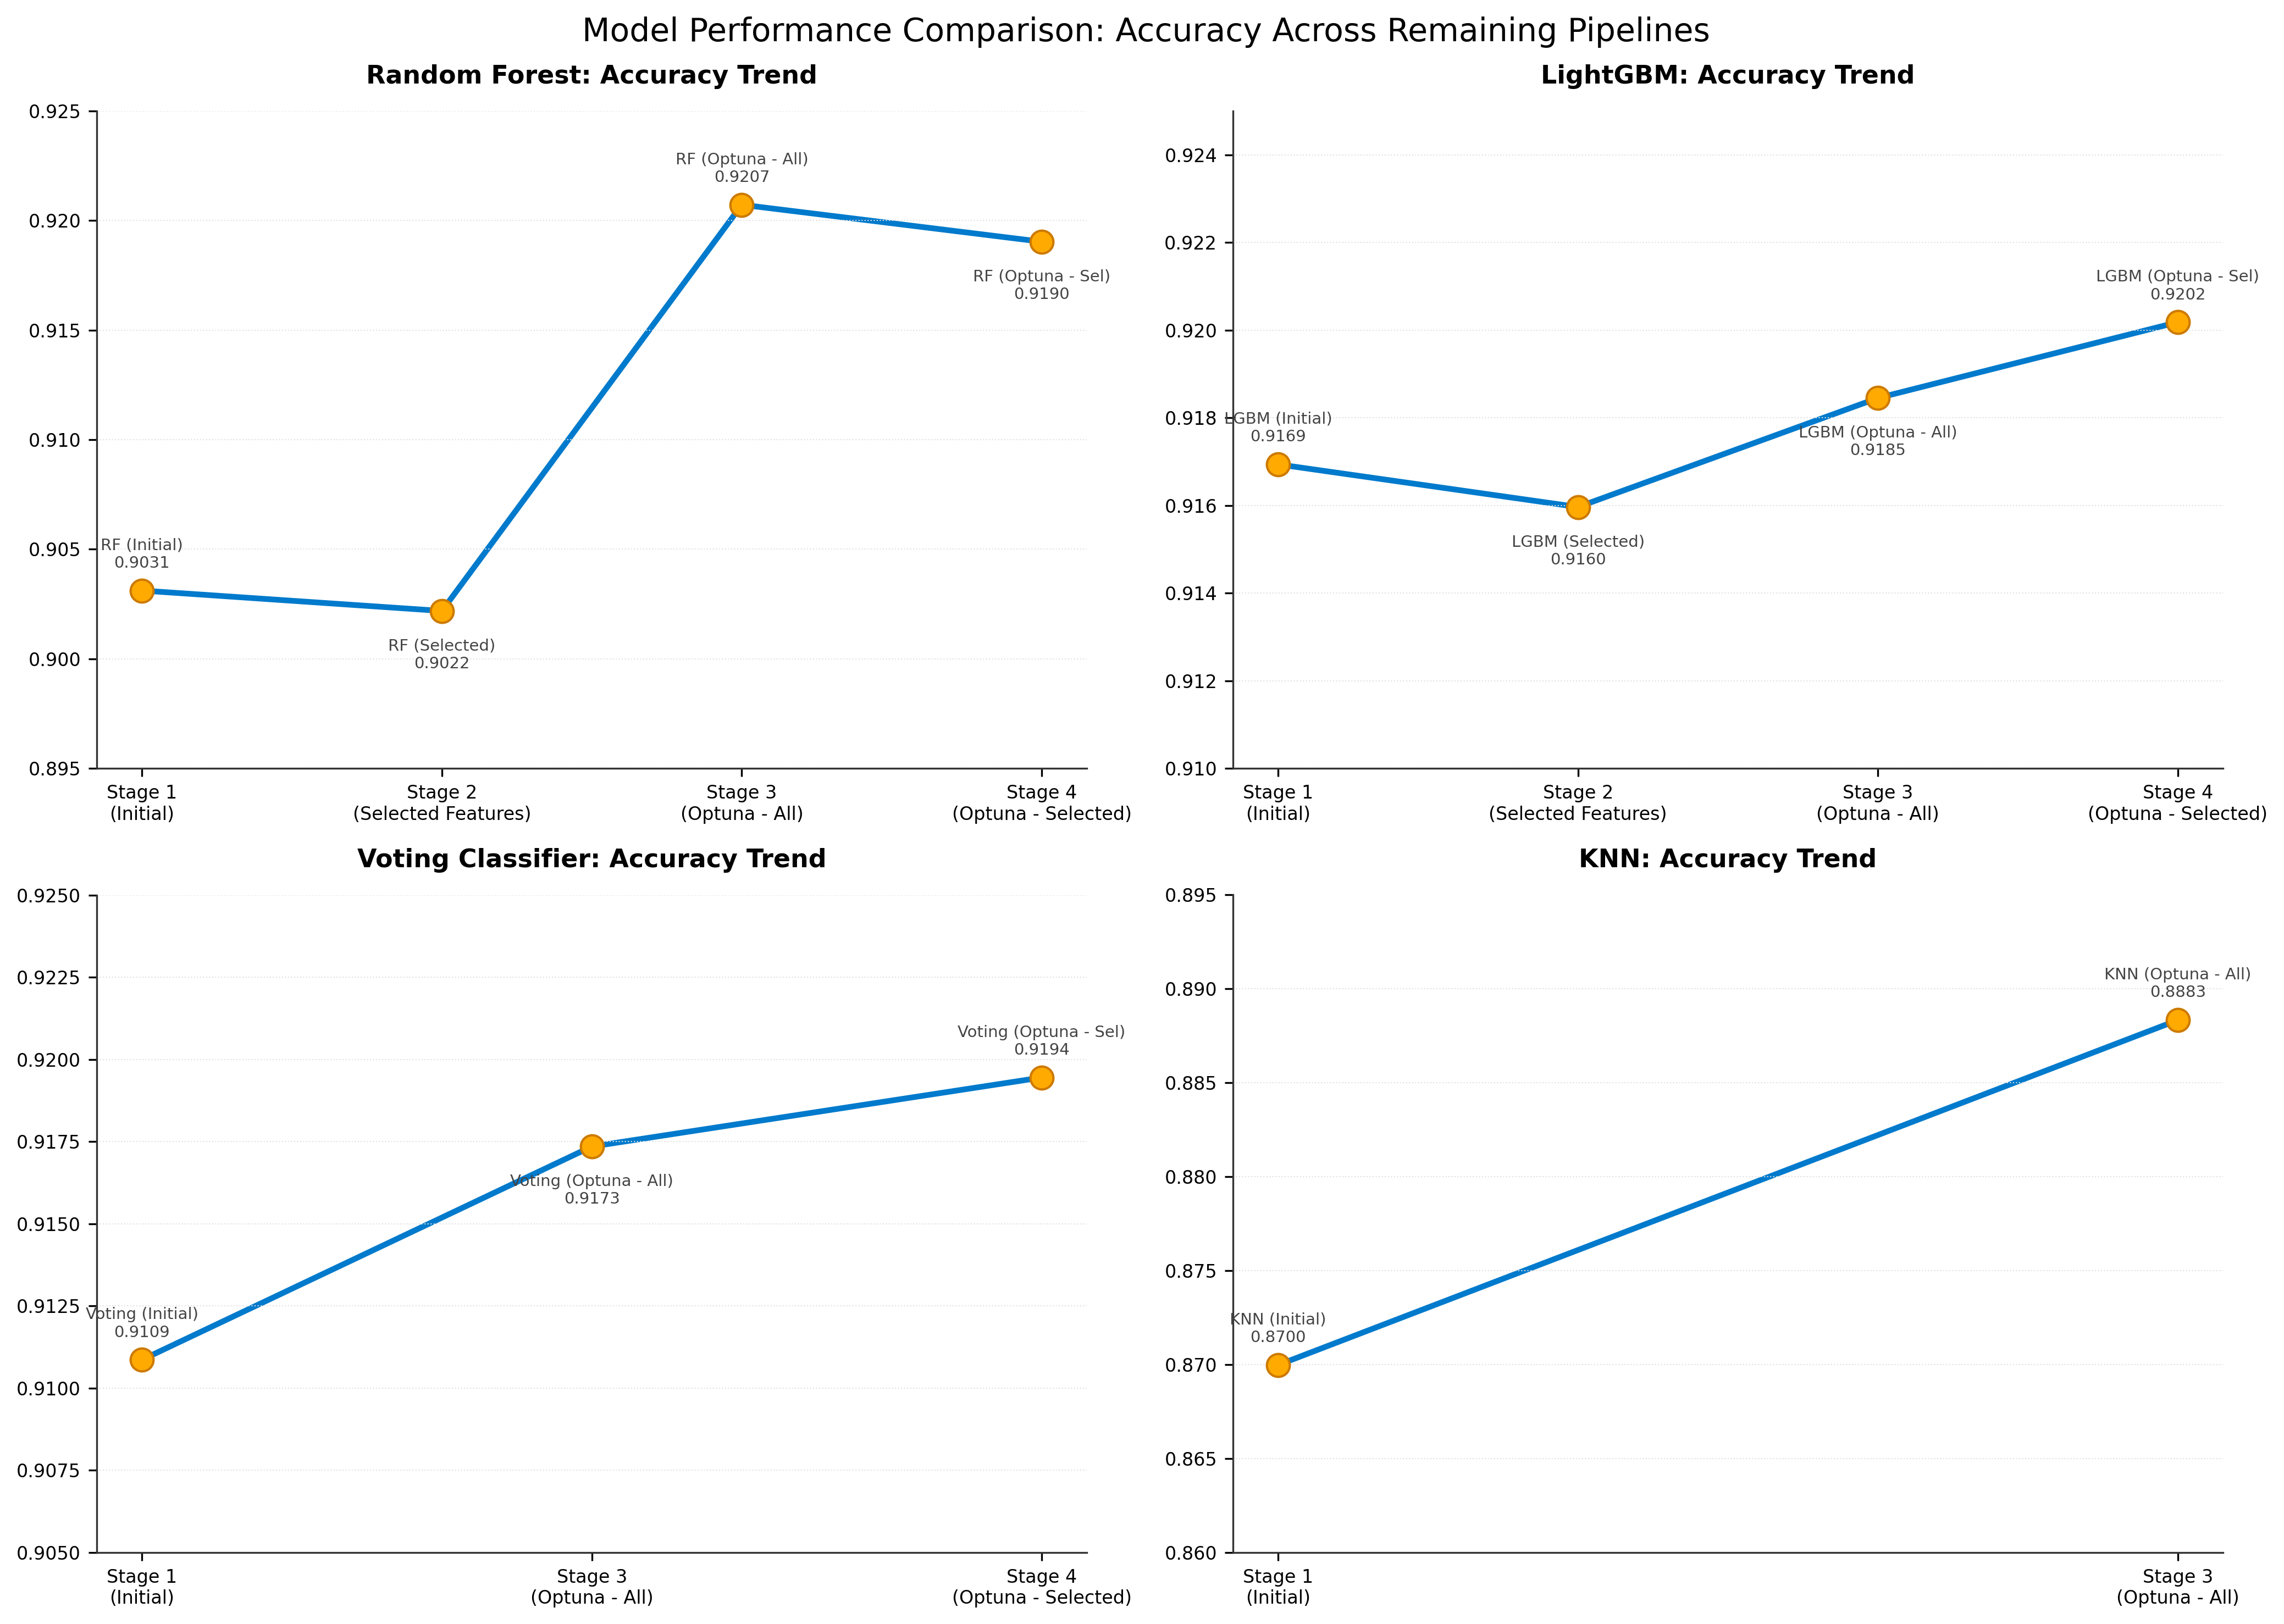

In [ ]:
import matplotlib.pyplot as plt

# 1. Configuration for all remaining models with their exact Accuracy values
models_data = {
    "Random Forest": {
        "stages": ["Stage 1\n(Initial)", "Stage 2\n(Selected Features)", "Stage 3\n(Optuna - All)", "Stage 4\n(Optuna - Selected)"],
        "scores": [0.903115, 0.902185, 0.920722, 0.919035],
        "labels": ["RF (Initial)\n0.9031", "RF (Selected)\n0.9022", "RF (Optuna - All)\n0.9207", "RF (Optuna - Sel)\n0.9190"],
        "ylim": (0.895, 0.925),
        "offsets": [(0, 10), (0, -25), (0, 10), (0, -25)]
    },
    "LightGBM": {
        "stages": ["Stage 1\n(Initial)", "Stage 2\n(Selected Features)", "Stage 3\n(Optuna - All)", "Stage 4\n(Optuna - Selected)"],
        "scores": [0.916937, 0.915964, 0.918451, 0.920182],
        "labels": ["LGBM (Initial)\n0.9169", "LGBM (Selected)\n0.9160", "LGBM (Optuna - All)\n0.9185", "LGBM (Optuna - Sel)\n0.9202"],
        "ylim": (0.910, 0.925),
        "offsets": [(0, 10), (0, -25), (0, -25), (0, 10)]
    },
    "Voting Classifier": {
        "stages": ["Stage 1\n(Initial)", "Stage 3\n(Optuna - All)", "Stage 4\n(Optuna - Selected)", ""],
        # Note: Your table contains 3 variations for Voting Classifier
        "scores": [0.910859, 0.917348, 0.919446],
        "labels": ["Voting (Initial)\n0.9109", "Voting (Optuna - All)\n0.9173", "Voting (Optuna - Sel)\n0.9194"],
        "ylim": (0.905, 0.925),
        "offsets": [(0, 10), (0, -25), (0, 10)]
    },
    "KNN": {
        "stages": ["Stage 1\n(Initial)", "Stage 3\n(Optuna - All)", "", ""],
        # Note: Your table contains 2 variations for KNN
        "scores": [0.869976, 0.888341],
        "labels": ["KNN (Initial)\n0.8700", "KNN (Optuna - All)\n0.8883"],
        "ylim": (0.860, 0.895),
        "offsets": [(0, 10), (0, 10)]
    }
}

# 2. Setup a 2x2 plotting grid
fig, axes = plt.subplots(2, 2, figsize=(14, 10), dpi=300)
axes = axes.flatten()

# 3. Generate charts for each model
for idx, (model_name, data) in enumerate(models_data.items()):
    ax = axes[idx]

    # Slice stages list to match data lengths for uneven datasets (Voting & KNN)
    plot_stages = data["stages"][:len(data["scores"])]

    # Plot line and dots
    ax.plot(plot_stages, data["scores"], color='#007acc', linewidth=2.5, zorder=1)
    ax.scatter(plot_stages, data["scores"], color='#ffaa00', edgecolors='#cc7a00', s=100, zorder=2)

    # Title and bounds
    ax.set_title(f"{model_name}: Accuracy Trend", fontsize=11, fontweight='bold', pad=12)
    ax.set_ylim(data["ylim"])

    # Axis formatting
    ax.grid(axis='y', linestyle=':', linewidth=0.5, color='#e0e0e0')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('#333333')
    ax.spines['bottom'].set_color('#333333')
    ax.tick_params(axis='both', labelsize=8)

    # Add data annotations
    for i, (txt, offset) in enumerate(zip(data["labels"], data["offsets"])):
        ax.annotate(
            txt,
            (plot_stages[i], data["scores"][i]),
            textcoords="offset points",
            xytext=offset,
            ha='center',
            fontsize=7,
            color='#444444'
        )

# 4. Final layout adjustments
plt.suptitle("Model Performance Comparison: Accuracy Across Remaining Pipelines", fontsize=14, y=0.98)
plt.tight_layout()
plt.show()


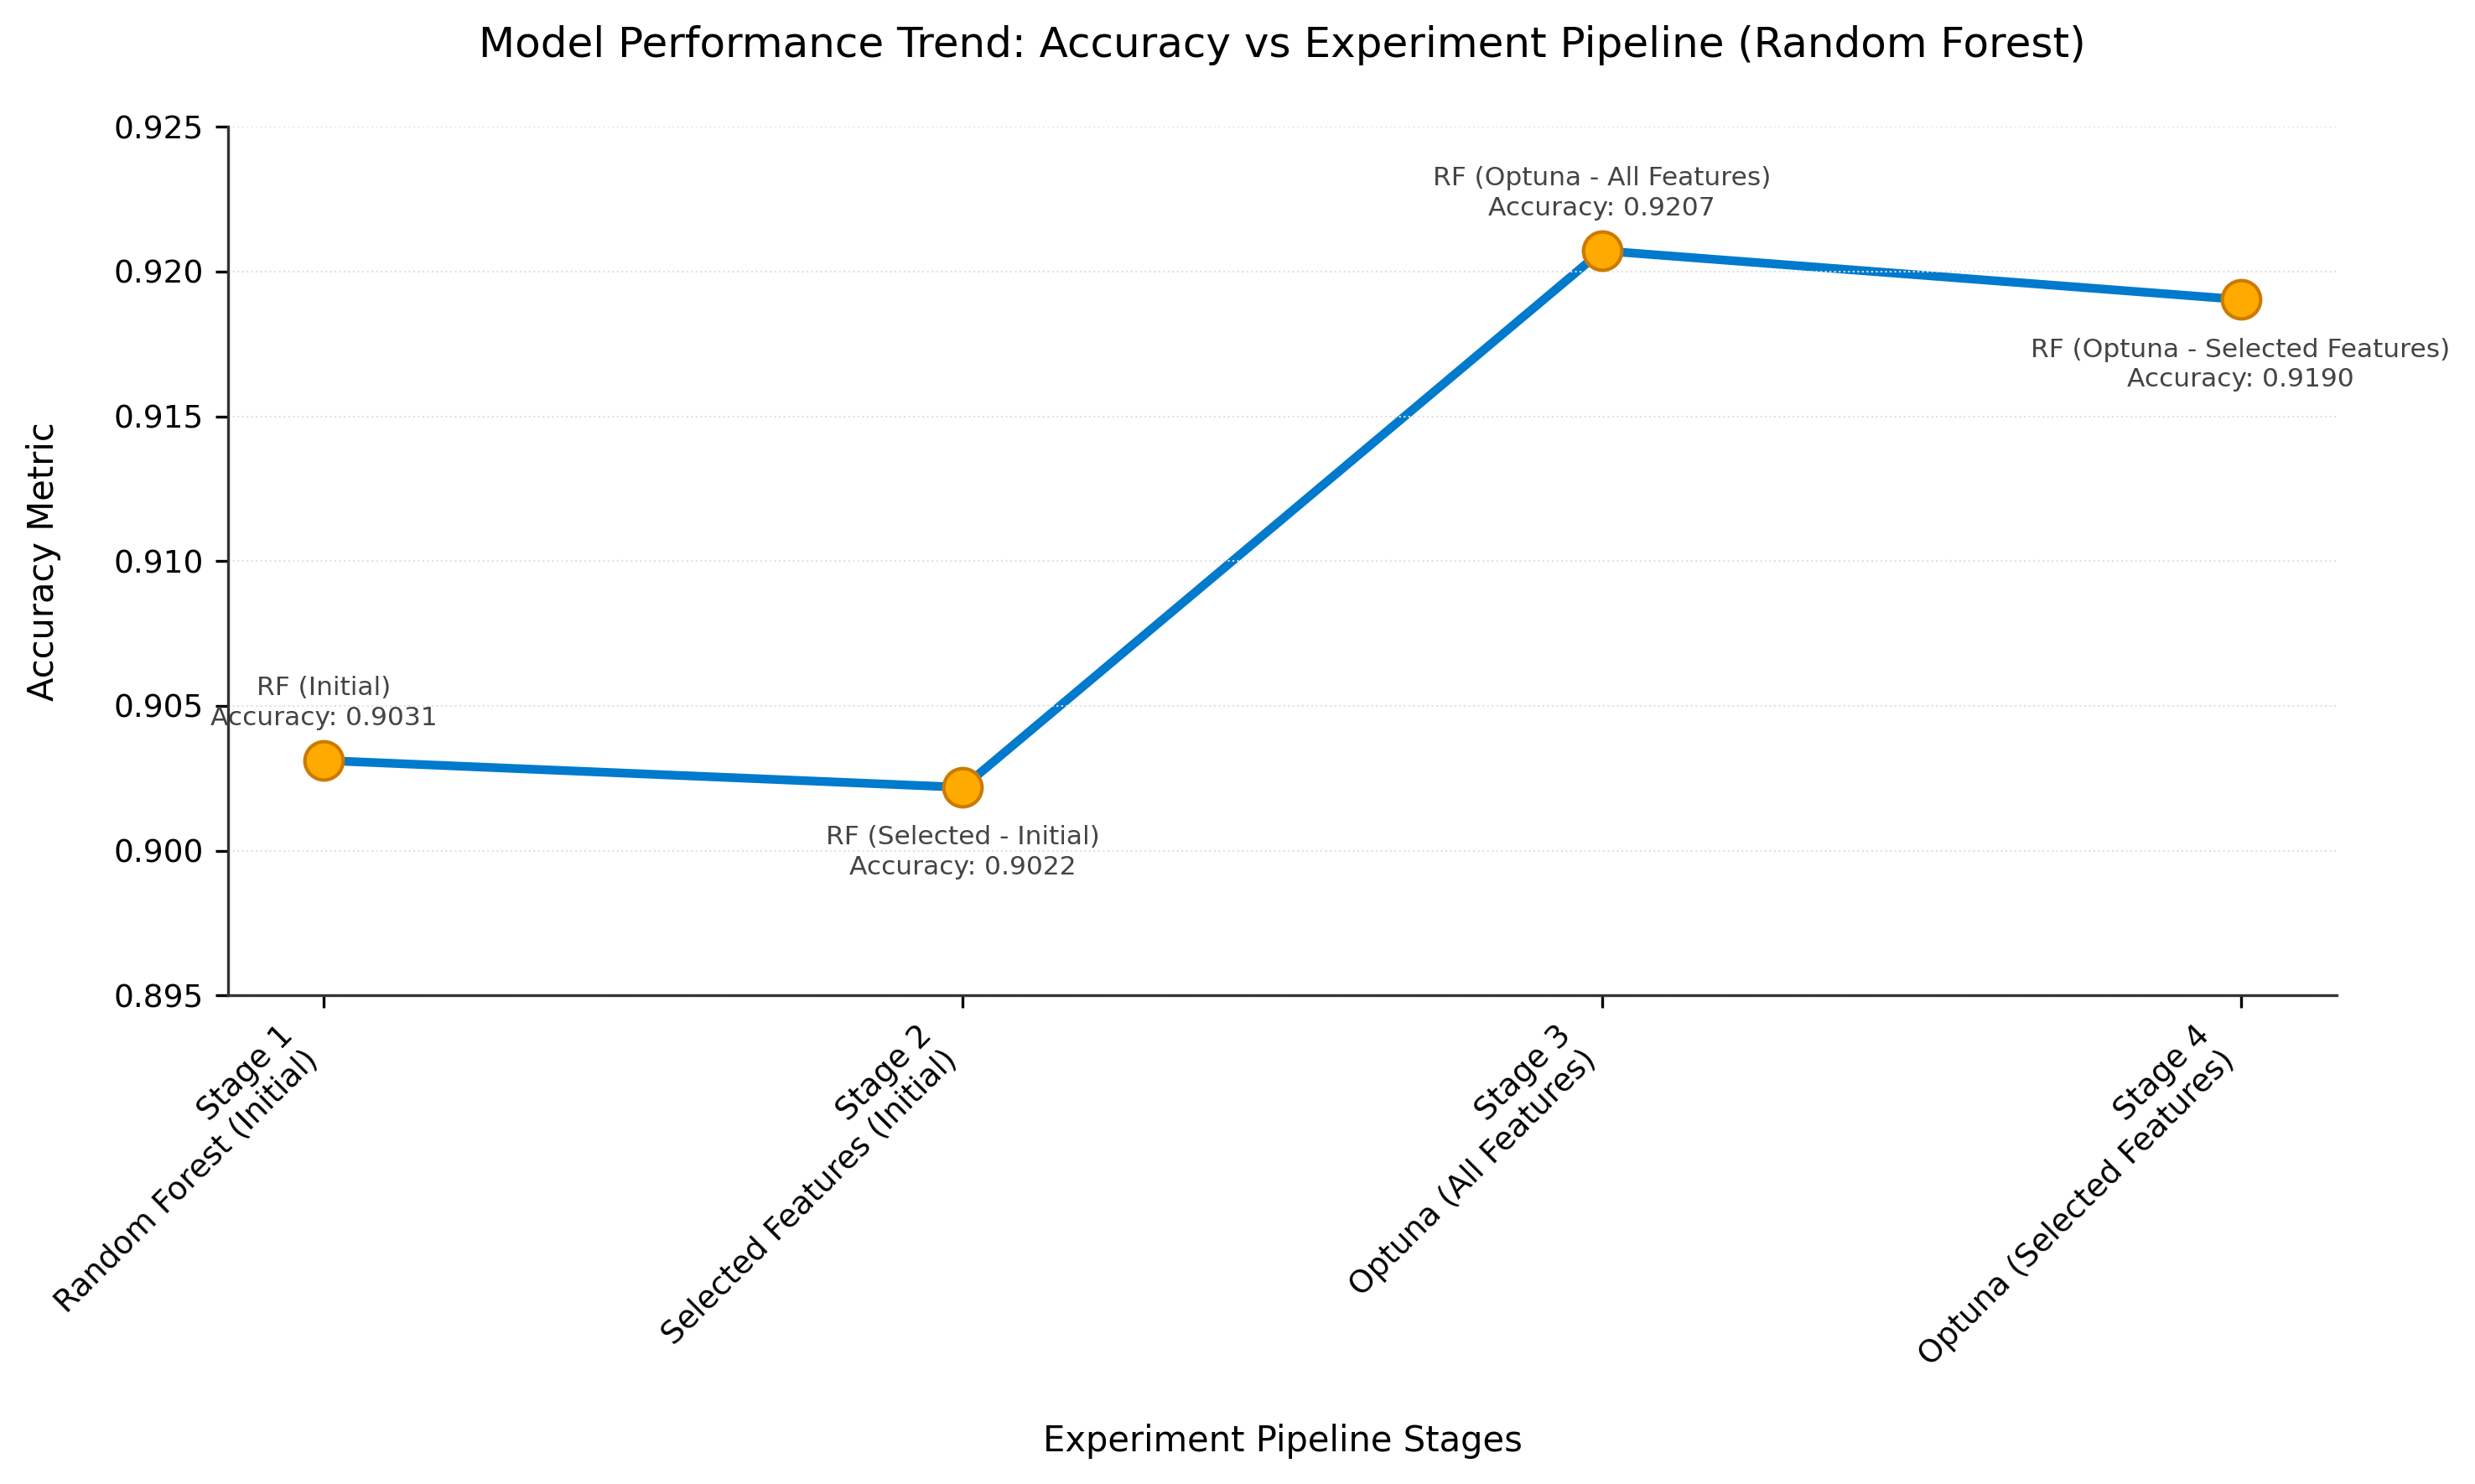

In [ ]:
import matplotlib.pyplot as plt

# 1. Prepare data for Random Forest stages
stages = [
    "Stage 1\nRandom Forest (Initial)",
    "Stage 2\nSelected Features (Initial)",
    "Stage 3\nOptuna (All Features)",
    "Stage 4\nOptuna (Selected Features)"
]

# Extracted Accuracy values for Random Forest from the table
accuracy_scores = [0.903115, 0.902185, 0.920722, 0.919035]

labels = [
    "RF (Initial)\nAccuracy: 0.9031",
    "RF (Selected - Initial)\nAccuracy: 0.9022",
    "RF (Optuna - All Features)\nAccuracy: 0.9207",
    "RF (Optuna - Selected Features)\nAccuracy: 0.9190"
]

# 2. Setup the plot style
fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
ax.set_facecolor('white')
fig.patch.set_facecolor('white')

# 3. Plot the trend line and markers
ax.plot(stages, accuracy_scores, color='#007acc', linewidth=2.5, zorder=1)
ax.scatter(stages, accuracy_scores, color='#ffaa00', edgecolors='#cc7a00', s=120, zorder=2)

# 4. Format axes and labels
ax.set_title("Model Performance Trend: Accuracy vs Experiment Pipeline (Random Forest)",
             fontsize=12, pad=20, fontweight='normal', family='sans-serif')
ax.set_xlabel("Experiment Pipeline Stages", fontsize=10, labelpad=15)
ax.set_ylabel("Accuracy Metric", fontsize=10, labelpad=15)

# Adjust y-axis limits to fit the data range comfortably
ax.set_ylim(0.8950, 0.9250)

# Rotate X-axis labels to match the graph style
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)

# Add light horizontal gridlines
ax.grid(axis='y', linestyle=':', linewidth=0.5, color='#e0e0e0')

# Hide top and right borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#333333')
ax.spines['bottom'].set_color('#333333')

# 5. Text annotation position offsets
offsets = [
    (0, 10),    # Stage 1: Above
    (0, -25),   # Stage 2: Below
    (0, 10),    # Stage 3: Above
    (0, -25)    # Stage 4: Below
]

for i, (txt, offset) in enumerate(zip(labels, offsets)):
    ax.annotate(
        txt,
        (stages[i], accuracy_scores[i]),
        textcoords="offset points",
        xytext=offset,
        ha='center',
        fontsize=7.5,
        color='#444444',
        linespacing=1.3
    )

plt.tight_layout()
plt.show()


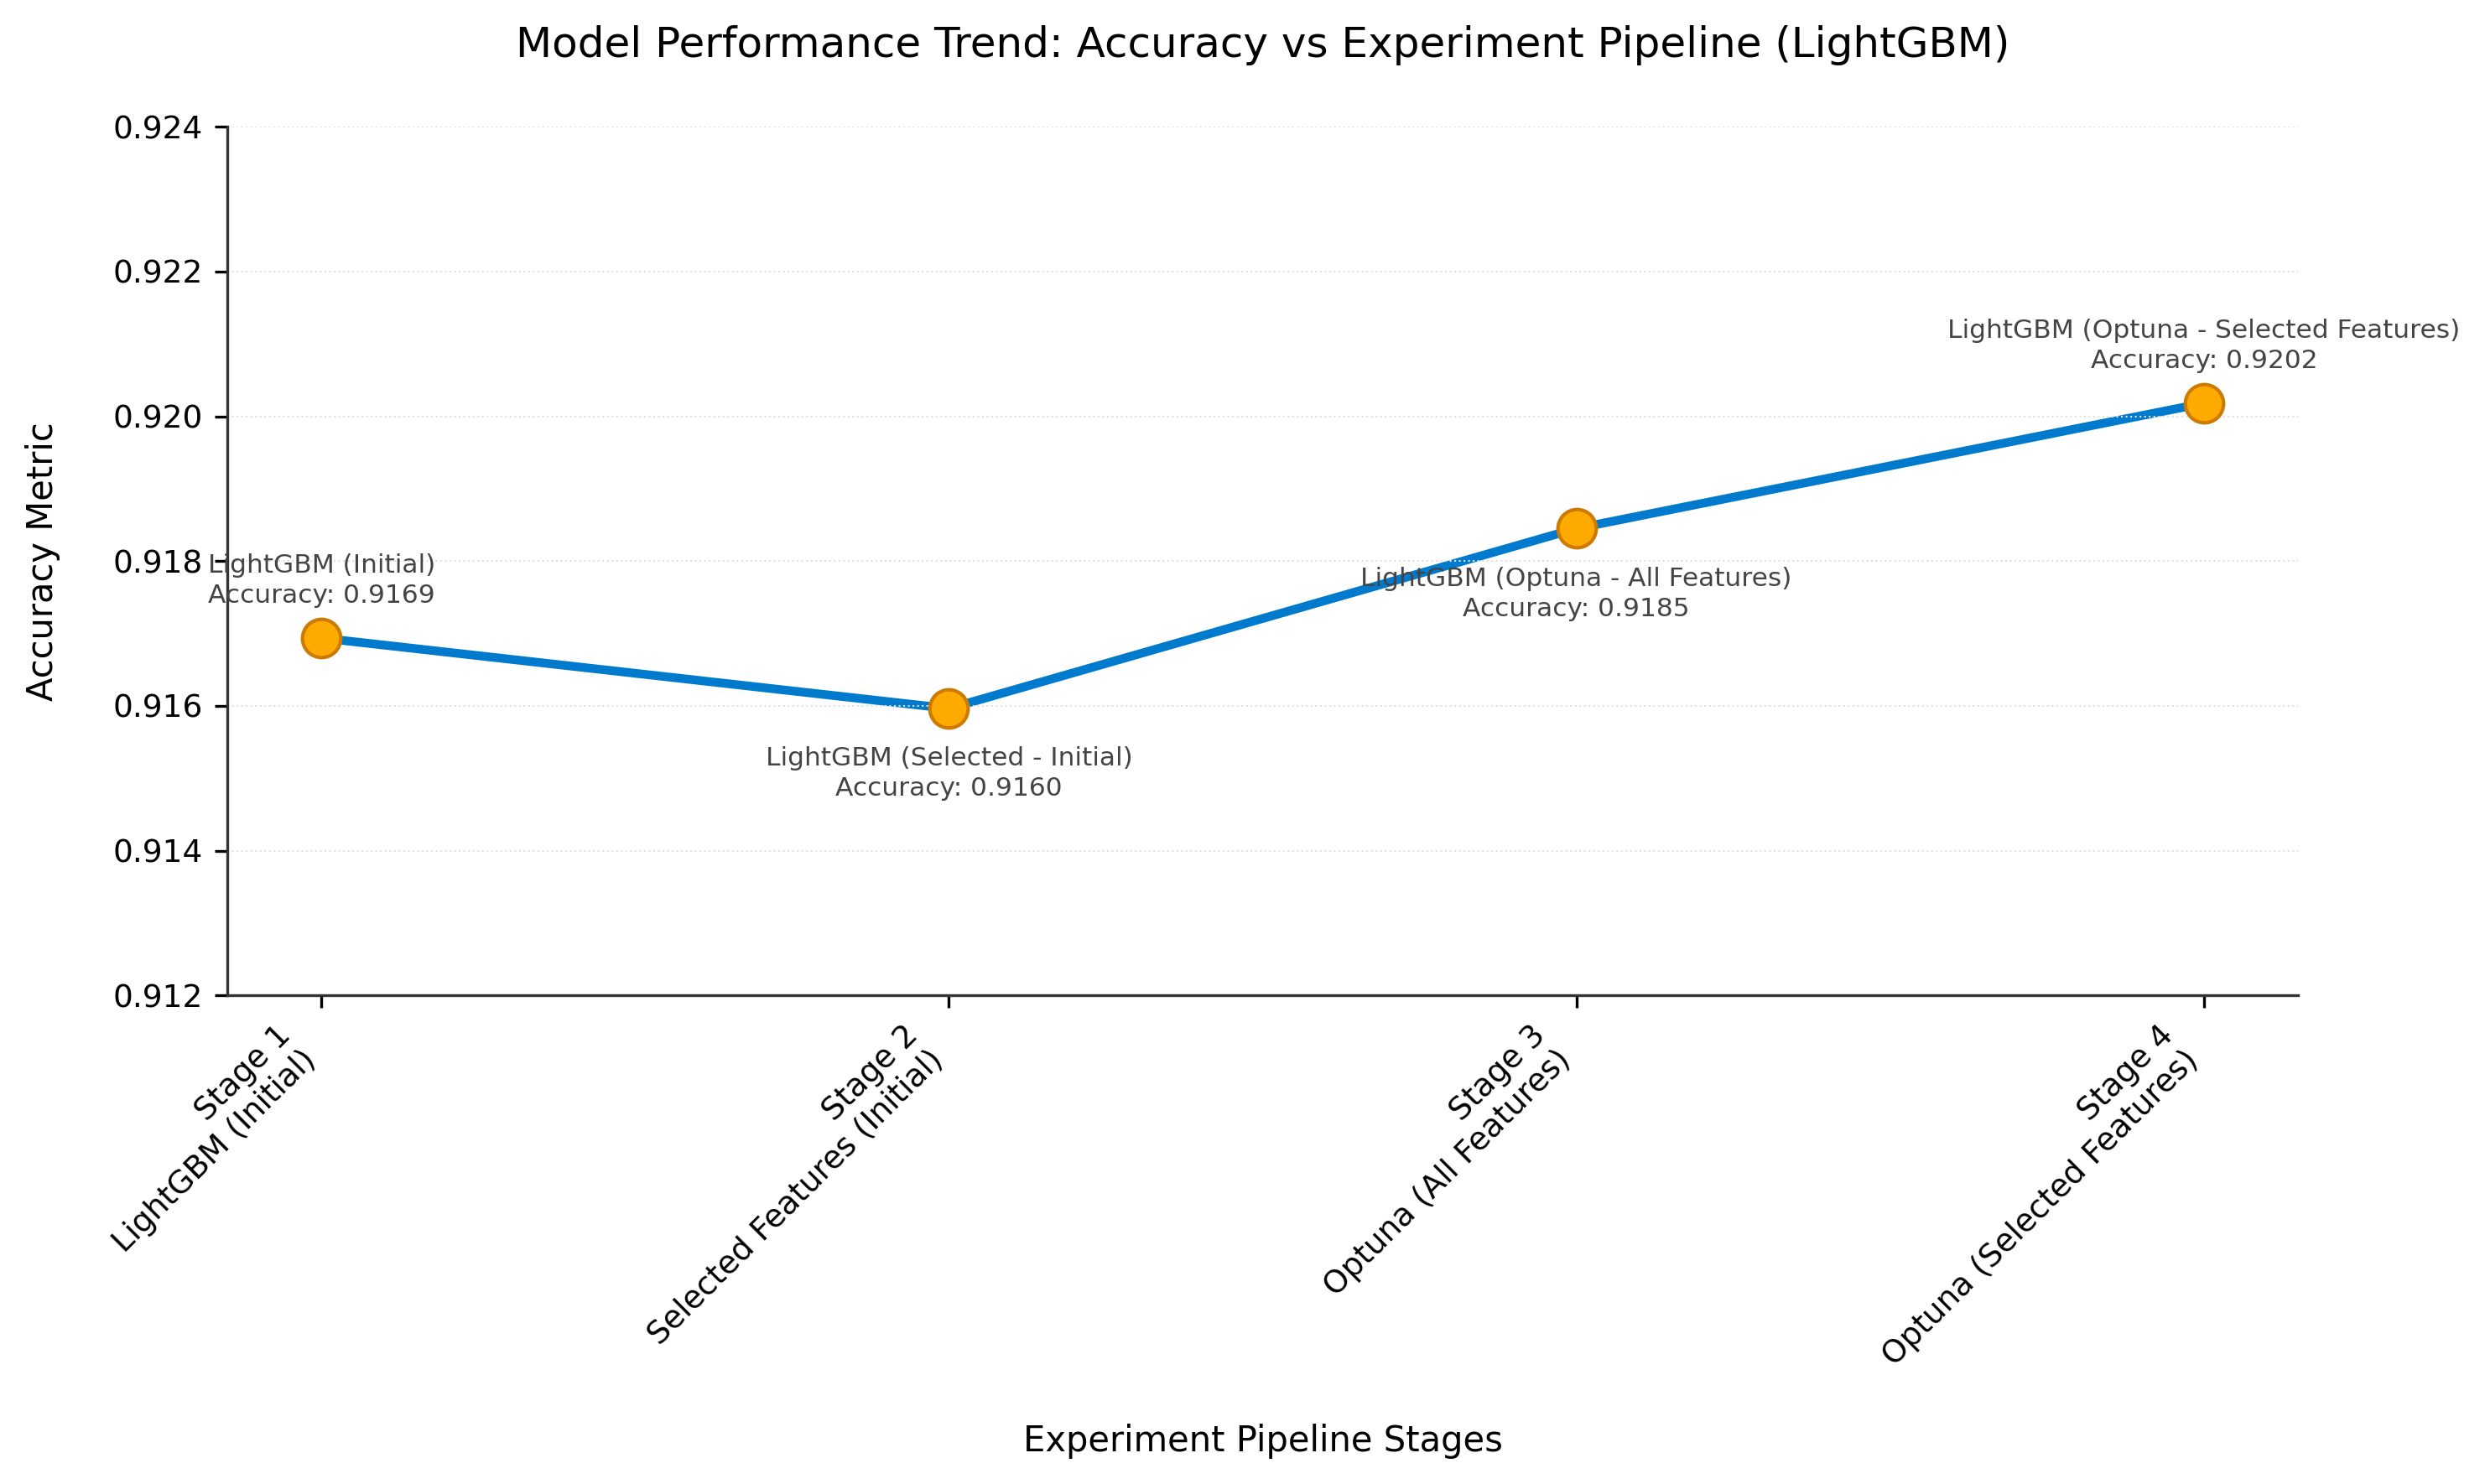

In [ ]:
import matplotlib.pyplot as plt

# 1. Prepare data for LightGBM stages
stages = [
    "Stage 1\nLightGBM (Initial)",
    "Stage 2\nSelected Features (Initial)",
    "Stage 3\nOptuna (All Features)",
    "Stage 4\nOptuna (Selected Features)"
]

# Extracted Accuracy values for LightGBM from the table
accuracy_scores = [0.916937, 0.915964, 0.918451, 0.920182]

labels = [
    "LightGBM (Initial)\nAccuracy: 0.9169",
    "LightGBM (Selected - Initial)\nAccuracy: 0.9160",
    "LightGBM (Optuna - All Features)\nAccuracy: 0.9185",
    "LightGBM (Optuna - Selected Features)\nAccuracy: 0.9202"
]

# 2. Setup the plot style
fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
ax.set_facecolor('white')
fig.patch.set_facecolor('white')

# 3. Plot the trend line and markers
ax.plot(stages, accuracy_scores, color='#007acc', linewidth=2.5, zorder=1)
ax.scatter(stages, accuracy_scores, color='#ffaa00', edgecolors='#cc7a00', s=120, zorder=2)

# 4. Format axes and labels
ax.set_title("Model Performance Trend: Accuracy vs Experiment Pipeline (LightGBM)",
             fontsize=12, pad=20, fontweight='normal', family='sans-serif')
ax.set_xlabel("Experiment Pipeline Stages", fontsize=10, labelpad=15)
ax.set_ylabel("Accuracy Metric", fontsize=10, labelpad=15)

# Adjust y-axis limits to fit the data range comfortably
ax.set_ylim(0.9120, 0.9240)

# Rotate X-axis labels to match the graph style
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)

# Add light horizontal gridlines
ax.grid(axis='y', linestyle=':', linewidth=0.5, color='#e0e0e0')

# Hide top and right borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#333333')
ax.spines['bottom'].set_color('#333333')

# 5. Text annotation position offsets
offsets = [
    (0, 10),    # Stage 1: Above
    (0, -25),   # Stage 2: Below
    (0, -25),   # Stage 3: Below
    (0, 10)     # Stage 4: Above
]

for i, (txt, offset) in enumerate(zip(labels, offsets)):
    ax.annotate(
        txt,
        (stages[i], accuracy_scores[i]),
        textcoords="offset points",
        xytext=offset,
        ha='center',
        fontsize=7.5,
        color='#444444',
        linespacing=1.3
    )

plt.tight_layout()
plt.show()


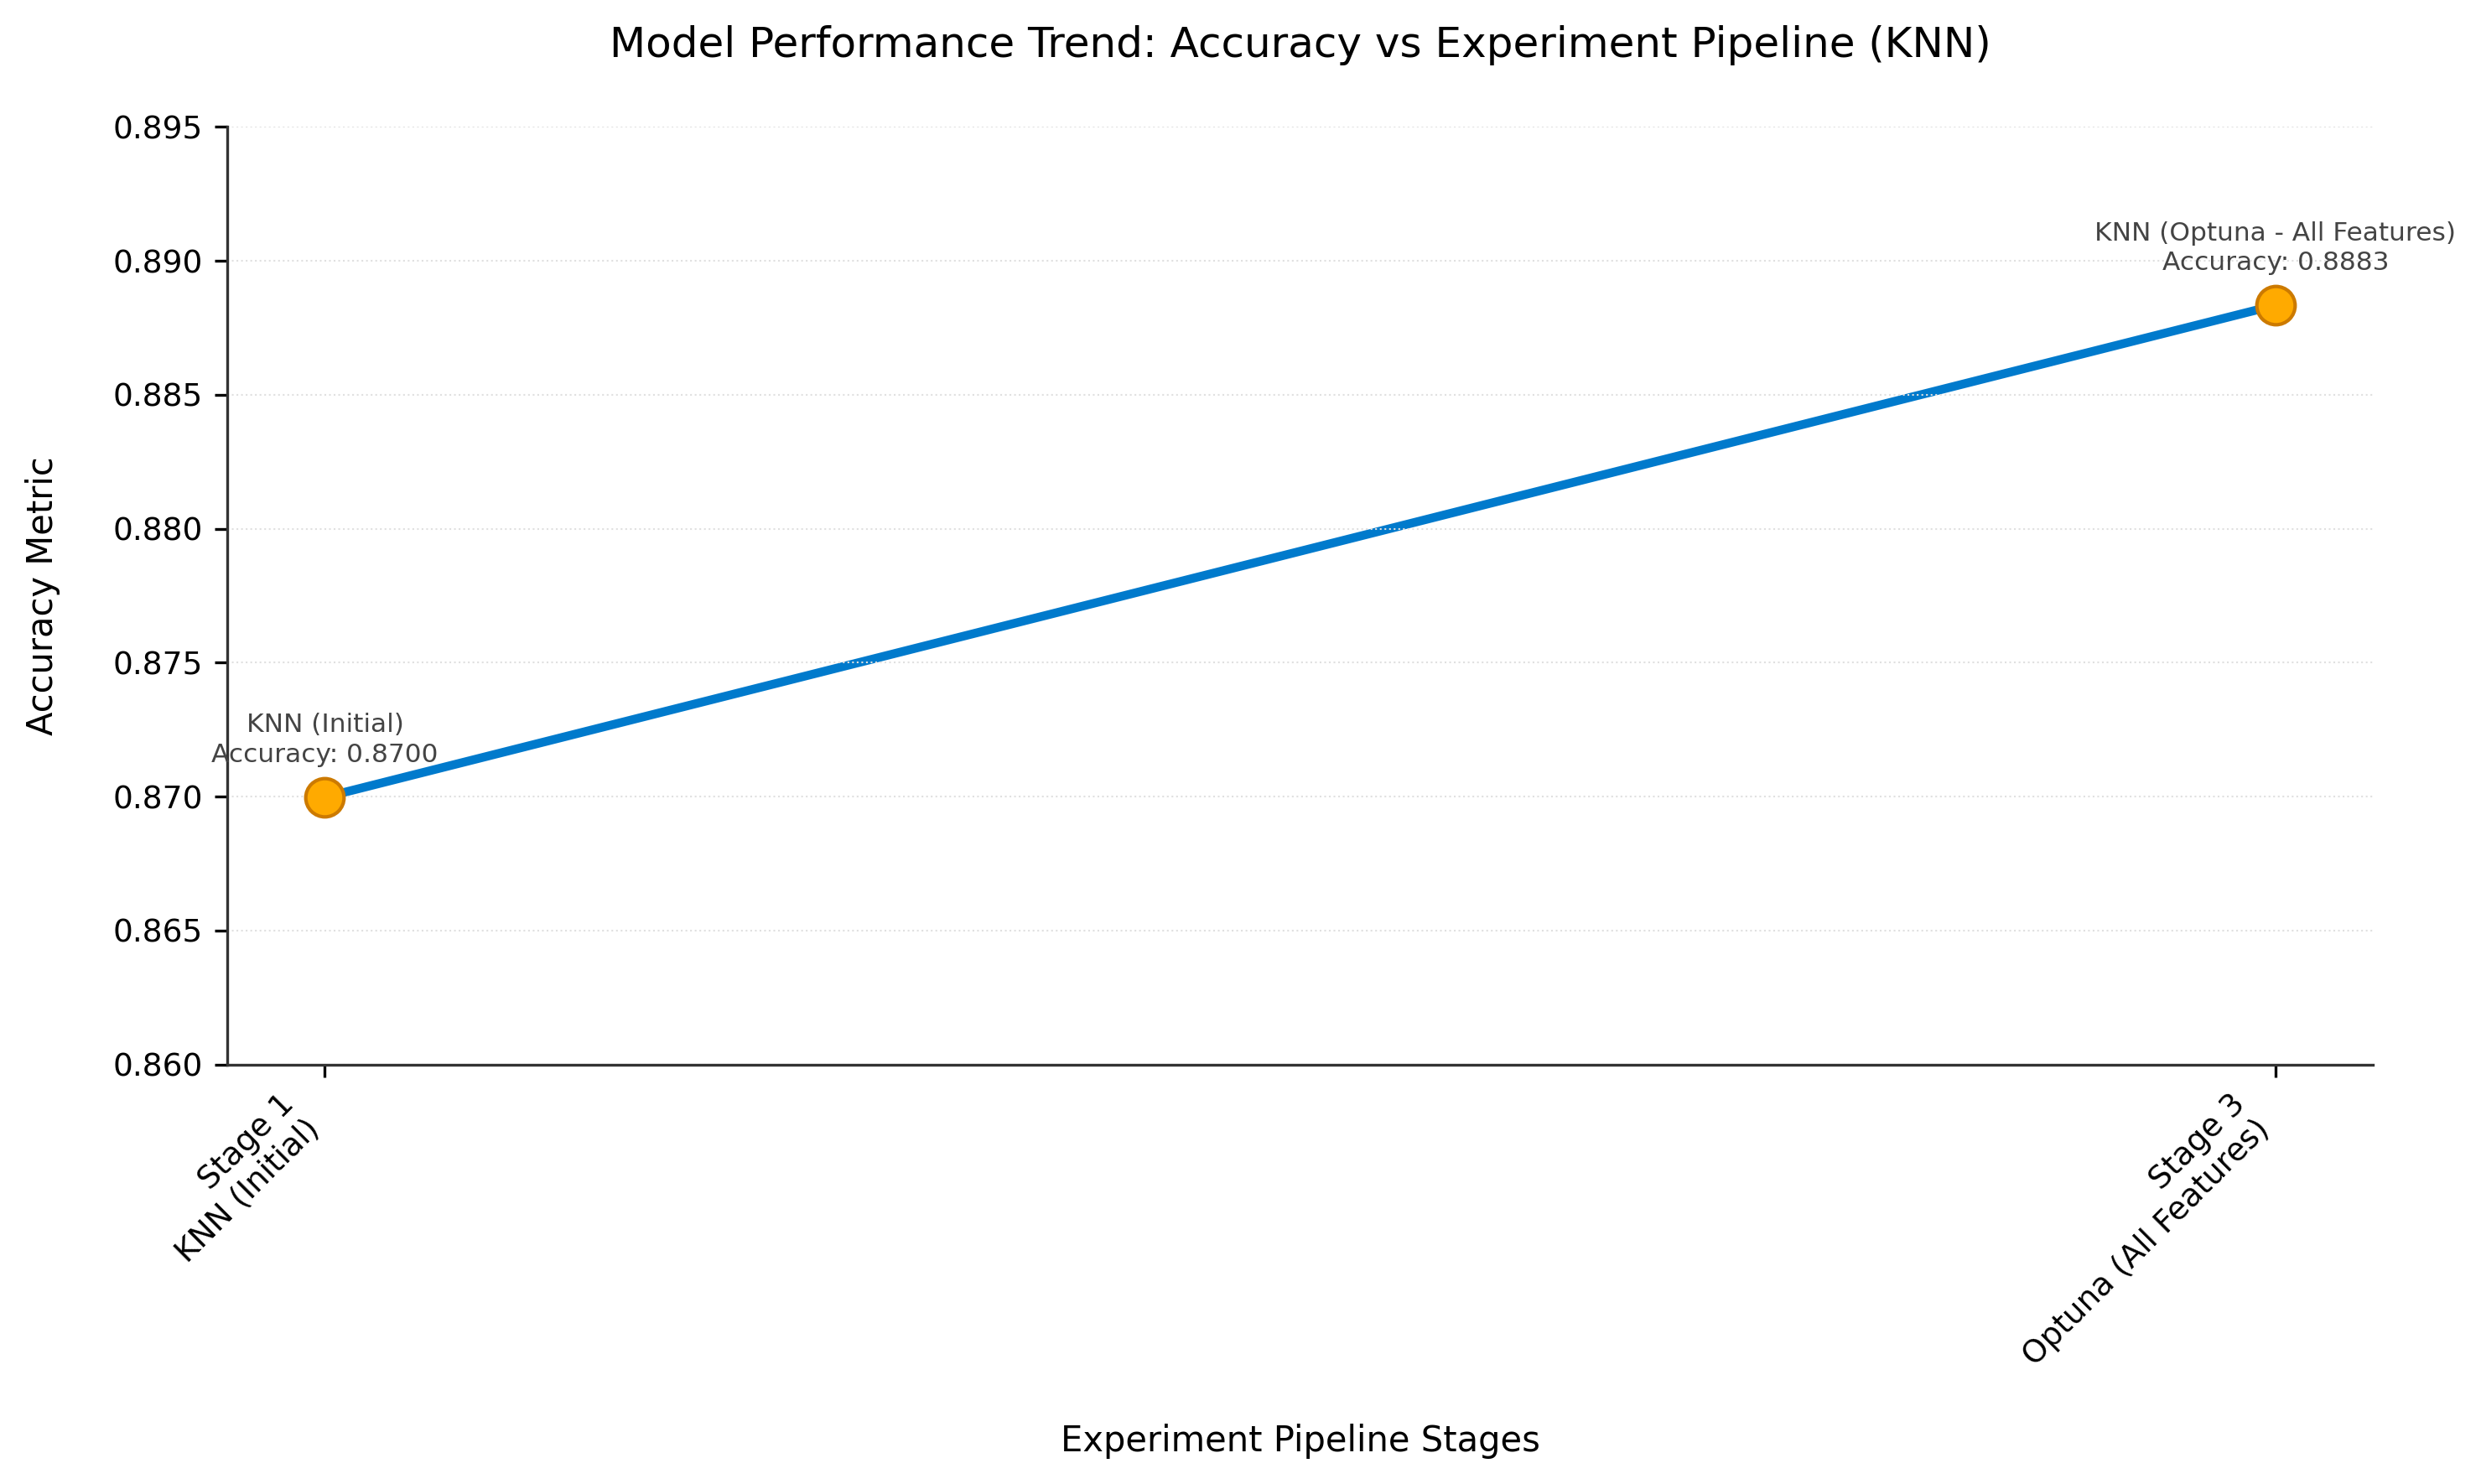

In [ ]:
import matplotlib.pyplot as plt

# 1. Prepare data for KNN stages (2 experimental stages available)
stages = [
    "Stage 1\nKNN (Initial)",
    "Stage 3\nOptuna (All Features)"
]

# Extracted Accuracy values for KNN from the table
accuracy_scores = [0.869976, 0.888341]

labels = [
    "KNN (Initial)\nAccuracy: 0.8700",
    "KNN (Optuna - All Features)\nAccuracy: 0.8883"
]

# 2. Setup the plot style
fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
ax.set_facecolor('white')
fig.patch.set_facecolor('white')

# 3. Plot the trend line and markers
ax.plot(stages, accuracy_scores, color='#007acc', linewidth=2.5, zorder=1)
ax.scatter(stages, accuracy_scores, color='#ffaa00', edgecolors='#cc7a00', s=120, zorder=2)

# 4. Format axes and labels
ax.set_title("Model Performance Trend: Accuracy vs Experiment Pipeline (KNN)",
             fontsize=12, pad=20, fontweight='normal', family='sans-serif')
ax.set_xlabel("Experiment Pipeline Stages", fontsize=10, labelpad=15)
ax.set_ylabel("Accuracy Metric", fontsize=10, labelpad=15)

# Adjust y-axis limits to fit the data range comfortably
ax.set_ylim(0.8600, 0.8950)

# Rotate X-axis labels to match the graph style
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)

# Add light horizontal gridlines
ax.grid(axis='y', linestyle=':', linewidth=0.5, color='#e0e0e0')

# Hide top and right borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#333333')
ax.spines['bottom'].set_color('#333333')

# 5. Text annotation position offsets
offsets = [
    (0, 10),    # Stage 1: Above
    (0, 10)     # Stage 3: Above
]

for i, (txt, offset) in enumerate(zip(labels, offsets)):
    ax.annotate(
        txt,
        (stages[i], accuracy_scores[i]),
        textcoords="offset points",
        xytext=offset,
        ha='center',
        fontsize=7.5,
        color='#444444',
        linespacing=1.3
    )

plt.tight_layout()
plt.show()


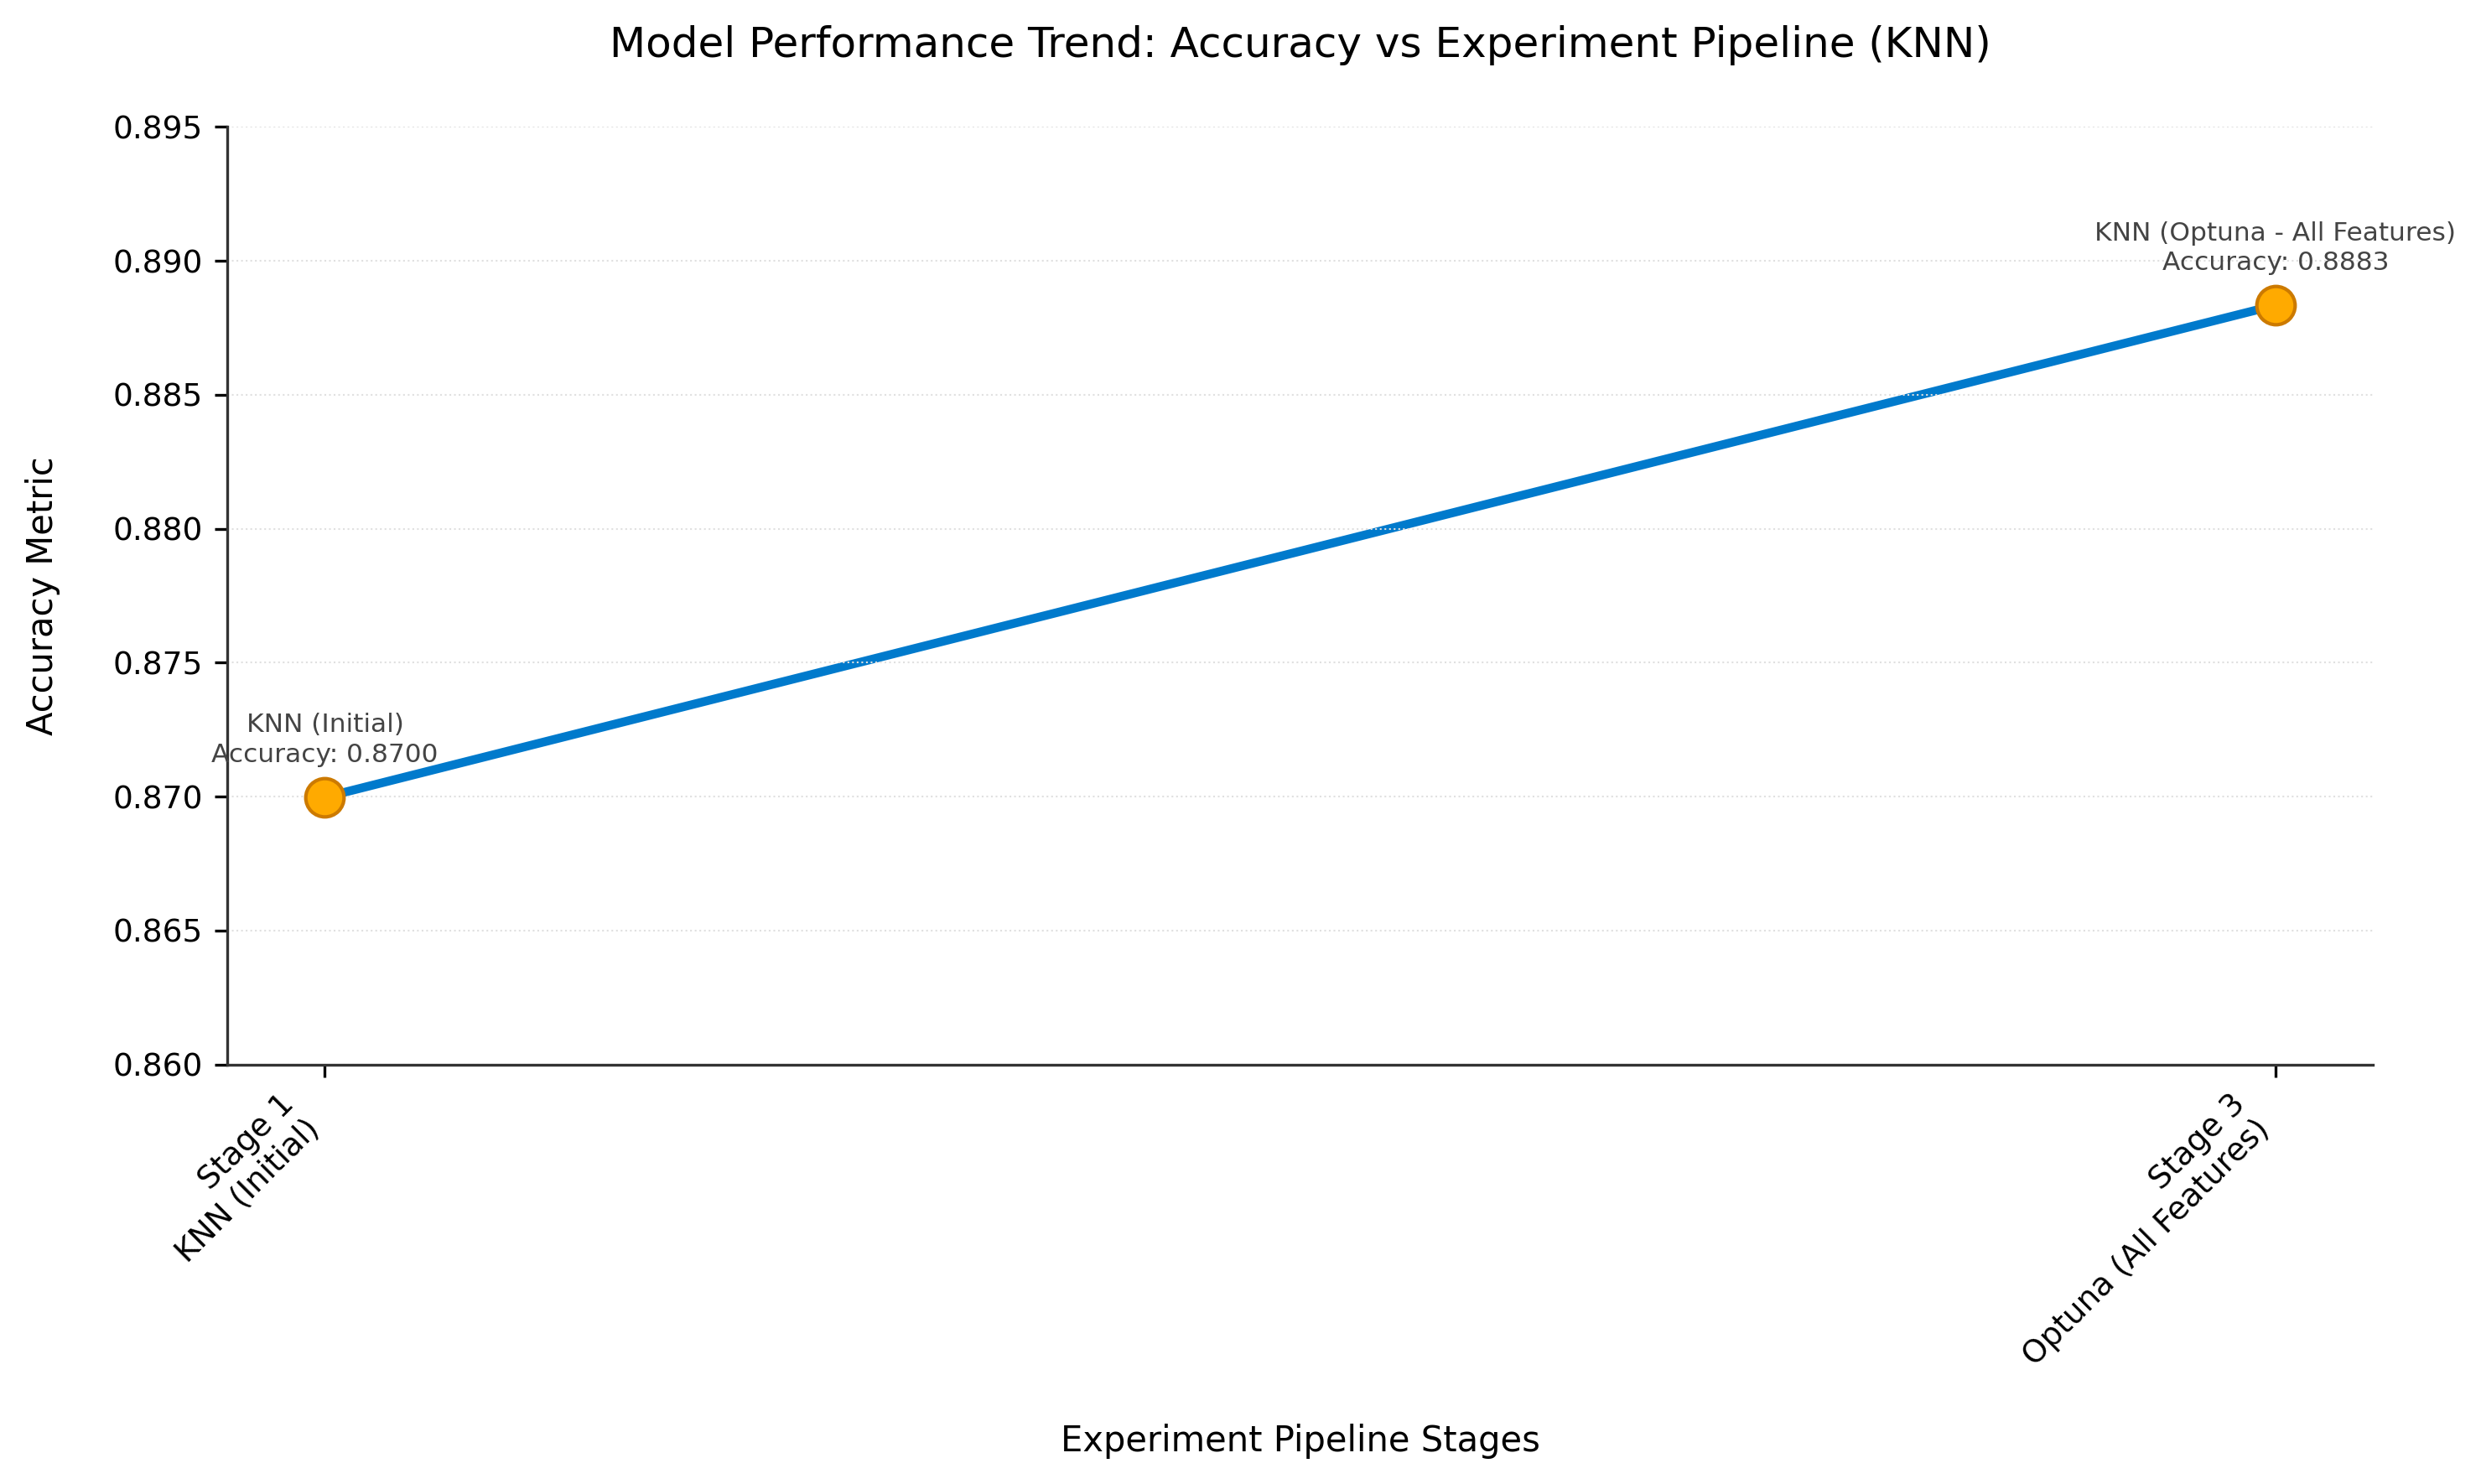

In [ ]:
import matplotlib.pyplot as plt

# 1. Prepare data for KNN stages (2 experimental stages available)
stages = [
    "Stage 1\nKNN (Initial)",
    "Stage 3\nOptuna (All Features)"
]

# Extracted Accuracy values for KNN from the table
accuracy_scores = [0.869976, 0.888341]

labels = [
    "KNN (Initial)\nAccuracy: 0.8700",
    "KNN (Optuna - All Features)\nAccuracy: 0.8883"
]

# 2. Setup the plot style
fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
ax.set_facecolor('white')
fig.patch.set_facecolor('white')

# 3. Plot the trend line and markers
ax.plot(stages, accuracy_scores, color='#007acc', linewidth=2.5, zorder=1)
ax.scatter(stages, accuracy_scores, color='#ffaa00', edgecolors='#cc7a00', s=120, zorder=2)

# 4. Format axes and labels
ax.set_title("Model Performance Trend: Accuracy vs Experiment Pipeline (KNN)",
             fontsize=12, pad=20, fontweight='normal', family='sans-serif')
ax.set_xlabel("Experiment Pipeline Stages", fontsize=10, labelpad=15)
ax.set_ylabel("Accuracy Metric", fontsize=10, labelpad=15)

# Adjust y-axis limits to fit the data range comfortably
ax.set_ylim(0.8600, 0.8950)

# Rotate X-axis labels to match the graph style
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)

# Add light horizontal gridlines
ax.grid(axis='y', linestyle=':', linewidth=0.5, color='#e0e0e0')

# Hide top and right borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#333333')
ax.spines['bottom'].set_color('#333333')

# 5. Text annotation position offsets
offsets = [
    (0, 10),    # Stage 1: Above
    (0, 10)     # Stage 3: Above
]

for i, (txt, offset) in enumerate(zip(labels, offsets)):
    ax.annotate(
        txt,
        (stages[i], accuracy_scores[i]),
        textcoords="offset points",
        xytext=offset,
        ha='center',
        fontsize=7.5,
        color='#444444',
        linespacing=1.3
    )

plt.tight_layout()
plt.show()


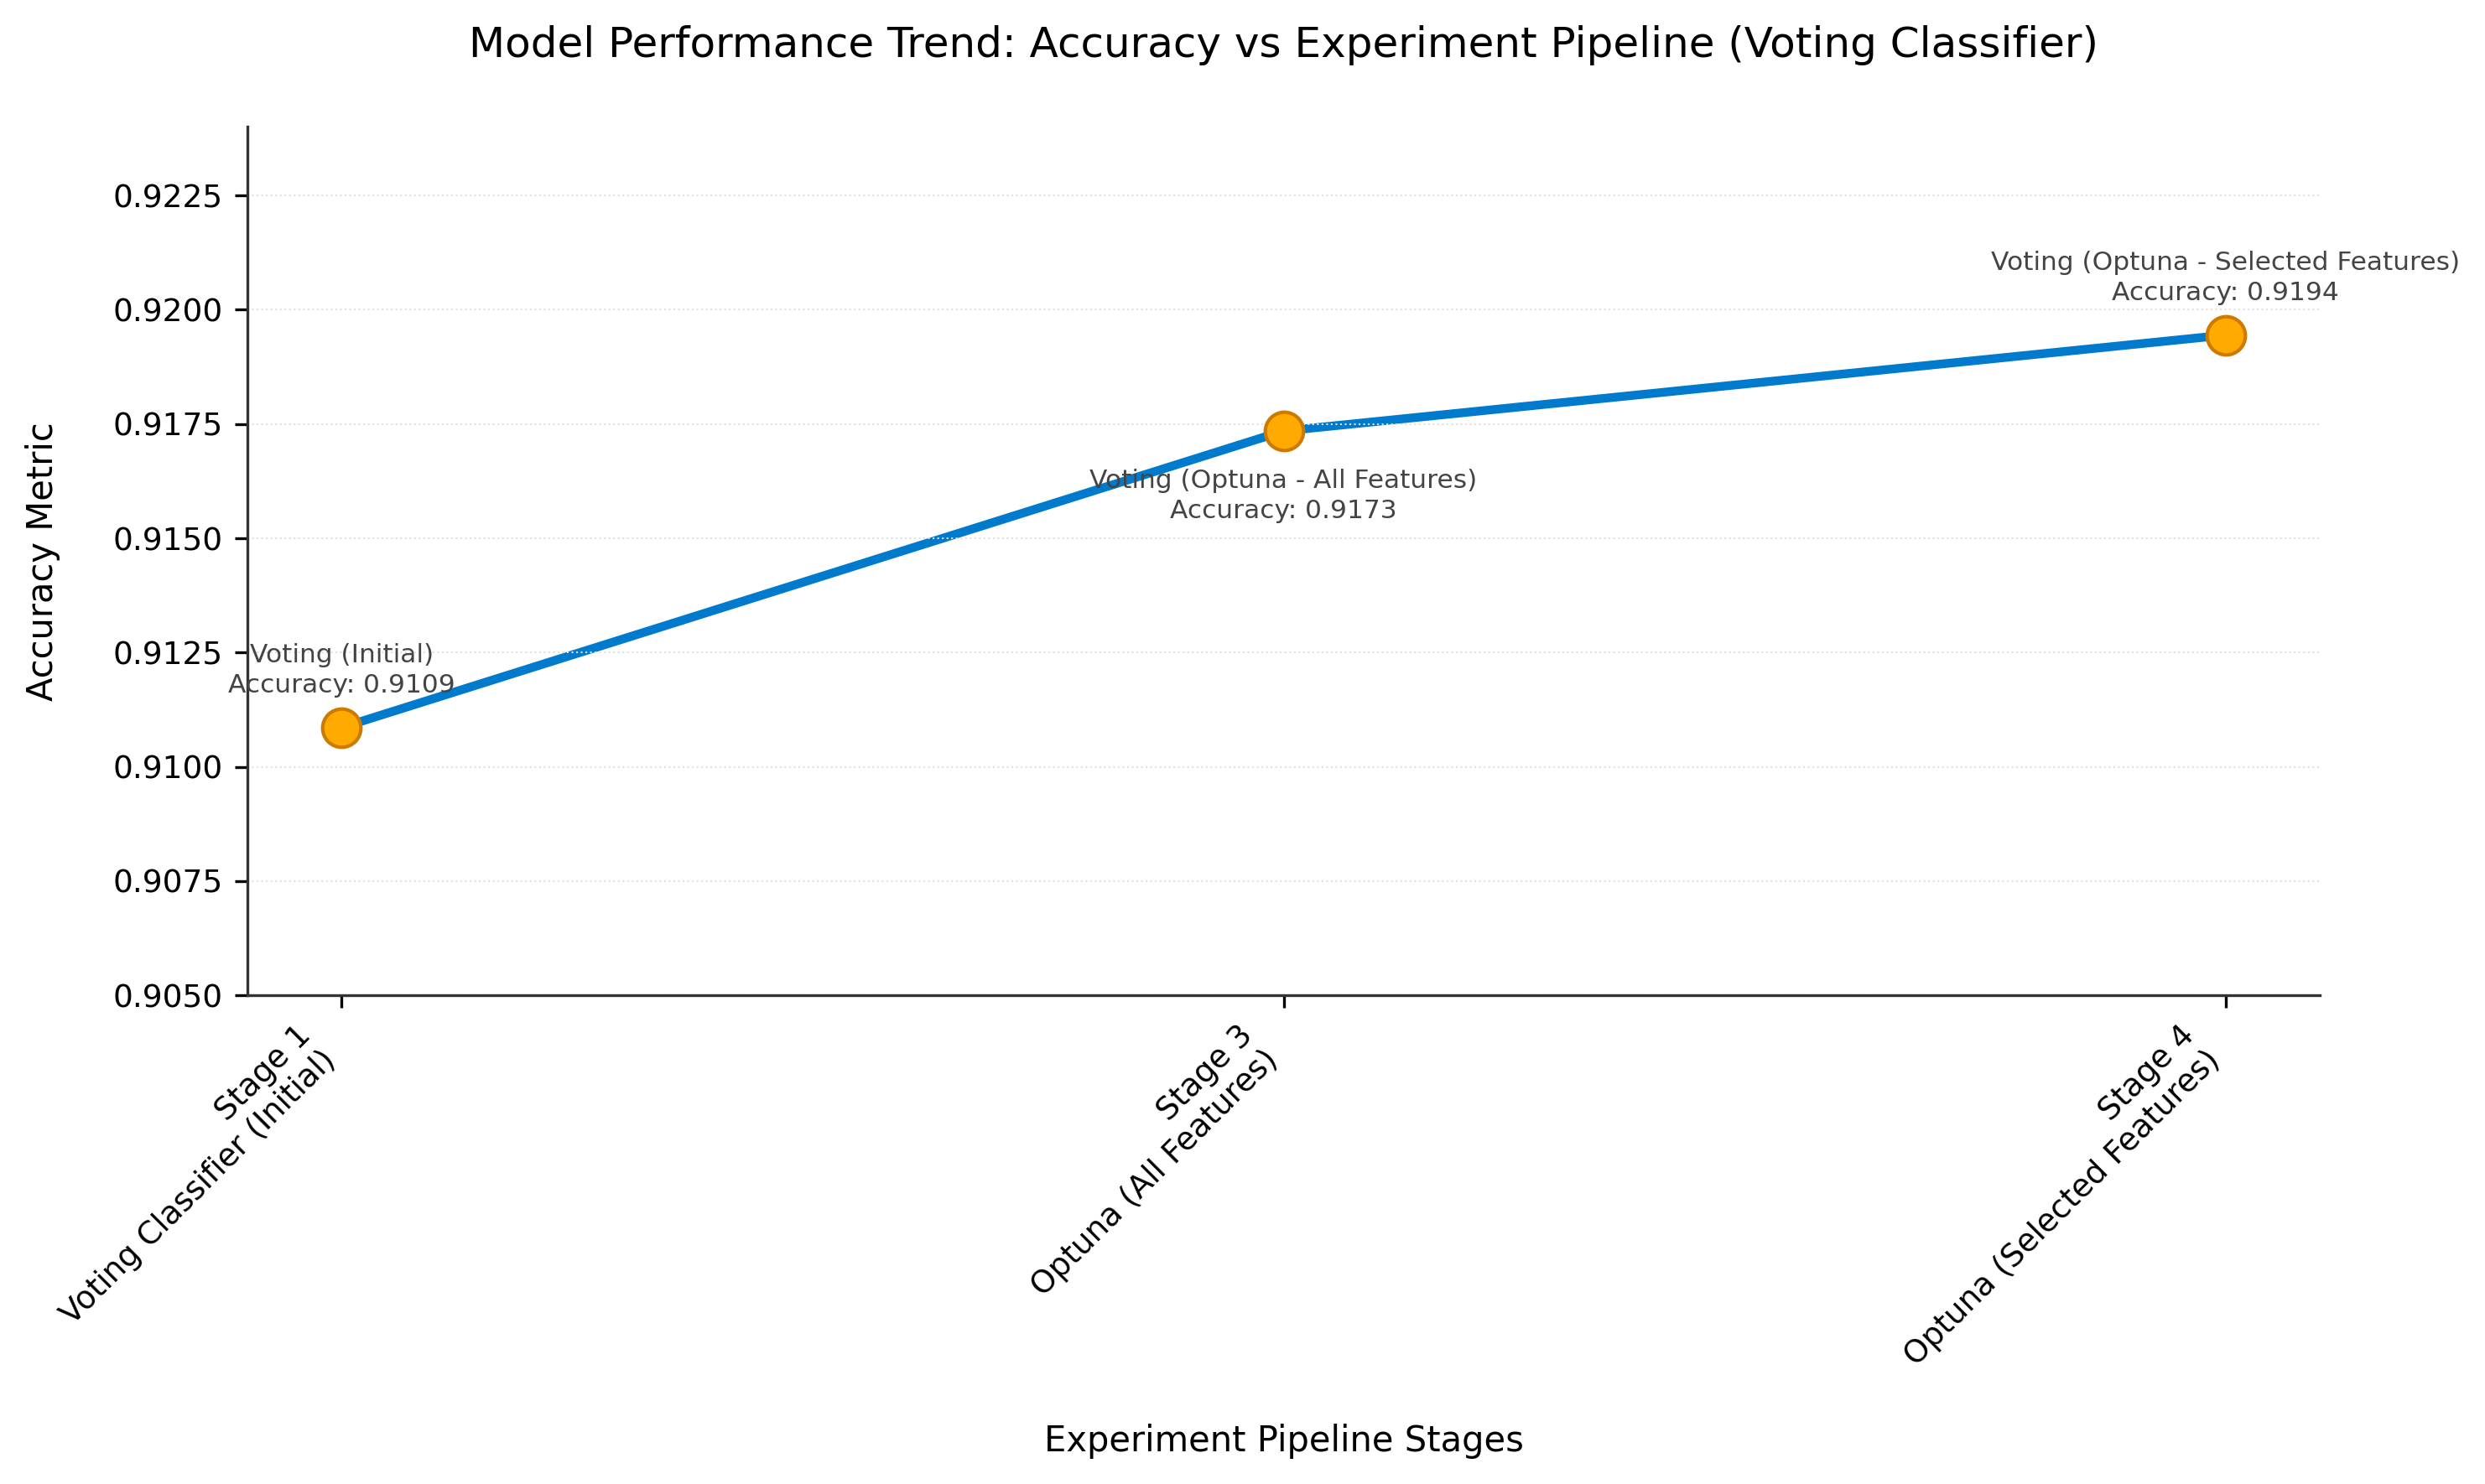

In [ ]:
import matplotlib.pyplot as plt

# 1. Prepare data for Voting Classifier stages (3 experimental stages available)
stages = [
    "Stage 1\nVoting Classifier (Initial)",
    "Stage 3\nOptuna (All Features)",
    "Stage 4\nOptuna (Selected Features)"
]

# Extracted Accuracy values for Voting Classifier from the table
accuracy_scores = [0.910859, 0.917348, 0.919446]

labels = [
    "Voting (Initial)\nAccuracy: 0.9109",
    "Voting (Optuna - All Features)\nAccuracy: 0.9173",
    "Voting (Optuna - Selected Features)\nAccuracy: 0.9194"
]

# 2. Setup the plot style
fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
ax.set_facecolor('white')
fig.patch.set_facecolor('white')

# 3. Plot the trend line and markers
ax.plot(stages, accuracy_scores, color='#007acc', linewidth=2.5, zorder=1)
ax.scatter(stages, accuracy_scores, color='#ffaa00', edgecolors='#cc7a00', s=120, zorder=2)

# 4. Format axes and labels
ax.set_title("Model Performance Trend: Accuracy vs Experiment Pipeline (Voting Classifier)",
             fontsize=12, pad=20, fontweight='normal', family='sans-serif')
ax.set_xlabel("Experiment Pipeline Stages", fontsize=10, labelpad=15)
ax.set_ylabel("Accuracy Metric", fontsize=10, labelpad=15)

# Adjust y-axis limits to fit the data range comfortably
ax.set_ylim(0.9050, 0.9240)

# Rotate X-axis labels to match the graph style
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)

# Add light horizontal gridlines
ax.grid(axis='y', linestyle=':', linewidth=0.5, color='#e0e0e0')

# Hide top and right borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#333333')
ax.spines['bottom'].set_color('#333333')

# 5. Text annotation position offsets
offsets = [
    (0, 10),    # Stage 1: Above
    (0, -25),   # Stage 3: Below
    (0, 10)     # Stage 4: Above
]

for i, (txt, offset) in enumerate(zip(labels, offsets)):
    ax.annotate(
        txt,
        (stages[i], accuracy_scores[i]),
        textcoords="offset points",
        xytext=offset,
        ha='center',
        fontsize=7.5,
        color='#444444',
        linespacing=1.3
    )

plt.tight_layout()
plt.show()
